# Load a single event and plot it

In [24]:
from itertools import groupby
import os,random,warnings,sys,io,re, json,glob,ast
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.signal import find_peaks
from scipy.ndimage import median_filter
import numpy as np
import pandas as pd
from pathlib import Path
import math
import tifffile
# Ignore all warnings
warnings.filterwarnings("ignore")
sys.path.append('/home/giacomomastella/Documents/BigBiax/Code/')
sys.path.append('/home/giacomomastella/Documents/BigBiax/Code/previous/')
from Utilities import *
from Big_biax_block import *
from Utilities_photron import *

def compute_aic_fast(signal):
    """
    Computes the Akaike Information Criterion (AIC) for a signal trace using 
    a highly optimized vectorized approach.
    
    This function splits the signal at every possible index 'k' and calculates 
    the variance of the two resulting segments to find the point where the 
    statistical properties change (the optimal pick time).

    Parameters
    ----------
    signal : numpy.ndarray
        The input signal segment (usually centered around an onset).

    Returns
    -------
    aic : numpy.ndarray
        The AIC curve. The global minimum typically represents the 
        precise arrival time of the wave.
    """
    N = len(signal)
    
    # Safety check: AIC requires a minimum number of samples for statistical validity
    if N < 10: 
        return np.zeros(N)
    
    # --- Vectorized Variance Calculation ---
    # We use cumulative sums (cumsum) of the signal and its square to calculate 
    # running variances without using slow Python loops.
    s = np.cumsum(signal)
    s2 = np.cumsum(signal**2)
    
    # Array of indices from 1 to N-1
    k = np.arange(1, N)
    
    # Calculate variance for the 'left' segment (from start to k)
    # var = E[X^2] - (E[X])^2
    var1 = np.maximum((s2[:-1] / k) - (s[:-1] / k)**2, 1e-12)
    
    # Calculate variance for the 'right' segment (from k to end)
    num_back = N - k
    var2 = np.maximum(((s2[-1] - s2[:-1]) / num_back) - ((s[-1] - s[:-1]) / num_back)**2, 1e-12)
    
    # --- AIC Formula ---
    # AIC(k) = k * log(var(signal[0:k])) + (N-k-1) * log(var(signal[k:N]))
    aic = np.zeros(N)
    
    # Compute AIC for all indices except the boundaries
    aic[1:-1] = k[:-1] * np.log(var1[:-1]) + (N - k[:-1] - 1) * np.log(var2[:-1])
    
    # Penalize boundaries to ensure the minimum is found within the signal body
    aic[0] = aic[-1] = aic[1:-1].max()
    
    return aic

# --- 2. CALCOLO PICKING (SENZA PLOT - ISTANTANEO) ---

def get_picks_only(data_chunk, fs, channel_ids, sta_sec=0.0002, lta_sec=0.1, thr_on=5, thr_off=3, AIC_window=0.001):
    """
    Performs fast, production-grade event picking using STA/LTA and AIC refinement 
    without generating any plots, optimized for speed and real-time processing.
    Supports both float values and dictionaries for per-channel parameter configuration.

    Parameters
    ----------
    data_chunk : numpy.ndarray
        Input signal data with shape (n_channels, n_samples).
    fs : float
        Sampling frequency in Hz.
    channel_ids : list
        List of identifiers/labels for each channel.
    sta_sec : float or dict, optional
        Short-Term Average window in seconds. Can be float or dict {'CH_NAME': val, 'DEFAULT': default_val}.
    lta_sec : float or dict, optional
        Long-Term Average window in seconds. Can be float or dict {'CH_NAME': val, 'DEFAULT': default_val}.
    thr_on : float or dict, optional
        Threshold ratio to trigger the start of an event. Can be float or dict.
    thr_off : float or dict, optional
        Threshold ratio to de-trigger (end of event). Can be float or dict.
    AIC_window: float or dict, optional
        Define a window in seconds around the onset to pinpoint arrival with AIC. Can be float or dict.

    Returns
    -------
    all_picks : list of list of float
        A list containing the picked arrival times (in seconds) for each channel.
    cft_list : list of numpy.ndarray
        The Characteristic Function (CFT) array calculated for each channel.
    onsets_list : list of list of tuple
        The raw (onset, offset) index pairs detected by the trigger for each channel.
    """

    n_ch = data_chunk.shape[0]
    n_samples = data_chunk.shape[1]
    all_picks = []
    cft_list = []
    onsets_list = []

    # Funzione helper interna per estrarre il parametro dal canale o dal default
    def _parse_param(param, ch_name, default_fallback):
        if isinstance(param, dict):
            return param.get(ch_name, param.get('DEFAULT', default_fallback))
        return param

    for i in range(n_ch):
        trace = data_chunk[i]
        current_ch_name = channel_ids[i]
        
        # --- ESTRAZIONE DINAMICA DEI PARAMETRI PER CANALE ---
        current_sta_sec    = _parse_param(sta_sec, current_ch_name, 0.0002)
        current_lta_sec    = _parse_param(lta_sec, current_ch_name, 0.1)
        current_thr_on     = _parse_param(thr_on, current_ch_name, 5)
        current_thr_off    = _parse_param(thr_off, current_ch_name, 3)
        current_AIC_window = _parse_param(AIC_window, current_ch_name, 0.001)
        # ----------------------------------------------------
        
        # --- Conversione Finestre STA/LTA in campioni ---
        nsta, nlta = int(current_sta_sec * fs), int(current_lta_sec * fs)
        
        # Calcola la Characteristic Function (CFT) e estrae i trigger
        cft = classic_sta_lta(trace, nsta, nlta)
        
        # Estrazione onset con soglie specifiche
        onsets = trigger_onset(cft, current_thr_on, current_thr_off)
        
        ch_picks = []
        for onset in onsets:
            # --- High-Speed AIC Windowing con ampiezza specifica ---
            win = int(current_AIC_window * fs) 
            idx_l, idx_h = max(0, onset[0] - win), min(n_samples, onset[0] + win)
            
            # Affinamento del tempo di arrivo con AIC
            if (idx_h - idx_l) > 10:
                aic_curve = compute_aic_fast(trace[idx_l:idx_h])
                ch_picks.append((idx_l + np.argmin(aic_curve)) / fs)
        
        all_picks.append(ch_picks)
        cft_list.append(cft)
        onsets_list.append(onsets)
        
    return all_picks, cft_list, onsets_list

def associate_picks_unique(all_picks, channel_ids, tolerance=0.001):
    """
    Associates chronological signal picks into unique event groups based on a 
    time tolerance, ensuring each channel appears only once per event group.

    Parameters
    ----------
    all_picks : list of list of float
        A nested list where each sublist contains the picked arrival times (in seconds) 
        for a specific channel.
    channel_ids : list
        List of identifiers corresponding to each channel index.
    tolerance : float, optional
        The maximum time window (in seconds) allowed between consecutive picks 
        to consider them part of the same event. Default is 0.001s (1 ms). It dependes on the maximum source/receiver travel time distance.

    Returns
    -------
    groups : list of list of dict
        A list of grouped events, where each group contains dictionaries with 
        'time' and 'ch' for the associated unique picks.
    """
    # Flatten the nested list of picks into a single list of dictionaries
    flat_picks = []
    for i, picks in enumerate(all_picks):
        for p_time in picks:
            flat_picks.append({'time': p_time, 'ch': channel_ids[i]})
    
    # Sort all picks globally by their arrival time
    flat_picks.sort(key=lambda x: x['time'])
    
    # Quick exit if no picks were found
    if not flat_picks: 
        return []

    # Initialize grouping variables
    groups, current_group = [], [flat_picks[0]]
    channels_in_group = {flat_picks[0]['ch']}
    
    # Iterate through the sorted picks to cluster them into events
    for i in range(1, len(flat_picks)):
        pick = flat_picks[i]
        
        # Calculate time delta between the current pick and the previous one
        dt = pick['time'] - flat_picks[i-1]['time']
        
        # Condition: check if the pick falls within the tolerance window 
        # AND its channel hasn't already contributed to the current event group
        if dt <= tolerance and pick['ch'] not in channels_in_group:
            current_group.append(pick)
            channels_in_group.add(pick['ch'])
        else:
            # Close the current group and start a new one
            groups.append(current_group)
            current_group = [pick]
            channels_in_group = {pick['ch']}
            
    # Don't forget to append the final open group
    groups.append(current_group)
    
    return groups

def plot_full_resolution_picking(data_chunk, fs, channel_ids, sta_sec=0.0002, lta_sec=0.1, thr_on=5, thr_off=3,AIC_window=0.001):
    """
    Performs event picking using STA/LTA and AIC refinement, and plots the high-resolution results.

    Parameters
    ----------
    data_chunk : numpy.ndarray
        Input signal data with shape (n_channels, n_samples).
    fs : float
        Sampling frequency in Hz.
    channel_ids : list
        List of identifiers/labels for each channel.
    sta_sec : float, optional
        Short-Term Average window in seconds.
    lta_sec : float, optional
        Long-Term Average window in seconds.
    thr_on : float, optional
        Threshold ratio to trigger the start of an event.
    thr_off : float, optional
        Threshold ratio to de-trigger (end of event).
    AIC_window: float, optional
        Define a narrow window (0.001s) around the onset to pinpoint the arrival with AIC

    Returns
    -------
    all_picks : list of list
        A list containing the picked arrival times (in seconds) for each channel.
    """
    plt.style.use('fast')
    n_ch = data_chunk.shape[0]
    n_samples = data_chunk.shape[1]
    
    # Create the time axis based on sampling frequency
    time_axis = np.linspace(0, n_samples/fs, n_samples)
    
    # Initialize subplots: 2 rows per channel (Signal + Characteristic Function)
    fig, axes = plt.subplots(n_ch * 2, 1, figsize=(14, 3.5 * n_ch), sharex=True)
    if n_ch == 1: 
        axes = [axes[0], axes[1]] # Handle single-channel indexing edge case
    
    all_picks = []

    for i in range(n_ch):
        trace = data_chunk[i]
        real_id = channel_ids[i]
        
        # --- STA/LTA Analysis ---
        # Convert window durations from seconds to number of samples
        nsta, nlta = int(sta_sec * fs), int(lta_sec * fs)
        
        # Calculate Characteristic Function (CFT) and detect onsets
        cft = classic_sta_lta(trace, nsta, nlta)
        onsets = trigger_onset(cft, thr_on, thr_off)
        
        ch_picks = []
        for onset in onsets:
            # --- AIC Refinement ---
            # Define a narrow window (0.001s) around the onset to pinpoint the arrival
            win = int(AIC_window * fs) 
            idx_l, idx_h = max(0, onset[0] - win), min(n_samples, onset[0] + win)
            
            # Compute AIC only if the window contains enough samples
            if (idx_h - idx_l) > 10:
                aic_curve = compute_aic_fast(trace[idx_l:idx_h])
                # The pick is identified where the AIC curve is minimized
                ch_picks.append((idx_l + np.argmin(aic_curve)) / fs)
        
        all_picks.append(ch_picks)

        # --- Plotting: Signal Trace ---
        ax_sig = axes[i*2]
        ax_sig.plot(time_axis, trace, color='black', lw=0.5)
        
        # Add vertical lines and text labels for each pick
        for p in ch_picks:
            ax_sig.axvline(p, color='red', ls='--', lw=1.2)
            ax_sig.text(p, ax_sig.get_ylim()[1]*0.7, f' {p:.4f}s', color='red', fontsize=8)
        ax_sig.set_ylabel(f"CH {real_id}\nAmp")

        # --- Plotting: STA/LTA Ratio ---
        ax_cft = axes[i*2 + 1]
        ax_cft.plot(time_axis, cft, color='blue', lw=0.6)
        
        # Draw trigger threshold line and highlight detected onset zones
        ax_cft.axhline(thr_on, color='orange', ls='--', alpha=0.6)
        for onset in onsets:
            ax_cft.axvspan(onset[0]/fs, onset[1]/fs, color='yellow', alpha=0.15)
        ax_cft.set_ylabel(f"Ratio CH {real_id}")

    axes[-1].set_xlabel("Time [s]")
    plt.tight_layout()
    plt.show()
    
    return all_picks

# --- 1. FUNZIONE PREPARAZIONE DATI ---
def prepare_event_data(event_picks, all_sensors_coords, channel_to_sensor_idx):
    """Estrae i tempi di arrivo in secondi e calcola il vettore DTOA e le coordinate

    dei sensori attivi associati.
    """
    arrival_times = {}

    for pick in event_picks:
        ch = pick['ch']
        if ch not in channel_to_sensor_idx:
            continue

        sensor_idx = channel_to_sensor_idx[ch]

        # Se il canale non è ancora stato registrato per questo evento, salva il tempo
        if sensor_idx not in arrival_times:
            arrival_times[sensor_idx] = pick[
                "time"
            ]  # Il tempo è già in secondi

    if len(arrival_times) < 4:
        # Servono almeno 4 sensori per una localizzazione 3D stabile
        return None, None, None, None

    active_indices = sorted(arrival_times.keys())
    active_times = np.array([arrival_times[idx] for idx in active_indices])
    active_coords = all_sensors_coords[active_indices]

    n_active = len(active_times)
    dtoa_list = []
    pairs = []

    for i in range(n_active):
        for j in range(i + 1, n_active):
            dtoa_list.append(active_times[j] - active_times[i])
            pairs.append((i, j))

    return np.array(dtoa_list), active_coords, pairs, active_times


def onclick(event):
    global last_measurement
    
    if event.inaxes != ax:
        return

    coords.append((event.xdata, event.ydata))

    if len(coords) == 2:
        (x1, y1), (x2, y2) = coords
        dist_px = math.sqrt((x2 - x1)**2 + (y2 - y1)**2)
        line_plot.set_data([x1, x2], [y1, y2])
        x1=x1* pixel_to_meter* .1
        x2=x2* pixel_to_meter* .1
        y1=y1* pixel_to_meter* .1
        y2=y2* pixel_to_meter* .1
        dist_m = dist_px * pixel_to_meter
        dist_cm = dist_m * .1  # 1 metro = 100 cm

        # Salva le coordinate e la distanza nel dizionario globale
        last_measurement = {
            "pt1_cm": (x1, y1),
            "pt2_cm": (x2, y2),
            "dist_px": dist_px,
            "dist_cm": dist_cm
        }

        # Stampa le coordinate in console
        print(f"\n--- Misurazione ---")
        print(f"Punto 1 (x, y): ({x1:.2f}, {y1:.2f}) cm")
        print(f"Punto 2 (x, y): ({x2:.2f}, {y2:.2f}) cm")
        print(f"Distanza: {dist_cm:.3f} cm ({dist_px:.1f} px)")

        # Mostra coordinate e lunghezza nel titolo del grafico
        title_text = (
            f"P1: ({x1:.1f}, {y1:.1f}) cm  |  P2: ({x2:.1f}, {y2:.1f}) cm\n"
            f"Lunghezza misurata: {dist_cm:.3f} cm ({dist_px:.1f} px)"
        )
        ax.set_title(title_text, fontsize=10, color='navy', fontweight='bold')
        
        fig.canvas.draw_idle()
        coords.clear()

    elif len(coords) == 1:
        line_plot.set_data([coords[0][0]], [coords[0][1]])
        ax.set_title(f"P1: ({coords[0][0]:.1f}, {coords[0][1]:.1f}) px — Seleziona il secondo punto...", fontsize=10, color='red')
        fig.canvas.draw_idle()



In [17]:

%matplotlib widget

### We load an experiment

In [18]:
# --- Parametri dell'Esperimento ---
Verbose = False
home_dir = '/mnt/scratch/oreios/Experiments'
experiment_name = 'R0036_P_P'
normal_load = '8'
material='PMMA'
upper_block = material
lower_block = material
gouge_thickness_mm= 5
loading_point_velocity=10


# --- Percorsi dei File ---
folder_path = os.path.join(home_dir, f"{experiment_name}_{normal_load}MPa/")
# Load assembly properties
assembly_path = os.path.join(home_dir.split('/Experiments')[0], 'Assembly_properties', f"{upper_block}_on_{lower_block}.json")
Exp_info_path = os.path.join(folder_path, "Mechanical_data", "Experimental_info.json")

# Load the JSON file
with open(assembly_path, 'r') as f:
    assembly = json.load(f)


if os.path.isfile(Exp_info_path):
    try:
        with open(Exp_info_path, 'r') as f:
            Exp_info = json.load(f)
        print("Loaded Experimental_info.json successfully.")
    except Exception as e:
        print(f"Error loading Experimental_info.json: {e}")
else:
    print(f"Experimental_info.json not found at: {Exp_info_path}")
    Exp_info = {
        "gouge_material": "Minusil40",
        "gouge_thickness_mm": gouge_thickness_mm,
        "nominal_normal_stress_MPa": float(normal_load),
        "loading_point_velocity (micron/s)": loading_point_velocity,
        "humidity_percent": 100,
        "assembly": assembly
    }


if Verbose==True:
    print(json.dumps(assembly, indent=4))
    print("\nUpper block material:", assembly["upper_block"]["material"])
    print("Lower block material:", assembly["lower_block"]["material"])
    print("Fault area (m²):", assembly["fault_area"])
    print("Upper block shear modulus (Pa):", assembly["upper_block"]["rigidity_modulus [Pa]"])

# =============================================================================
# CARICAMENTO CALIBRAZIONI EDC
# =============================================================================
edc_calib_file = os.path.join(folder_path.split('Ex')[0], 'Calibrations', 'EDC_sensors_calibrations.json')
with open(edc_calib_file, "r") as f_calib:
    edc_calib = json.load(f_calib)

# Assicurati che h5_path punti al file .h5 corretto per il tuo esperimento
# (Modifica il nome del file se differisce dalla convenzione standard)
h5_path = os.path.join(folder_path, f"R0036s05MIN_{normal_load}.h5")
print(f"Folder path: {folder_path}")
print(f"HDF5 path:   {h5_path}")
read_hdf5_general(h5_path, verbose=False)



Loaded Experimental_info.json successfully.
Folder path: /mnt/scratch/oreios/Experiments/R0036_P_P_8MPa/
HDF5 path:   /mnt/scratch/oreios/Experiments/R0036_P_P_8MPa/R0036s05MIN_8.h5


{'_attrs': {'Apparatus': 'Biax 2 Analog',
  'Experiment_Name': 'R0036s05MIN_8',
  'Manufacturer': 'Leeman Geophysical LLC',
  'Mech_calibrations': {'Big Vertical Load': {'slope': 456.738,
    'intercept': 82.297568},
   'Big Horizontal Load': {'slope': 548.971, 'intercept': -152.429092},
   'Big Horizontal Displacement': {'slope': 1626.8, 'intercept': 5313.051234},
   'Big Vertical Displacement': {'slope': 3662.9, 'intercept': 20513.270079},
   'Small Horizontal Load': {'slope': 301.8731, 'intercept': 0}},
  'Operator': 'Volpe-Mastella',
  'Software_Version': '1.2',
  'Start_Datetime': 'Tuesday, October 14, 2025 11:40:13 AM',
  'assembly': {'upper_block': {'length [m]': 0.81,
    'width [m]': 0.08,
    'height [m]': 0.2,
    'teeth size [m]': 0.001,
    'material': 'PMMA',
    'rigidity_modulus [Pa]': 1700000000.0,
    'Vp [m/s]': 2731.700507614213,
    'Vp IQR10 [m/s]': 2724.3589743589746,
    'Vp IQR90 [m/s]': 2755.45918367347,
    'Vs [m/s]': 1398.0263157894738,
    'Vs IQR10 [m/s]'

#### Let's choose an event

In [6]:

# =============================================================================
# PARAMETRI DI CONFIGURAZIONE & SOGLIE
# =============================================================================
target_event_num = 98    # Evento target da estrarre 
step_around = 7000       # Finestra temporale attorno all'evento (campioni)
fs_small = 125e3         # Frequenza di campionamento ridotta (Hz)
mv_window = 201          # Finestra per la media mobile
step_der = 2             # Passo di derivazione per lo slip rate
diff_tau_der = 2000      # Passo per derivata dello sforzo
cutoff_freqAE = 200      # Frequenza di taglio per il filtro AE (Hz)

In [7]:
print(f"--- Avvio ricerca per l'evento target: {target_event_num} ---")

# Variabili di output principali
timeS = None          # Vettore tempi per la finestra temporale selezionata
to_takeZ = None       # Dati di Slip (zoomed)
slip_ratesR = None    # Dati di Slip Rate (zoomed)
ae_groups = None      # Dati Acustici (AE) divisi per gruppi
timeAE = None         # Vettore tempi specifico per AE
event_found = False

# APERTURA HDF5 RIGOROSAMENTE IN SOLO LETTURA ("r")
with h5py.File(h5_path, "r") as f_h5:
    events_grp = f_h5.get("events")
    if events_grp is None:
        raise RuntimeError("Nessun gruppo 'events' trovato nel file HDF5.")

    for event_name in sorted(events_grp.keys()):
        try:
            current_event_num = int(event_name.split('_')[-1])
        except ValueError:
            continue

        if current_event_num != target_event_num:
            continue

        print(f"[OK] Evento '{event_name}' trovato. Verifico la presenza dati EDC/AE...")
        event_grp = events_grp[event_name]
        rb = event_grp.get("recorded_by")
        add_displ=event_grp['Time_information'].attrs['displacement_start_mm']
        add_displ=add_displ/10 #in cm
     
        if rb is None:
            print(f"[X] 'recorded_by' non presente in {event_name}.")
            break

        edc_grp = rb.get("EDC")
        ae_grp = rb.get("AE")

        # Verifico flag EDC
        flag_val = None
        if edc_grp is not None:
            if "flag" in edc_grp.attrs:
                flag_val = edc_grp.attrs["flag"]
            elif "flag" in edc_grp:
                try:
                    flag_val = edc_grp["flag"][()]
                except Exception:
                    flag_val = None

        if flag_val is None or not bool(flag_val):
            print(f"[X] Flag EDC assente o False per {event_name}.")
            break

        # --- 1. LETTURA E CARICAMENTO METADATI EDC ---
        recordingE = edc_grp.attrs['Recording name']
        first_array_indexE = edc_grp.attrs['first_array_index']
        edc_chunk_first = edc_grp.attrs['first_chunk']
        last_array_indexE = edc_grp.attrs['last_array_index']
        stepE = edc_grp.attrs['step_chunk']
        fsEDC = edc_grp.attrs['Recording frequency (Hz)']
        EDC_path = 'EDC_data'

        if edc_chunk_first < 0:
            print(f"[X] edc_chunk_first invalido ({edc_chunk_first}).")
            break

        EDC_recording_path = os.path.join(folder_path, EDC_path, recordingE) + '/'
        metadata_fileEDC = [file for file in id_names_txt(EDC_recording_path) if 'metadata' in file][0] + '.txt'
        fsEDC, f_chunkEDC, float_typeEDC, channels_namesEDC, info_dataEDC = loading_info(
            EDC_recording_path, metadata_fileEDC, verbose=Verbose
        )
        channels_namesEDCC = ['EDC' + item[2:] for item in channels_namesEDC[:-2]]
        stress_channel = [j for j, i in enumerate(channels_namesEDC) if i == 'tau'][0] + 1

        # Caricamento chunk EDC
        data_chunkE, _ = combine_chunks(
            folder_path=EDC_recording_path,
            chunk=edc_chunk_first,
            list_channels=list(np.arange(len(channels_namesEDC)) + 1),
            step=stepE,
            T=np.arange(f_chunkEDC),
            float_type=float_typeEDC
        )
        data_chunkE = data_chunkE[:, first_array_indexE:first_array_indexE + last_array_indexE]

        # Gestione Compattazione
        if 'compaction' in recordingE:
            m = re.search(r'([0-9 ]+)\s*compaction', info_dataEDC)
            if m:
                compaction_channels = list(map(int, re.findall(r'\d+', m.group(1))))
                compaction_indices, _ = zip(*[
                    (i, channels_namesEDCC[i])
                    for i, name in enumerate(channels_namesEDCC)
                    if extract_number(name) in compaction_channels
                ])
                data_chunkE = np.delete(data_chunkE, compaction_indices, axis=0)
                channels_namesEDCC = [name for i, name in enumerate(channels_namesEDCC) if i not in compaction_indices]

        n_ch = data_chunkE.shape[0] - 2
        timeE = np.arange(data_chunkE.shape[1]) * (1 / fsEDC)
        timeE_dec = timeE[::int(fsEDC / fs_small)]

        # --- 2. CALCOLO SLIP E SLIP RATE ---
        RS = process_trace(data_chunkE[stress_channel - 1, :].flatten(), fsEDC, fs_small, cutoff=10e3, notch_f0=440, Q=1)
        RS = causal_moving_average(RS, mv_window)

        slip_rates = np.zeros([n_ch, len(timeE_dec) - step_der])
        to_takeT = np.zeros([n_ch, len(timeE_dec)])

        for i in range(n_ch):
            edcC = next(s for s in edc_calib['sensors'] if s['sensor'] == channels_namesEDCC[i])
            disp = (data_chunkE[i, :]) * edcC['slope']
            disp = process_trace(disp, fsEDC, fs_small, cutoff=10e3, notch_f0=400, Q=0.5)
            disp_ma = causal_moving_average(disp, mv_window)
            to_takeT[i, :] = disp_ma
            
            deriv = diff_tau(timeE_dec, disp_ma, step_der)
            slip_rates[i, :] = deriv / 1000

        # Identificazione del picco e definizione della Finestra Temporale di Zoom (timeS)
        max_idx = np.unravel_index(np.argmax(slip_rates), slip_rates.shape)[1]
        center = step_der + max_idx
        startZ = center - step_around
        endZ = center + step_around

        NtE = len(timeE_dec)
        start_clamped = max(step_der, startZ)
        end_clamped = min(NtE, endZ)
        win_len = end_clamped - start_clamped

        timeS = timeE_dec[start_clamped:end_clamped]
        slip_ratesR = np.zeros((n_ch, win_len))
        to_takeZ = np.zeros((n_ch, win_len))

        for i in range(n_ch):
            to_takeZ[i, :] = to_takeT[i, start_clamped - step_der : start_clamped - step_der + win_len]
            slip_ratesR[i, :] = slip_rates[i, start_clamped - step_der : start_clamped - step_der + win_len]

        print(f"[OK] Dati di Slip e Slip Rate estratti correttamente per l'intervallo `timeS` ({len(timeS)} campioni).")

        # --- 3. ESTRAZIONE DATI ACOUSTIC EMISSION (AE) SULLO STESSO INTERVALLO ---
        if ae_grp is not None:
            try:
                recordingAE = ae_grp.attrs['Recording name']
                first_array_indexAE = ae_grp.attrs['first_array_index']
                ae_chunk_firstAE = ae_grp.attrs['first_chunk']
                AE_path = 'supermod'

                AErecording_path = os.path.join(folder_path, AE_path, recordingAE) + '/'
                metadata_fileAE = [file for file in id_names_txt(AErecording_path) if 'metadata' in file][0] + '.txt'
                fsAE, f_chunkAE, float_typeAE, channels_namesAE, infoAE = loading_info(
                    AErecording_path, metadata_fileAE, verbose=Verbose
                )

                inizio = timeS[0]
                fine = timeS[-1]
                inizioO = inizio + ae_chunk_firstAE

                if (inizio) + (first_array_indexAE / fsAE) < 1 and (fine) + (first_array_indexAE / fsAE) < 1:
                    stepAE = 1
                elif (inizio) + (first_array_indexAE / fsAE) < 1 and (fine) + (first_array_indexAE / fsAE) > 1:
                    stepAE = int((inizio) + (first_array_indexAE / fsAE)) + 2
                elif (inizio) + (first_array_indexAE / fsAE) > 1 and (fine) + (first_array_indexAE / fsAE) < 2:
                    stepAE = int((inizio) + (first_array_indexAE / fsAE)) + 1
                else:
                    stepAE = int((inizio) + (first_array_indexAE / fsAE)) + 2

                if inizioO >= 0:
                    data_chunkAE, _ = combine_chunks(
                        folder_path=AErecording_path,
                        chunk=int(inizioO),
                        list_channels=list(np.arange(len(channels_namesAE)) + 1),
                        step=stepAE,
                        T=np.arange(f_chunkAE),
                        float_type=float_typeAE
                    )
                    # CANONICO 
                    #new_channels = ['PUB12 ',  'PUB11',    'PBB1', 'PBB2', 'PBB3', 'PBB4','PUF12','PUF13','PUF14','tau', 'SB22', 'SB23', 'SB24', 'PUF11', 'PBF32', 'PBF33', 'PBF34', 'SB21', 'PBF26', 'PBF27', 'PBF28', 'PBF31', 'PBF22', 'PBF23', 'PBF24', 'PBF25', 'PBF15', 'PBF16', 'PBF17', 'PBF21', 'PBF11', 'PBF12', 'PBF13', 'PBF14']
                    if experiment_name=='R0036_P_P':
                        new_channelsAE = ['PUB12 ',  'PUB11',    'PBB1', 'PBB2', 'PBB3', 'PBB4','PUF13','PUF12','PUF11','tau', 'SB22', 'SB23', 'SB24', 'PUF14', 'PBF21', 'PBF33', 'SB21', 'PBF34', 'PBF26', 'PBF27', 'PBF28', 
                        'PBF31', 'PBF22', 'PBF23', 'PBF24', 'PBF25', 'PBF15', 'PBF16', 'PBF17', 'PBF32', 'PBF11', 'PBF12', 'PBF13', 'PBF14']
                    elif experiment_name=='R0048_P_P': 
                        print(experiment_name)
                        new_channelsAE = ['PUB11 ',  'PUB12',    'PBB1', 'PBB2', 'PBB3', 'PBB4','PUF12','PUF13','PUF14','tau', 'SB22', 'SB23', 'SB24', 'PUF11', 'PBF32', 'PBF33', 'PBF34', 'PBF36', 'PBF26', 'PBF27', 'PBF28', 
                        'PBF31', 'PBF22', 'PBF23', 'PBF24', 'PBF25', 'PBF15', 'PBF16', 'PBF17', 'PBF21', 'PBF11', 'PBF12', 'PBF13', 'PBF14']

                    else:
                        new_channelsAE = ['PUB12 ',  'PUB11',    'PBB1', 'PBB2', 'PBB3', 'PBB4','PUF12','PUF13','PUF14','tau', 'SB22', 'SB23', 'SB24', 'PUF11', 'PBF32', 'PBF33', 'PBF34', 'SB21', 'PBF26', 'PBF27', 'PBF28', 
                        'PBF31', 'PBF22', 'PBF23', 'PBF24', 'PBF25', 'PBF15', 'PBF16', 'PBF17', 'PBF21', 'PBF11', 'PBF12', 'PBF13', 'PBF14']
                    
                    #new_channelsAE= ['CPU203w ','CPU253p' ,'CPB21w','CB22','CPB23','CPB24p','PU22','PU23', 'PU24', 'tau', 'SB22', 'SB23', 'SB24',' PU21',  'PB32',   'PB33',  'PB34', 'SB21', 'PB26',  'PB27',  'PB28',  'PB31',  'PB22',  'PB23',  'PB24',  'PB25',  'PB15',  'PB16',  'PB17',  'PB21',  'PB11',  'PB12',  'PB13',  'PB14']
                    
                    idx_start_AE = first_array_indexAE + int(inizio * fsAE)
                    idx_end_AE = first_array_indexAE + int(fine * fsAE)
                    AE_A = data_chunkAE[:, idx_start_AE:idx_end_AE]

                    ae_groups = {
                        "PBF1": {"traces": [], "names": [], "cutoff": cutoff_freqAE, "color": "k"},
                        "PBF2": {"traces": [], "names": [], "cutoff": cutoff_freqAE, "color": "grey"},
                        "SB2": {"traces": [], "names": [], "cutoff": cutoff_freqAE, "color": "r"},
                        "PUB":   {"traces": [], "names": [], "cutoff": cutoff_freqAE, "color": "lightblue"},
                        "PUF":   {"traces": [], "names": [], "cutoff": cutoff_freqAE, "color": "darkblue"},
                        "PBF3": {"traces": [], "names": [], "cutoff": cutoff_freqAE, "color": "green"},
                    }

                    for i, ch in enumerate(new_channelsAE):
                        raw = AE_A[i, :]
                        if "PBF1" in ch:
                            key = "PBF1"
                        elif "PBF2" in ch and "C" not in ch:
                            key = "PBF2"
                        elif "SB2" in ch:
                            key = "SB2"
                        elif "PUB" in ch:
                            key = "PUB"
                        elif "PUF" in ch:
                            key = "PUF"
                        elif "PBF3" in ch and "C" not in ch:
                            key = "PBF3"
                        else:
                            continue

                        trace, timeAE_tmp = prepare_trace(
                            raw, fsAE, timeS[0], step_der, fs_small, ae_groups[key]["cutoff"]
                        )
                        if timeAE is None:
                            timeAE = timeAE_tmp

                        ae_groups[key]["traces"].append(trace)
                        ae_groups[key]["names"].append(ch)

                    for key, g in ae_groups.items():
                        if g["names"]:
                            flag = "U" in g["names"][0]
                            perm = sort_by_number(g["names"], flag)
                            g["names"] = [g["names"][idx] for idx in perm]
                            g["traces"] = np.array(g["traces"])[perm, :]

                    print("[OK] Dati Acustici (AE) estratti e raggruppati con successo.")
                else:
                    print(f"[X] Impossibile caricare AE: inizioO < 0 ({inizioO}).")

            except Exception as ae_err:
                print(f"[X] Errore durante l'estrazione dei dati AE: {ae_err}")

        event_found = True
        break

if event_found:
    print(f"\n================ RESOCONTO ESTRAZIONE EVENTO {target_event_num} ================")
    print(f"-> Vettore Tempo (`timeS`):       Forma {timeS.shape} ({timeS[0]:.4f}s - {timeS[-1]:.4f}s)")
    print(f"-> Dati Slip (`to_takeZ`):         Forma {to_takeZ.shape}")
    print(f"-> Dati Slip Rate (`slip_ratesR`): Forma {slip_ratesR.shape}")
    if ae_groups:
        print("-> Dati Acustici (`ae_groups`):  Gruppi estratti:", list(ae_groups.keys()))
    print("=======================================================================")
else:
    print(f"\n--- Impossibile completare l'estrazione per l'evento {target_event_num} ---")




--- Avvio ricerca per l'evento target: 98 ---
[OK] Evento 'event_0098' trovato. Verifico la presenza dati EDC/AE...
[OK] Dati di Slip e Slip Rate estratti correttamente per l'intervallo `timeS` (14000 campioni).
[OK] Dati Acustici (AE) estratti e raggruppati con successo.

================ RESOCONTO ESTRAZIONE EVENTO 98 ================
-> Vettore Tempo (`timeS`):       Forma (14000,) (0.3788s - 0.4908s)
-> Dati Slip (`to_takeZ`):         Forma (8, 14000)
-> Dati Slip Rate (`slip_ratesR`): Forma (8, 14000)
-> Dati Acustici (`ae_groups`):  Gruppi estratti: ['PBF1', 'PBF2', 'SB2', 'PUB', 'PUF', 'PBF3']


Failed to parse as XML. Trying manual key-value extraction...
Caricamento immagine: 8MPa_C001H001S0001000001.tif


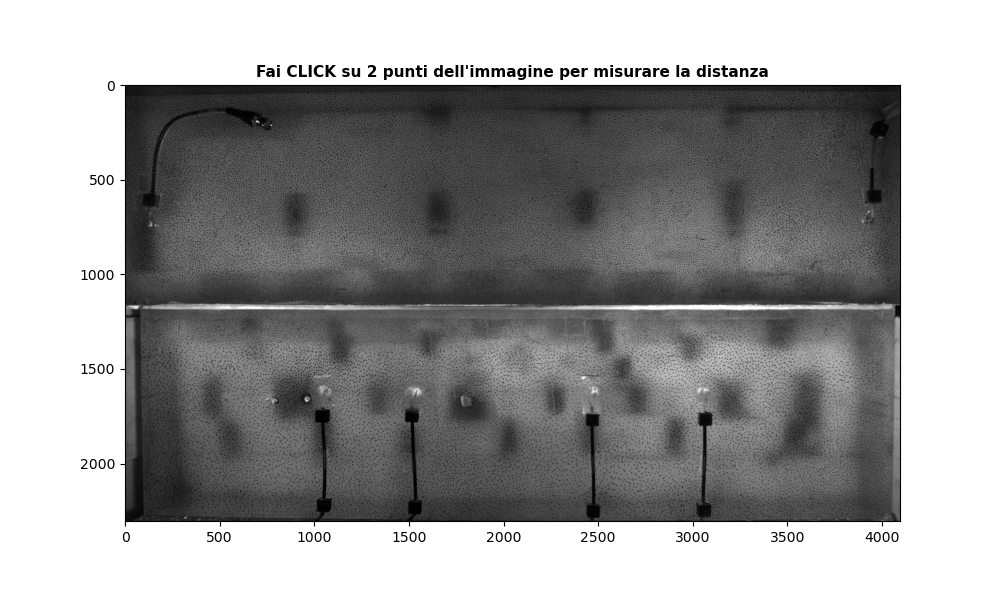

In [8]:
%matplotlib widget

# Variable globale per memorizzare l'ultima misurazione e le coordinate dei punti
last_measurement = {}

# --- (Setup cartelle e caricamento metadata) ---
folder_path = Path("/home/oreios/Experiments/R0032_P_P_6MPa")
shear_dir = folder_path / "photron" / "shear_loading"

if shear_dir.exists():
    folder_to_sel = shear_dir
else:
    folder_to_sel = folder_path / "photron" / "compaction"

subdirs = sorted([p for p in folder_to_sel.iterdir() if p.is_dir()])
if subdirs:
    folder_to_sel = subdirs[0]

cihx_files = sorted(folder_to_sel.glob("*.cihx"))
if cihx_files:
    metadata_path = cihx_files[0]
    metadata = parse_cihx(metadata_path)
    pixel_to_meter = float(metadata["sizeOfPixel"])

# --- (Caricamento e normalizzazione immagine) ---
tif_files = sorted(list(folder_to_sel.glob("*.tif")) + list(folder_to_sel.glob("*.tiff")))

if not tif_files:
    print(f"Nessun file .tif trovato in {folder_to_sel}")
else:
    first_tif = tif_files[0]
    print(f"Caricamento immagine: {first_tif.name}")

    img = tifffile.imread(first_tif)
    img = np.squeeze(img)
    if img.ndim == 3:
        img = img[:, :, 0]

    img_min, img_max = img.min(), img.max()
    if img_max > img_min:
        img_norm = ((img - img_min) / (img_max - img_min) * 255).astype(np.uint8)
    else:
        img_norm = img

    # --- (Interfaccia Interattiva) ---
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.imshow(img_norm, cmap='gray')
    ax.set_title("Fai CLICK su 2 punti dell'immagine per misurare la distanza", fontsize=11, fontweight='bold')

    coords = []
    line_plot, = ax.plot([], [], 'r-o', linewidth=2, markersize=6)

    fig.canvas.mpl_connect('button_press_event', onclick)
    plt.show()

In [9]:
# Esempio di utilizzo delle coordinate salvate
p1_x, p1_y = last_measurement["pt1_cm"]
p2_x, p2_y = last_measurement["pt2_cm"]
lunghezza_cm = last_measurement["dist_cm"]
p2_to_take=min([p2_x,p1_x])

#### Import sensor coordinates and block properties

In [19]:
vp = assembly["lower_block"]["Vp [m/s]"] * 100  # cm/s
vs = assembly["lower_block"]["Vs [m/s]"] * 100  # cm/s

v_u = vp
v_l = vp
v_g = 1500 * 100  # cm/s (1000 m/s) #Gouge Vp # Gioca su questo parametro [1500-2000 m/s]

# Conversioni corrette in cm
lx_u = assembly["upper_block"]["length [m]"] * 100
ly_u = assembly["upper_block"]["width [m]"] * 100
lz_u = assembly["upper_block"]["height [m]"] * 100

lx_l = assembly["lower_block"]["length [m]"] * 100
ly_l = assembly["lower_block"]["width [m]"] * 100
lz_l = assembly["lower_block"]["height [m]"] * 100

# Spessore Gouge in cm (default 0.5 cm se non specificato o se pari a 0)
lz_g = (
    Exp_info["gouge_thickness_mm"] / 10
    if "Exp_info" in locals() and Exp_info.get("gouge_thickness_mm", 0) > 0
    else 0.5
)
lz_g = 0.4

ds_dimensions = [
    (lx_u, ly_u, lz_u),  # Blocco Superiore
    (lx_l, ly_l, lz_g),  # Strato di Gouge
    (lx_l, ly_l, lz_l),  # Blocco Inferiore
]


AE_calib_folder = Path("/mnt/scratch/oreios/Calibrations/AE")
file_path = AE_calib_folder / f"AE_sensors_coordinates_{material}.csv"
sens_coord = pd.read_csv(file_path)

sensor_map_ds = {}
for _, row in sens_coord.iterrows():
    sensor_name = str(row["SENSOR"]).strip()
    if pd.notna(row["SENSOR"]):
        x, y, z_csv = row["X"], row["Y"], row["Z"]

        if sensor_name.startswith("PB"):
            z_ds = -z_csv
        elif sensor_name.startswith("PU"):
            z_ds = lz_g + z_csv
        else:
            z_ds = z_csv

        sensor_map_ds[sensor_name] = np.array([x, y, z_ds])


##### Modify coordinates taking into account DCT displacement
# 1. Trova il sensore 'PUB11' per calcolare il delta (diffR)
diffR = None
for name, coords in sensor_map_ds.items():
    if name == 'PUB11':  # Specificiamo esattamente PUB11 per evitare ambiguità
        diffR = coords[0] - p2_to_take
        break

# 2. Applica la trasformazione e stampa la tabella
if diffR is not None:
    print(f"--- Delta calcolato (diffR): {diffR:.3f} ---")
    print(f"{'Sensore':<10} | {'X assoluta':<15} | {'X esperimento':<15} | {'X After shear':<15}")
    print("-" * 62)

    for sensor_name, coords in sensor_map_ds.items():
        if sensor_name.startswith('PU'):
            # 1. Coordinata originale
            old_x = coords[0]          
            
            # 2. Traslazione rispetto al riferimento dell'esperimento
            coords[0] -= diffR
            old_x2 = coords[0]         
            
            # 3. Aggiunta dello spostamento dopo lo shear
            coords[0] += add_displ
            new_x = coords[0]          
            #coords[0]=81-coords[0]       
            print(f"{sensor_name:<10} | {old_x:<15.3f} | {old_x2:<15.3f} | {new_x:<15.3f}")
else:
    print("Nessun sensore 'PUB11' trovato nel dizionario.")

--- Delta calcolato (diffR): 3.636 ---
Sensore    | X assoluta      | X esperimento   | X After shear  
--------------------------------------------------------------
PUF11      | 64.950          | 61.314          | 64.440         
PUF12      | 48.850          | 45.214          | 48.340         
PUF13      | 32.350          | 28.714          | 31.840         
PUF14      | 17.250          | 13.614          | 16.740         
PUB11      | 5.150           | 1.514           | 4.640          
PUB12      | 76.300          | 72.664          | 75.790         


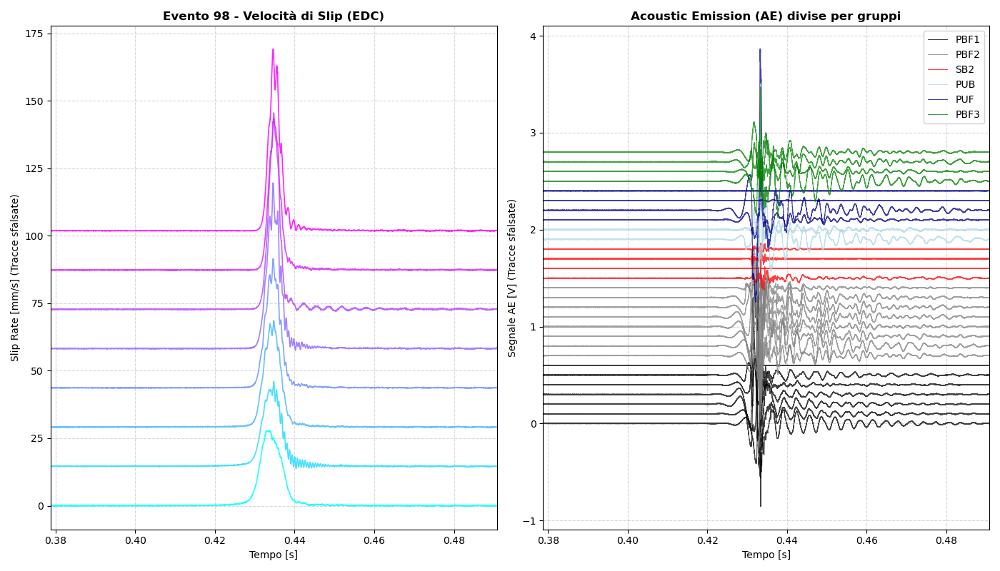

In [20]:
%matplotlib widget
# -----------------------------------------------------------------------------
# CONFIGURAZIONE FIGURA (2 Colonne)
# -----------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 8),sharex=True)

# Seleziona se mostrare lo SLIP (to_takeZ) o lo SLIP RATE (slip_ratesR)
use_slip_rate = True  # Imposta su False per visualizzare lo Slip (Dislocazione)

if use_slip_rate:
    edc_data = slip_ratesR
    edc_label = "Slip Rate [mm/s]"
    edc_title = f"Evento {target_event_num} - Velocità di Slip (EDC)"
else:
    edc_data = to_takeZ
    edc_label = "Slip [micron]"
    edc_title = f"Evento {target_event_num} - Dislocazione / Slip (EDC)"

# -----------------------------------------------------------------------------
# PANNELLO 1 (Colonna di sinistra): SLIP / SLIP RATE (EDC) - Colormap 'cool'
# -----------------------------------------------------------------------------
if edc_data is not None and timeS is not None:
    # Calcolo dell'offset verticale per non sovrapporre i canali EDC
    max_amplitude = np.nanmax(np.abs(edc_data)) if np.nanmax(np.abs(edc_data)) != 0 else 1.0
    edc_offset = max_amplitude * .2

    # Definizione della colormap 'cool' per i canali EDC
    cmap = plt.get_cmap('cool')
    n_channels = edc_data.shape[0]

    for i in range(n_channels):
        # Assegna un colore sfumato lungo la colormap 'cool' in base all'indice del canale
        color = cmap(i / max(1, n_channels - 1))
        ax1.plot(timeS, edc_data[i, :] + i * edc_offset, color=color, alpha=0.85, linewidth=1.2)

    ax1.set_ylabel(f"{edc_label} (Tracce sfalsate)")
    ax1.set_xlabel("Tempo [s]")
    ax1.set_title(edc_title, fontsize=12, fontweight='bold')
    ax1.grid(True, linestyle="--", alpha=0.5)

# -----------------------------------------------------------------------------
# PANNELLO 2 (Colonna di destra): ACOUSTIC EMISSIONS (AE)
# -----------------------------------------------------------------------------
if ae_groups is not None and len(ae_groups) > 0:
    # Se timeAE non fosse stato popolato, usiamo timeS come approssimazione
    time_ae_vector = timeAE if timeAE is not None else np.linspace(timeS[0], timeS[-1], ae_groups["PB1"]["traces"].shape[1])
    
    current_offset = 0
    ae_offset_step = .1  # Modifica questo valore per regolare lo spaziamento tra canali AE

    for group_name, group_data in ae_groups.items():
        traces = group_data.get("traces", [])
        color = group_data.get("color", "k")

        if len(traces) > 0:
            for j in range(traces.shape[0]):
                ax2.plot(
                    time_ae_vector, 
                    traces[j, :] + current_offset, 
                    color=color, 
                    alpha=0.75, 
                    linewidth=0.8,
                    label=group_name if j == 0 else ""  # Etichetta in legenda solo per la prima traccia del gruppo
                )
                current_offset += ae_offset_step

    ax2.set_ylabel("Segnale AE [V] (Tracce sfalsate)")
    ax2.set_xlabel("Tempo [s]")
    ax2.set_title("Acoustic Emission (AE) divise per gruppi", fontsize=12, fontweight='bold')
    ax2.grid(True, linestyle="--", alpha=0.5)
    ax2.legend(loc="upper right", framealpha=0.9)
    ax2.set_xlim(time_ae_vector[0], time_ae_vector[-1])
else:
    ax2.text(0.5, 0.5, "Dati AE non disponibili per questo evento", ha='center', va='center', transform=ax2.transAxes)
    ax2.set_xlabel("Tempo [s]")

ax2.set_xlim(time_ae_vector[0],time_ae_vector[-1])
plt.tight_layout()
plt.show()

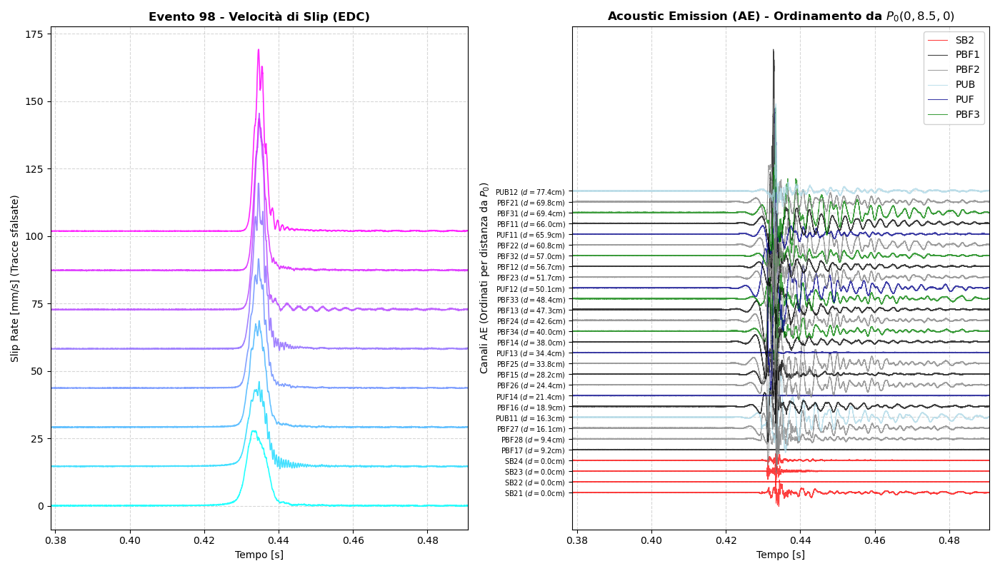

In [21]:
%matplotlib widget
# -----------------------------------------------------------------------------
# CONFIGURAZIONE FIGURA (2 Colonne)
# -----------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 8), sharex=True)

# Seleziona se mostrare lo SLIP (to_takeZ) o lo SLIP RATE (slip_ratesR)
use_slip_rate = True  # Imposta su False per visualizzare lo Slip (Dislocazione)

if use_slip_rate:
    edc_data = slip_ratesR
    edc_label = "Slip Rate [mm/s]"
    edc_title = f"Evento {target_event_num} - Velocità di Slip (EDC)"
else:
    edc_data = to_takeZ
    edc_label = "Slip [micron]"
    edc_title = f"Evento {target_event_num} - Dislocazione / Slip (EDC)"

# -----------------------------------------------------------------------------
# PANNELLO 1 (Colonna di sinistra): SLIP / SLIP RATE (EDC) - Colormap 'cool'
# -----------------------------------------------------------------------------
if edc_data is not None and timeS is not None:
    max_amplitude = np.nanmax(np.abs(edc_data)) if np.nanmax(np.abs(edc_data)) != 0 else 1.0
    edc_offset = max_amplitude * 0.2

    cmap = plt.get_cmap('cool')
    n_channels = edc_data.shape[0]

    for i in range(n_channels):
        color = cmap(i / max(1, n_channels - 1))
        ax1.plot(timeS, edc_data[i, :] + i * edc_offset, color=color, alpha=0.85, linewidth=1.2)

    ax1.set_ylabel(f"{edc_label} (Tracce sfalsate)")
    ax1.set_xlabel("Tempo [s]")
    ax1.set_title(edc_title, fontsize=12, fontweight='bold')
    ax1.grid(True, linestyle="--", alpha=0.5)

# -----------------------------------------------------------------------------
# PANNELLO 2 (Colonna di destra): ACOUSTIC EMISSIONS (AE) ORDINATI PER DISTANZA
# -----------------------------------------------------------------------------
ref_point = np.array([0.0, 8.5, 0.0])  # Punto di riferimento P0(x=0, y=8.5, z=0)

if ae_groups is not None and len(ae_groups) > 0:
    all_ae_channels = []

    for group_name, group_data in ae_groups.items():
        traces = group_data.get("traces", [])
        color = group_data.get("color", "k")
        names = group_data.get("names", [f"{group_name}_{j+1}" for j in range(len(traces))])

        for j in range(len(traces)):
            ch_name = str(names[j]).strip() if j < len(names) else f"{group_name}_CH{j+1}"
            
            # Cerca le coordinate nel tuo dizionario sensor_map_ds
            if ch_name in sensor_map_ds:
                ch_coord = sensor_map_ds[ch_name]
                dist = float(np.linalg.norm(ch_coord - ref_point))
            elif "coords" in group_data and j < len(group_data["coords"]):
                ch_coord = group_data["coords"][j]
                dist = float(np.linalg.norm(np.array(ch_coord) - ref_point))
            else:
                dist = 0.0

            all_ae_channels.append({
                "group": group_name,
                "name": ch_name,
                "trace": traces[j],
                "color": color,
                "dist": dist
            })

    # 1. Ordinamento dei canali per distanza crescente dal punto P0
    all_ae_channels.sort(key=lambda ch: ch["dist"])

    # Generazione o recupero del vettore temporale per le AE
    first_trace = all_ae_channels[0]["trace"] if len(all_ae_channels) > 0 else []
    time_ae_vector = timeAE if timeAE is not None else np.linspace(timeS[0], timeS[-1], len(first_trace))

    # 2. Plotting con offset e etichette TeX
    current_offset = 0.0
    ae_offset_step = 0.1  # Regola lo spaziamo verticale tra le tracce AE

    yticks_pos = []
    yticks_labels = []
    legend_added_groups = set()

    for ch in all_ae_channels:
        label_group = ch["group"] if ch["group"] not in legend_added_groups else ""
        legend_added_groups.add(ch["group"])

        ax2.plot(
            time_ae_vector,
            ch["trace"] + current_offset,
            color=ch["color"],
            alpha=0.75,
            linewidth=0.8,
            label=label_group
        )

        yticks_pos.append(current_offset)
        
        # Etichetta formattata in LaTeX con il nome canale e la distanza in cm
        clean_name = ch['name'].replace('_', r'\_')
        tex_label = r"$\mathrm{%s}\ (d = %.1f\mathrm{cm})$" % (clean_name, ch["dist"])
        yticks_labels.append(tex_label)

        current_offset += ae_offset_step

    # Impostazioni assi e legende
    ax2.set_yticks(yticks_pos)
    ax2.set_yticklabels(yticks_labels, fontsize=7)
    ax2.set_ylabel(r"Canali AE (Ordinati per distanza da $P_0$)")
    ax2.set_xlabel("Tempo [s]")
    ax2.set_title(r"Acoustic Emission (AE) - Ordinamento da $P_0(0, 8.5, 0)$", fontsize=12, fontweight='bold')
    ax2.grid(True, linestyle="--", alpha=0.5)
    ax2.legend(loc="upper right", framealpha=0.9)
    ax2.set_xlim(time_ae_vector[0], time_ae_vector[-1])
else:
    ax2.text(0.5, 0.5, "Dati AE non disponibili per questo evento", ha='center', va='center', transform=ax2.transAxes)
    ax2.set_xlabel("Tempo [s]")

plt.tight_layout()
plt.show()

### Picking

In [28]:
# Bandpass Filtering Parameters
lowpas_cut,highpass_cut=5e3, 1e6

PUB12
Forma di data_chunk: (29, 349976)
Canali selezionati (indici numerici): [21]


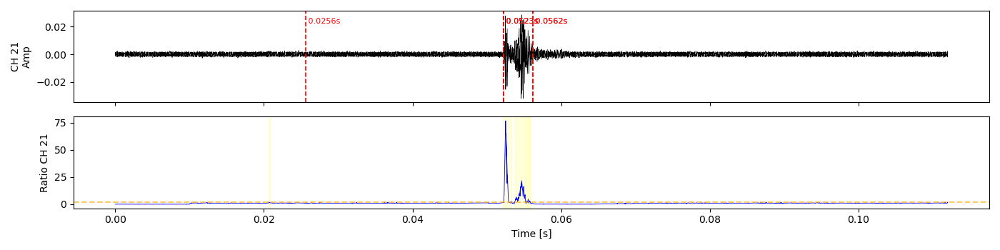

In [29]:
from obspy.signal.trigger import classic_sta_lta, trigger_onset

# 1. Unisci tutte le tracce AE in una matrice 2D [n_channels, n_samples]
all_traces_list = []
channels_names = []

if ae_groups is not None:
    for group in ae_groups.values():
        names = group.get("names", [])
        traces = group.get("traces", [])
        for name, trace in zip(names, traces):
            channels_names.append(name.strip())
            all_traces_list.append(trace)

# Converti in array NumPy: forma [n_channels, n_samples]
data_chunk = np.array(all_traces_list)

# 2. Definisci i canali desiderati tramite i loro indici numerici
my_channels = list(range(data_chunk.shape[0]))  # <--- Inserisci qui gli indici numerici dei canali (es. 0, 1, 2, 3, ...)
my_channels=[21]
print(channels_names[my_channels[0]-1])
# 3. Verifica le dimensioni prima di passare i dati alla funzione
print(f"Forma di data_chunk: {data_chunk.shape}")  # Deve essere [n_channels, dati_totali]
print(f"Canali selezionati (indici numerici): {my_channels}")


# 1. Selezione delle tracce desiderate
data_chunk_selected = data_chunk[my_channels, :].copy()

# 2. Filtraggio
for i in range(data_chunk_selected.shape[0]):
    #data_chunk_selected[i, :] = highpass_filter(data_chunk_selected[i, :], fsAE, 5e3, order=4)
    data_chunk_selected[i, :] = bandpass_filter(data_chunk_selected[i, :], fsAE, lowpas_cut,highpass_cut,order=4) 
# 3. Esegui la funzione passando la matrice filtrata
raw_picks = plot_full_resolution_picking(data_chunk_selected, fsAE, channel_ids=my_channels, sta_sec=0.0001, lta_sec=0.01, thr_on=2, thr_off=1.2,AIC_window=0.005) 

parameters for: lowpas_cut,highpass_cut=5e3, 1e6

In [30]:
# =============================================================================
# 1. ESTRAZIONE TRACCE AE E CREAZIONE MATRICE 2D
# =============================================================================
all_traces_list = []
channels_names = []

if ae_groups is not None:
    for group in ae_groups.values():
        names = group.get("names", [])
        traces = group.get("traces", [])
        for name, trace in zip(names, traces):
            channels_names.append(name.strip())
            all_traces_list.append(trace)

data_chunk = np.array(all_traces_list)
n_channels = data_chunk.shape[0]

print(f"Forma di data_chunk: {data_chunk.shape}")
print(f"Canali totali estratti: {n_channels}")

# =============================================================================
# 2. FILTRAGGIO E PICKING (Indici Canali 0-based)
# =============================================================================
data_chunkF = data_chunk.copy()

for i in range(n_channels):
    #data_chunkF[i, :] = highpass_filter(data_chunkF[i, :], fsAE, 1e3, order=4)
    data_chunkF[i, :] = bandpass_filter(data_chunkF[i, :], fsAE, lowpas_cut,highpass_cut,order=4) 


sta = {
    'PUB11': 0.0001,
    'PBF11': 0.0001,
    'PBF22': 0.0001,
    'PBF27': 0.0001,
    'PBF28': 0.0001,
    'PBF32': 0.0001,
    'PBF33': 0.0001,
    'DEFAULT': 0.001
}

lta = {
    'DEFAULT': 0.01
}

thron = {
    'PUB11': 2,
    'PUB12': 3,
    'PBF11': 2,
    'PBF22': 2,
    'PBF32': 2,
    'DEFAULT': 5
}

throff = {
    'PUB11': 1.2,
    'PBF16': 1.2,
    'PBF34': 1.2,
    'DEFAULT': 2
}

aicwin = {
    'PUB11': 0.001,
    'PUB12': 0.001,
    'PBF11': 0.0001,
    'PBF22': 0.0001,
    'PBF27': 0.0001,
    'PBF32': 0.0001,
    'DEFAULT': 0.0005
}

# Picking sui canali (indicizzati da 0 a n_channels - 1)
#raw_picks, cfts, onsets = get_picks_only(data_chunkF,fsAE,list(range(n_channels)),sta_sec=0.001,lta_sec=0.01,thr_on=5,thr_off=3,AIC_window=0.005)
#raw_picks,cfts, onsets = get_picks_only(data_chunkF, fsAE, list(range(n_channels)), sta_sec=0.001, lta_sec=0.01, thr_on=3, thr_off=3,AIC_window=0.004) 
raw_picks, cfts, onsets = get_picks_only(data_chunkF,fsAE,channels_names,sta_sec=sta,lta_sec=lta,thr_on=thron,thr_off=throff,AIC_window=aicwin)



# Associazione Pick
final_groupsN = associate_picks_unique(
    raw_picks, channel_ids=list(range(n_channels)), tolerance=0.0005
)

final_groups = []
print(f"\n{'EVENTO':<8} | {'TEMPO [s]':<12} | {'CANALI'}")
print("-" * 40)
for i, g in enumerate(final_groupsN):
    if len(g) >= 4:  # Almeno 4 sensori attivi per localizzazione 3D
        print(
            f"{i:03d}      | {min(p['time'] for p in g):.6f}     | {[p['ch'] for p in g]}"
        )
        final_groups.append(g)

# =============================================================================
# 3. REVISE COORDINATE SENSORI
# =============================================================================
# Mappatura canali-sensori con indicizzazione omogenea 0-based
AE_sensors_list = []
channel_to_sensor_idx = {}
sensor_idx = 0

for i, name in enumerate(channels_names):
    if name in sensor_map_ds and "S" not in name:
        coords = sensor_map_ds[name]
        AE_sensors_list.append(coords[:3])
        channel_to_sensor_idx[i] = (
            sensor_idx  # Mappa l'indice 0-based del canale
        )
        sensor_idx += 1

AE_sensors_list = np.array(AE_sensors_list)

print(f"\nSensori validi caricati per localizzazione: {len(AE_sensors_list)}")
print("-" * 80)


Forma di data_chunk: (29, 349976)
Canali totali estratti: 29

EVENTO   | TEMPO [s]    | CANALI
----------------------------------------
000      | 0.052195     | [17, 3, 4, 11, 12, 21, 10, 27, 5, 2, 9, 22, 13, 7, 28, 26, 8, 0, 1, 14, 15, 19, 25, 18, 20]
002      | 0.053319     | [0, 13, 8, 14]
004      | 0.053717     | [8, 14, 13, 11, 21, 15, 17, 3, 27, 19]

Sensori validi caricati per localizzazione: 25
--------------------------------------------------------------------------------


paramters for: lowpas_cut,highpass_cut=7e3, 0.8e6

In [25]:
# =============================================================================
# 1. ESTRAZIONE TRACCE AE E CREAZIONE MATRICE 2D
# =============================================================================
all_traces_list = []
channels_names = []

if ae_groups is not None:
    for group in ae_groups.values():
        names = group.get("names", [])
        traces = group.get("traces", [])
        for name, trace in zip(names, traces):
            channels_names.append(name.strip())
            all_traces_list.append(trace)

data_chunk = np.array(all_traces_list)
n_channels = data_chunk.shape[0]

print(f"Forma di data_chunk: {data_chunk.shape}")
print(f"Canali totali estratti: {n_channels}")

# =============================================================================
# 2. FILTRAGGIO E PICKING (Indici Canali 0-based)
# =============================================================================
data_chunkF = data_chunk.copy()

for i in range(n_channels):
    #data_chunkF[i, :] = highpass_filter(data_chunkF[i, :], fsAE, 1e3, order=4)
    data_chunkF[i, :] = bandpass_filter(data_chunkF[i, :], fsAE, lowpas_cut,highpass_cut,order=4) 


sta = {
    'PUB11': 0.0001,
    'PUB12': 0.00001,
    'PBF11': 0.0001,
    'PBF22': 0.0001,
    'PBF27': 0.0001,
    'PBF28': 0.0001,
    'PBF32': 0.0001,
    'PBF33': 0.0001,
    'DEFAULT': 0.001
}

lta = {
    'DEFAULT': 0.01
}

thron = {
    'PUB11': 2,
    'PUB12': 4,
    'PBF11': 2,
    'PBF22': 2,
    'PBF28': 2,
    'PBF32': 2,
    'DEFAULT': 5
}

throff = {
    'PUB11': 1.2,
    'PUB12': 1.2,
    'PBF16': 1.2,
    'PBF34': 1.2,
    'DEFAULT': 2
}

aicwin = {
    'PUB11': 0.001,
    'PUB12': 0.0001,
    'PBF11': 0.0001,
    'PBF22': 0.0001,
    'PBF27': 0.0001,
    'PBF28': 0.00005,
    'PBF32': 0.0001,
    'DEFAULT': 0.0005
}

# Picking sui canali (indicizzati da 0 a n_channels - 1)
#raw_picks, cfts, onsets = get_picks_only(data_chunkF,fsAE,list(range(n_channels)),sta_sec=0.001,lta_sec=0.01,thr_on=5,thr_off=3,AIC_window=0.005)
#raw_picks,cfts, onsets = get_picks_only(data_chunkF, fsAE, list(range(n_channels)), sta_sec=0.001, lta_sec=0.01, thr_on=3, thr_off=3,AIC_window=0.004) 
raw_picks, cfts, onsets = get_picks_only(data_chunkF,fsAE,channels_names,sta_sec=sta,lta_sec=lta,thr_on=thron,thr_off=throff,AIC_window=aicwin)



# Associazione Pick
final_groupsN = associate_picks_unique(
    raw_picks, channel_ids=list(range(n_channels)), tolerance=0.0005
)

final_groups = []
print(f"\n{'EVENTO':<8} | {'TEMPO [s]':<12} | {'CANALI'}")
print("-" * 40)
for i, g in enumerate(final_groupsN):
    if len(g) >= 4:  # Almeno 4 sensori attivi per localizzazione 3D
        print(
            f"{i:03d}      | {min(p['time'] for p in g):.6f}     | {[p['ch'] for p in g]}"
        )
        final_groups.append(g)

# =============================================================================
# 3. REVISE COORDINATE SENSORI
# =============================================================================
# Mappatura canali-sensori con indicizzazione omogenea 0-based
AE_sensors_list = []
channel_to_sensor_idx = {}
sensor_idx = 0

for i, name in enumerate(channels_names):
    if name in sensor_map_ds and "S" not in name:
        coords = sensor_map_ds[name]
        AE_sensors_list.append(coords[:3])
        channel_to_sensor_idx[i] = (
            sensor_idx  # Mappa l'indice 0-based del canale
        )
        sensor_idx += 1

AE_sensors_list = np.array(AE_sensors_list)

print(f"\nSensori validi caricati per localizzazione: {len(AE_sensors_list)}")
print("-" * 80)
for name, picks in zip(channels_names, raw_picks):
    if name == 'PBF28':
        print(f"PBF28 raw picks: {picks}")

Forma di data_chunk: (29, 349976)
Canali totali estratti: 29

EVENTO   | TEMPO [s]    | CANALI
----------------------------------------
002      | 0.052191     | [4, 17, 11, 3, 12, 21, 10, 27, 22, 5, 9, 2, 8, 14, 28, 13, 7, 1, 26, 19, 18, 0, 25, 20, 15]
012      | 0.053444     | [20, 8, 0, 14]
019      | 0.054285     | [14, 19, 11, 21, 20]
024      | 0.054891     | [20, 3, 19, 26]

Sensori validi caricati per localizzazione: 25
--------------------------------------------------------------------------------
PBF28 raw picks: [0.02530432, 0.05237056, 0.05363488, 0.05385408, 0.05425888, 0.05428512, 0.05527776, 0.05527264, 0.05550816, 0.05549952, 0.05558688, 0.05564128, 0.05572032, 0.05588864]


In [34]:
# =============================================================================
# 4. ANALISI ED ESECUZIONE LOCALIZZAZIONE
# =============================================================================
EVENT_TO_ANALYZE = 0

In [47]:
evento_picks = evento_dict

In [27]:
evento7 = final_groups[0]

In [31]:
evento5 = final_groups[0]


=== RISULTATI LOCALIZZAZIONE (EVENTO 0) ===
Grid Search (nodo discreto) : X=33.23 cm, Y=8.50 cm, Z=0.00 cm | Misfit=9.112e-05 s
Inversione (spazio continuo): X=32.90 cm, Y=8.50 cm, Z=0.00 cm


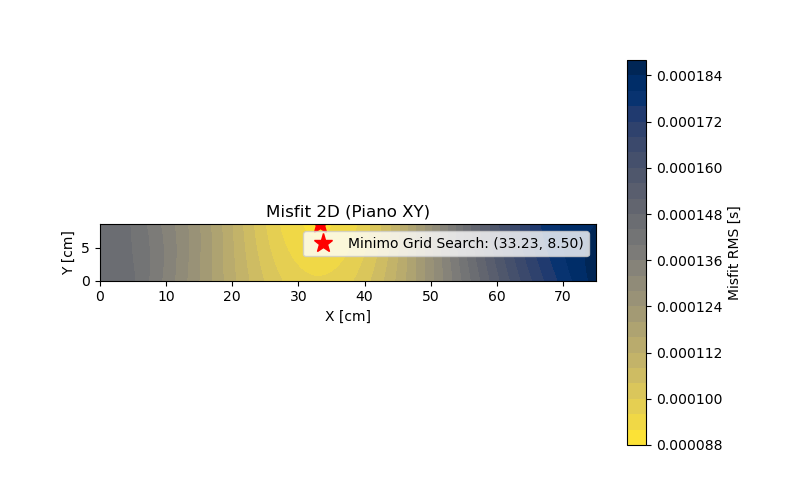

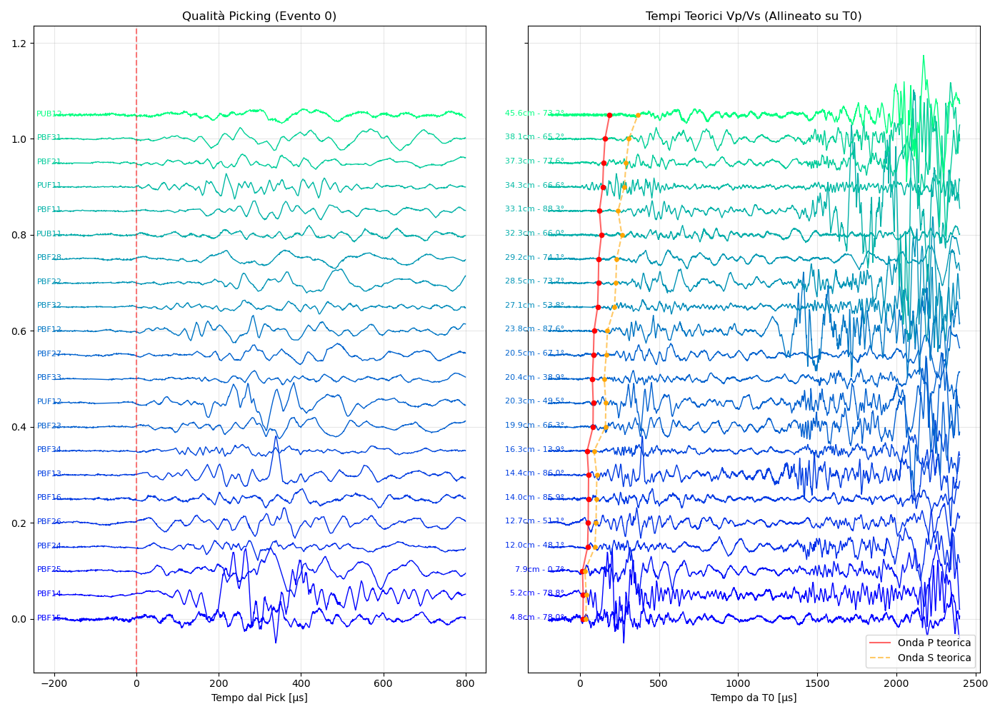


          CONFRONTO DIAGNOSI ED ERRORE TRA I METODI

--- RESIDUI TEMPORALI PER SINGOLO CANALE [µs] ---
Canale       | Grid Search [µs]     | Inversione [µs]     
----------------------------------------------------------
Ch 4  (PBF15) |             -61.44 |             -60.95
Ch 3  (PBF14) |             -80.80 |             -82.72
Ch 11 (PBF25) |             -26.55 |             -26.38
Ch 10 (PBF24) |             -21.67 |             -23.60
Ch 12 (PBF26) |             -54.30 |             -53.81
Ch 5  (PBF16) |              +0.20 |              +0.69
Ch 2  (PBF13) |              +1.64 |              -0.29
Ch 28 (PBF34) |             +71.46 |             +69.54
Ch 9  (PBF23) |             -12.20 |             -14.12
Ch 22 (PUF12) |             -12.27 |             -14.19
Ch 27 (PBF33) |             -26.46 |             -28.38
Ch 13 (PBF27) |              -0.20 |              +0.29
Ch 1  (PBF12) |             +92.03 |             +90.10
Ch 26 (PBF32) |             +23.28 |             +

In [16]:
# =============================================================================
# ESECUZIONE ANALISI LOCALIZZAZIONE
# =============================================================================
if len(final_groups) > EVENT_TO_ANALYZE:
    evento_picks = final_groups[EVENT_TO_ANALYZE]

    # 1. Preparazione DTOA
    dtoa_res, coords_res, pairs_res, active_times_res = prepare_event_data(
        evento_picks, AE_sensors_list, channel_to_sensor_idx
    )

    if dtoa_res is None:
        print(
            f"[X] Evento {EVENT_TO_ANALYZE} con sensori attivi insufficienti per la localizzazione."
        )
    else:
        # 2. Inizializzazione modello DS
        event_sim_res = DS(
            dimensions=ds_dimensions,
            grid_res=(80, 20, 5),  # 8000 punti sulla griglia globale
            AE_sensors=AE_sensors_list,
            v_upper=v_u,
            v_lower=v_l,
            v_gouge=v_g,
            x_shift=0.0,
            use_snell=True,
        )

        # 3. PASSO 1: GRID SEARCH PURA (Trova il nodo discreto globale)
        grid_pts, misfit = event_sim_res.compute_misfit_event(
            dtoa_res, coords_res, pairs_res
        )
        best_idx = np.argmin(misfit)
        hypocenter_grid = grid_pts[best_idx]

        # 4. PASSO 2: RAFFINAMENTO CONTINUO (Partendo dal risultato della Grid Search)
        hypocenter_inv = event_sim_res.invert_location_event(
            dtoa_res, coords_res, pairs_res, initial_guess=hypocenter_grid
        )

        print(f"\n=== RISULTATI LOCALIZZAZIONE (EVENTO {EVENT_TO_ANALYZE}) ===")
        print(
            f"Grid Search (nodo discreto) : X={hypocenter_grid[0]:.2f} cm, Y={hypocenter_grid[1]:.2f} cm, Z={hypocenter_grid[2]:.2f} cm | Misfit={misfit[best_idx]:.3e} s"
        )
        print(
            f"Inversione (spazio continuo): X={hypocenter_inv[0]:.2f} cm, Y={hypocenter_inv[1]:.2f} cm, Z={hypocenter_inv[2]:.2f} cm"
        )

        # Mappa 2D del Misfit
        event_sim_res.plot_misfit(dtoa_res, coords_res, pairs_res)

        # =============================================================================
        # 5. TRACCIAMENTO WAVEFORMS E CONFRONTO DIAGNOSI
        # =============================================================================
        hypocenter = hypocenter_inv

        recorded_data = []
        recorded_names = []
        used_channels = set()

        for p in evento_picks:
            ch = p["ch"]
            if ch in used_channels or ch not in channel_to_sensor_idx:
                continue
            used_channels.add(ch)

            ch_name = channels_names[ch]
            sensor_coord = AE_sensors_list[channel_to_sensor_idx[ch]]

            vec = sensor_coord - hypocenter
            dist = np.linalg.norm(vec)
            vec_norm = vec / dist if dist > 0 else vec

            normal = np.array([0, 0, 1])
            angle_inc = np.degrees(
                np.arccos(np.clip(np.abs(np.dot(vec_norm, normal)), -1.0, 1.0))
            )

            recorded_data.append(
                {
                    "pick": p,
                    "dist": dist,
                    "name": ch_name,
                    "angle_inc": angle_inc,
                }
            )
            recorded_names.append(ch_name)

        recorded_data = sorted(recorded_data, key=lambda x: x["dist"])

        picks_ordered = [x["pick"] for x in recorded_data]
        dist_ordered = [x["dist"] for x in recorded_data]
        names_ordered = [x["name"] for x in recorded_data]
        angle_inc_ordered = [x["angle_inc"] for x in recorded_data]

        def calc_location_errors(hypo_pt):
            tt_p_vec = [
                event_sim_res._get_single_tt(
                    hypo_pt, AE_sensors_list[channel_to_sensor_idx[p["ch"]]]
                )
                for p in picks_ordered
            ]

            t0 = np.median([p["time"] - tt for p, tt in zip(picks_ordered, tt_p_vec)])
            res_us = np.array([(p["time"] - (t0 + tt)) * 1e6 for p, tt in zip(picks_ordered, tt_p_vec)])
            res_mean_abs = np.mean(np.abs(res_us))
            err_scalare = (vp * res_mean_abs) / 1e6

            res_s = res_us / 1e6
            var_t = np.var(res_s) if len(res_s) > 1 else 1e-12

            J = np.zeros((len(pairs_res), 3))
            eps = 1e-2

            T_base = np.array([event_sim_res._get_single_tt(hypo_pt, s) for s in coords_res])
            dtoa_base = np.array([T_base[j] - T_base[i] for i, j in pairs_res])

            for d in range(3):
                m_p = hypo_pt.copy()
                m_p[d] += eps
                T_p = np.array([event_sim_res._get_single_tt(m_p, s) for s in coords_res])
                dtoa_p = np.array([T_p[j] - T_p[i] for i, j in pairs_res])
                J[:, d] = (dtoa_p - dtoa_base) / eps

            try:
                cov_m = var_t * np.linalg.inv(J.T @ J + 1e-8 * np.eye(3))
                err_x, err_y, err_z = np.sqrt(np.maximum(0, np.diag(cov_m)))
                err_3d = np.sqrt(err_x**2 + err_y**2 + err_z**2)
            except np.linalg.LinAlgError:
                err_x = err_y = err_z = err_3d = np.nan

            return {
                "t0": t0,
                "tt_p": tt_p_vec,
                "res_us": res_us,
                "res_mean_abs": res_mean_abs,
                "err_scalare": err_scalare,
                "err_x": err_x,
                "err_y": err_y,
                "err_z": err_z,
                "err_3d": err_3d,
            }

        diag_grid = calc_location_errors(hypocenter_grid)
        diag_inv = calc_location_errors(hypocenter_inv)

        # Plot Waveforms
        time_window_us = 800
        samples_window = int((time_window_us / 1e6) * fsAE)
        v_offset_step = 0.05

        norm = plt.Normalize(
            vmin=min(dist_ordered) if dist_ordered else 0,
            vmax=max(dist_ordered) if dist_ordered else 1,
        )
        cmap = cm.winter

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 10), sharey=True)

        for i, (pick, d, name, tt_p_val) in enumerate(
            zip(picks_ordered, dist_ordered, names_ordered, diag_inv["tt_p"])
        ):
            data_idx = pick["ch"]
            if data_idx < 0 or data_idx >= len(data_chunkF):
                continue

            trace = data_chunkF[data_idx]
            v_offset = i * v_offset_step
            color = cmap(norm(d))

            cp = int(pick["time"] * fsAE)
            s1, e1 = cp - samples_window // 4, cp + samples_window
            seg1 = trace[max(0, s1) : min(len(trace), e1)]
            t_ax1 = (np.arange(len(seg1)) / fsAE) - ((cp - max(0, s1)) / fsAE)

            ax1.plot(t_ax1 * 1e6, seg1 + v_offset, color=color, lw=1)
            ax1.text(
                t_ax1[0] * 1e6 + 20,
                v_offset + 0.002,
                name,
                fontsize=8,
                ha="right",
                va="center",
                color=color,
            )

            co = int(diag_inv["t0"] * fsAE)
            s2, e2 = co - samples_window // 4, co + int(samples_window * 3)
            seg2 = trace[max(0, s2) : min(len(trace), e2)]
            t_ax2 = (np.arange(len(seg2)) / fsAE) - ((co - max(0, s2)) / fsAE)

            ax2.plot(t_ax2 * 1e6, seg2 + v_offset, color=color, lw=1)
            ax2.text(
                t_ax2[0] * 1e6 + 100,
                v_offset + 0.003,
                f"{d:.1f}cm - {angle_inc_ordered[i]:.1f}°",
                fontsize=8,
                ha="right",
                va="center",
                color=color,
            )

            tt_s_val = tt_p_val * (vp / vs) if vs > 0 else tt_p_val * 1.73
            ax2.scatter(tt_p_val * 1e6, v_offset, color="red", s=20, zorder=5)
            ax2.scatter(
                tt_s_val * 1e6, v_offset, color="orange", s=15, zorder=5
            )

        ax2.plot(
            [tt * 1e6 for tt in diag_inv["tt_p"]],
            [i * v_offset_step for i in range(len(dist_ordered))],
            color="red",
            alpha=0.6,
            label="Onda P teorica",
        )
        ax2.plot(
            [tt * (vp / vs) * 1e6 for tt in diag_inv["tt_p"]],
            [i * v_offset_step for i in range(len(dist_ordered))],
            color="orange",
            alpha=0.6,
            ls="--",
            label="Onda S teorica",
        )

        ax1.set_title(
            f"Qualità Picking (Evento {EVENT_TO_ANALYZE})", fontsize=12
        )
        ax2.set_title("Tempi Teorici Vp/Vs (Allineato su T0)", fontsize=12)
        ax1.set_xlabel("Tempo dal Pick [µs]")
        ax2.set_xlabel("Tempo da T0 [µs]")

        ax1.axvline(0, color="red", ls="--", alpha=0.5)
        ax1.grid(True, alpha=0.3)
        ax2.grid(True, alpha=0.3)
        ax2.legend(loc="lower right")

        plt.tight_layout()
        plt.show()

        # =============================================================================
        # 6. REPORT CONFRONTO
        # =============================================================================
        print("\n" + "=" * 70)
        print("          CONFRONTO DIAGNOSI ED ERRORE TRA I METODI")
        print("=" * 70)

        print("\n--- RESIDUI TEMPORALI PER SINGOLO CANALE [µs] ---")
        print(f"{'Canale':<12} | {'Grid Search [µs]':<20} | {'Inversione [µs]':<20}")
        print("-" * 58)
        for p, r_grid, r_inv in zip(picks_ordered, diag_grid["res_us"], diag_inv["res_us"]):
            ch_name = channels_names[p["ch"]]
            print(f"Ch {p['ch']:<2d} ({ch_name:<4s}) | {r_grid:+18.2f} | {r_inv:+18.2f}")

        print("-" * 70)
        print("\n--- ERRORE SPAZIALE MEDIO SCALARE ---")
        print(f"Grid Search : Residuo Medio = {diag_grid['res_mean_abs']:.2f} µs | Errore Spaziale = {diag_grid['err_scalare']:.2f} cm")
        print(f"Inversione  : Residuo Medio = {diag_inv['res_mean_abs']:.2f} µs | Errore Spaziale = {diag_inv['err_scalare']:.2f} cm")

        print("\n--- INCERTEZZA SPAZIALE FORMALIZZATA (MATRICE DI COVARIANZA 3D) ---")
        if not np.isnan(diag_grid["err_3d"]):
            print(f"Grid Search : ±{diag_grid['err_3d']:.2f} cm  (σx: {diag_grid['err_x']:.2f}, σy: {diag_grid['err_y']:.2f}, σz: {diag_grid['err_z']:.2f})")
        else:
            print("Grid Search : Matrice Singolare")

        if not np.isnan(diag_inv["err_3d"]):
            print(f"Inversione  : ±{diag_inv['err_3d']:.2f} cm  (σx: {diag_inv['err_x']:.2f}, σy: {diag_inv['err_y']:.2f}, σz: {diag_inv['err_z']:.2f})")
        else:
            print("Inversione  : Matrice Singolare")
        print("=" * 70)

else:
    print(f"Nessun evento disponibile con indice {EVENT_TO_ANALYZE}.")

# Localization for multiple gouge velocities


######################################################################
   ANALISI CON VELOCITÀ GOUGE v_g = 1500000
######################################################################

=== RISULTATI LOCALIZZAZIONE (EVENTO 0 | v_g = 1500000) ===
Grid Search (nodo discreto) : X=32.28 cm, Y=8.50 cm, Z=0.00 cm | Misfit=8.309e-05 s
Inversione (spazio continuo): X=31.99 cm, Y=8.50 cm, Z=0.00 cm


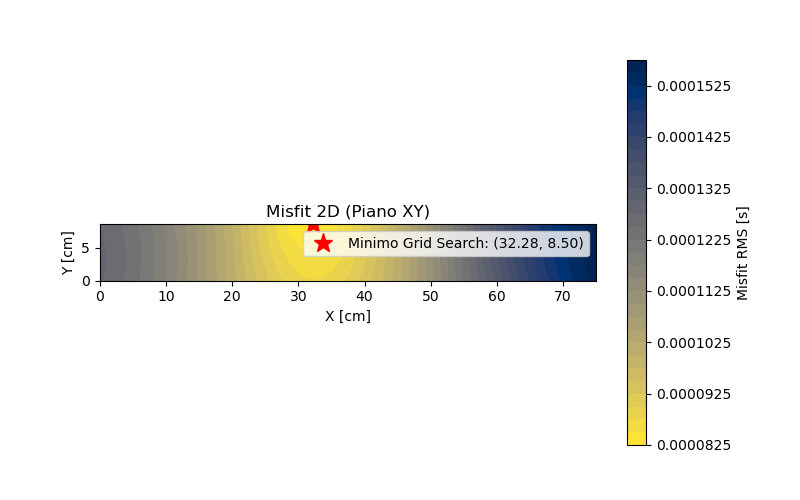

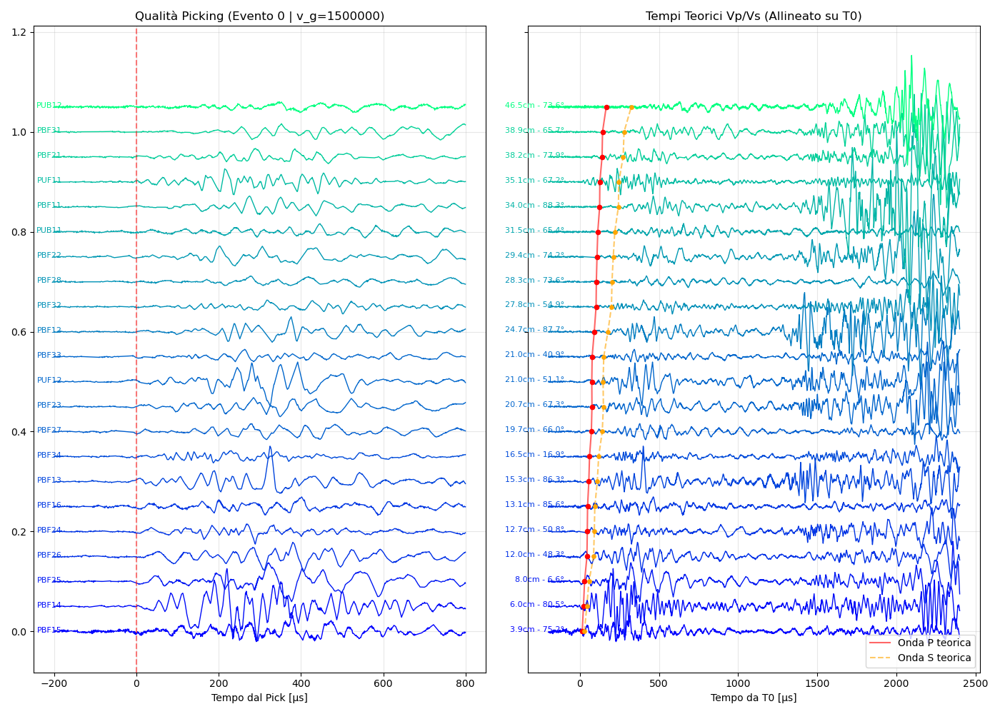


          CONFRONTO DIAGNOSI ED ERRORE TRA I METODI (v_g = 1500000)

--- RESIDUI TEMPORALI PER SINGOLO CANALE [µs] ---
Canale       | Grid Search [µs]     | Inversione [µs]     
----------------------------------------------------------
Ch 4  (PBF15) |             -80.47 |             -78.60
Ch 3  (PBF14) |             -32.16 |             -32.37
Ch 11 (PBF25) |             -28.83 |             -28.10
Ch 12 (PBF26) |             -62.68 |             -61.04
Ch 10 (PBF24) |              -9.34 |              -9.32
Ch 5  (PBF16) |             +11.84 |             +13.73
Ch 2  (PBF13) |             +19.07 |             +18.85
Ch 28 (PBF34) |             +88.56 |             +89.10
Ch 13 (PBF27) |             +23.92 |             +25.73
Ch 9  (PBF23) |              -2.66 |              -2.81
Ch 22 (PUF12) |              -8.54 |              -8.51
Ch 27 (PBF33) |              +2.66 |              +2.81
Ch 1  (PBF12) |              +3.17 |              +2.94
Ch 26 (PBF32) |             -19.78

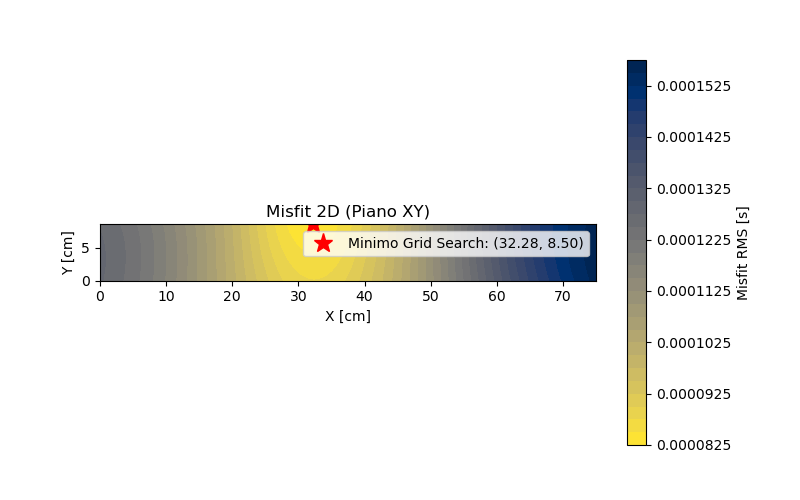

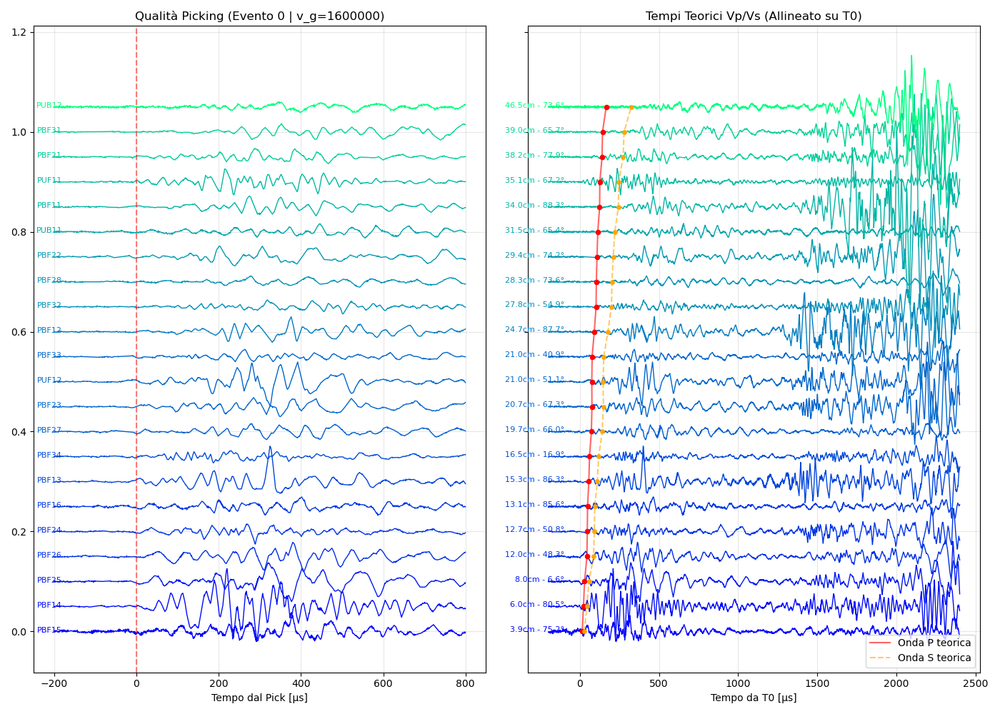


          CONFRONTO DIAGNOSI ED ERRORE TRA I METODI (v_g = 1600000)

--- RESIDUI TEMPORALI PER SINGOLO CANALE [µs] ---
Canale       | Grid Search [µs]     | Inversione [µs]     
----------------------------------------------------------
Ch 4  (PBF15) |             -80.47 |             -78.60
Ch 3  (PBF14) |             -32.16 |             -32.37
Ch 11 (PBF25) |             -28.83 |             -28.10
Ch 12 (PBF26) |             -62.68 |             -61.04
Ch 10 (PBF24) |              -9.34 |              -9.32
Ch 5  (PBF16) |             +11.84 |             +13.74
Ch 2  (PBF13) |             +19.07 |             +18.85
Ch 28 (PBF34) |             +88.56 |             +89.10
Ch 13 (PBF27) |             +23.92 |             +25.73
Ch 9  (PBF23) |              -2.66 |              -2.81
Ch 22 (PUF12) |              -8.51 |              -8.48
Ch 27 (PBF33) |              +2.66 |              +2.81
Ch 1  (PBF12) |              +3.17 |              +2.94
Ch 26 (PBF32) |             -19.78

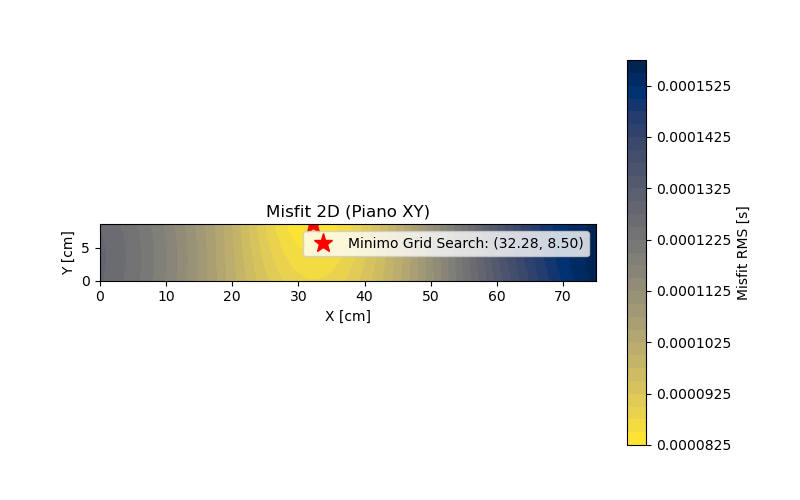

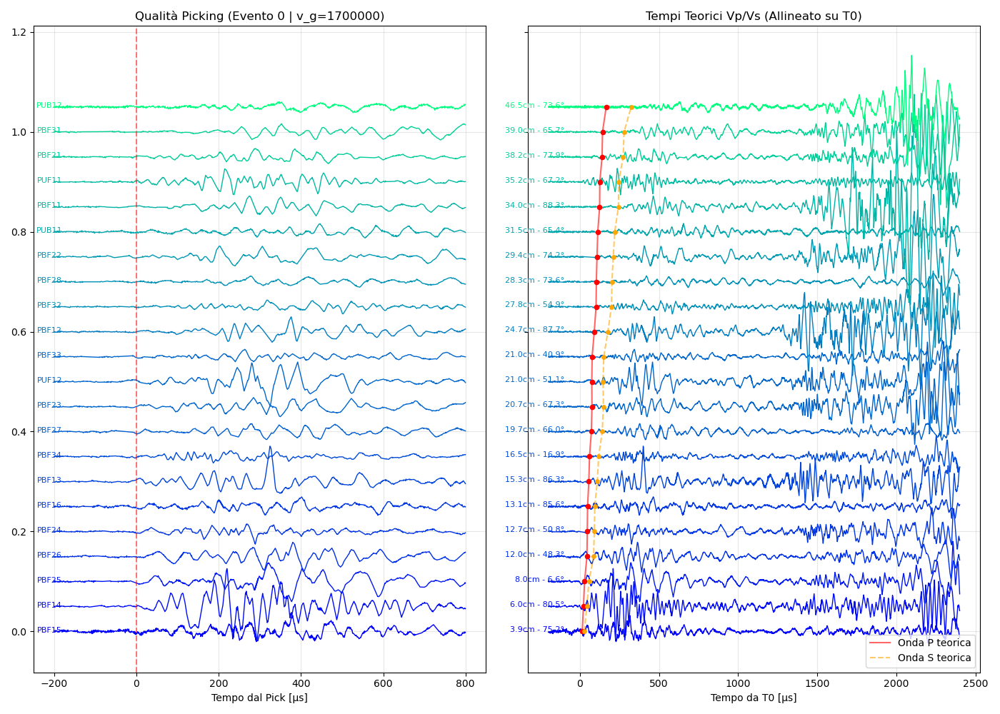


          CONFRONTO DIAGNOSI ED ERRORE TRA I METODI (v_g = 1700000)

--- RESIDUI TEMPORALI PER SINGOLO CANALE [µs] ---
Canale       | Grid Search [µs]     | Inversione [µs]     
----------------------------------------------------------
Ch 4  (PBF15) |             -80.47 |             -78.59
Ch 3  (PBF14) |             -32.16 |             -32.37
Ch 11 (PBF25) |             -28.83 |             -28.10
Ch 12 (PBF26) |             -62.68 |             -61.03
Ch 10 (PBF24) |              -9.34 |              -9.32
Ch 5  (PBF16) |             +11.84 |             +13.74
Ch 2  (PBF13) |             +19.07 |             +18.85
Ch 28 (PBF34) |             +88.56 |             +89.10
Ch 13 (PBF27) |             +23.92 |             +25.74
Ch 9  (PBF23) |              -2.66 |              -2.81
Ch 22 (PUF12) |              -8.49 |              -8.46
Ch 27 (PBF33) |              +2.66 |              +2.81
Ch 1  (PBF12) |              +3.17 |              +2.94
Ch 26 (PBF32) |             -19.78

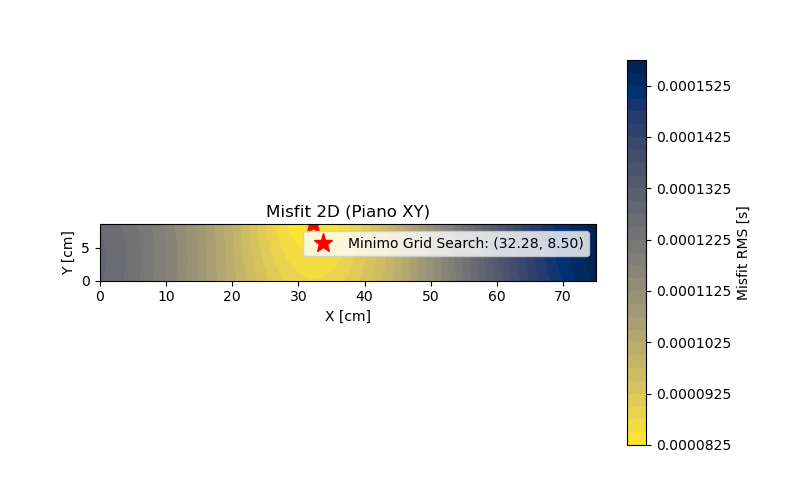

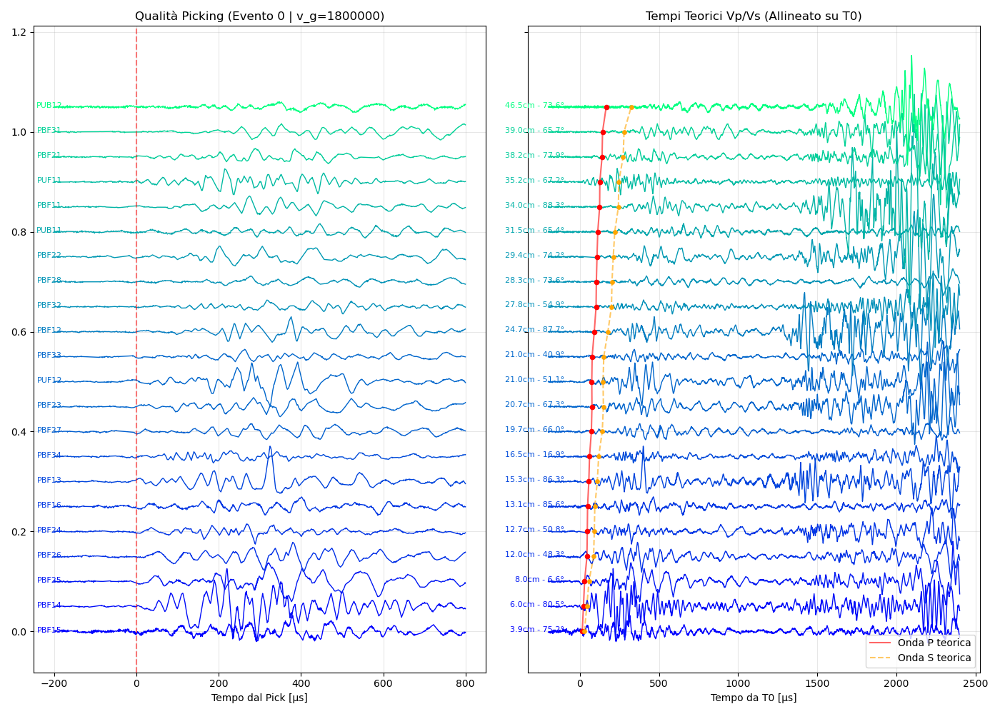


          CONFRONTO DIAGNOSI ED ERRORE TRA I METODI (v_g = 1800000)

--- RESIDUI TEMPORALI PER SINGOLO CANALE [µs] ---
Canale       | Grid Search [µs]     | Inversione [µs]     
----------------------------------------------------------
Ch 4  (PBF15) |             -80.47 |             -78.59
Ch 3  (PBF14) |             -32.16 |             -32.37
Ch 11 (PBF25) |             -28.83 |             -28.09
Ch 12 (PBF26) |             -62.68 |             -61.03
Ch 10 (PBF24) |              -9.34 |              -9.32
Ch 5  (PBF16) |             +11.84 |             +13.75
Ch 2  (PBF13) |             +19.07 |             +18.85
Ch 28 (PBF34) |             +88.56 |             +89.10
Ch 13 (PBF27) |             +23.92 |             +25.74
Ch 9  (PBF23) |              -2.66 |              -2.81
Ch 22 (PUF12) |              -8.47 |              -8.44
Ch 27 (PBF33) |              +2.66 |              +2.81
Ch 1  (PBF12) |              +3.17 |              +2.94
Ch 26 (PBF32) |             -19.78

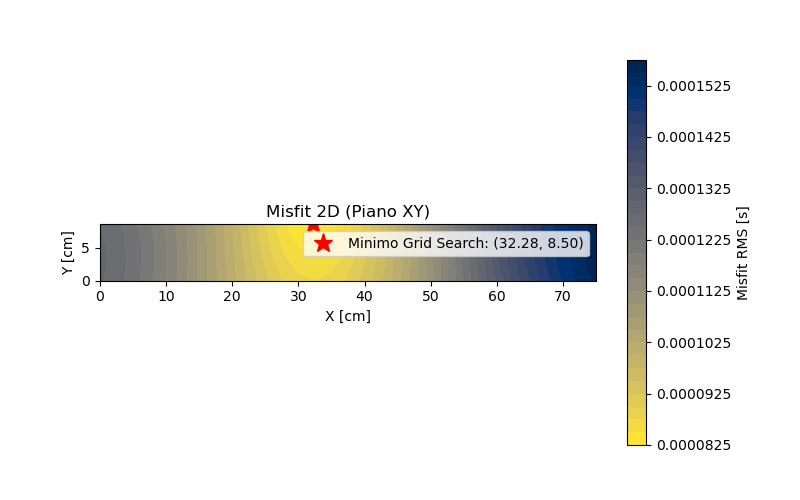

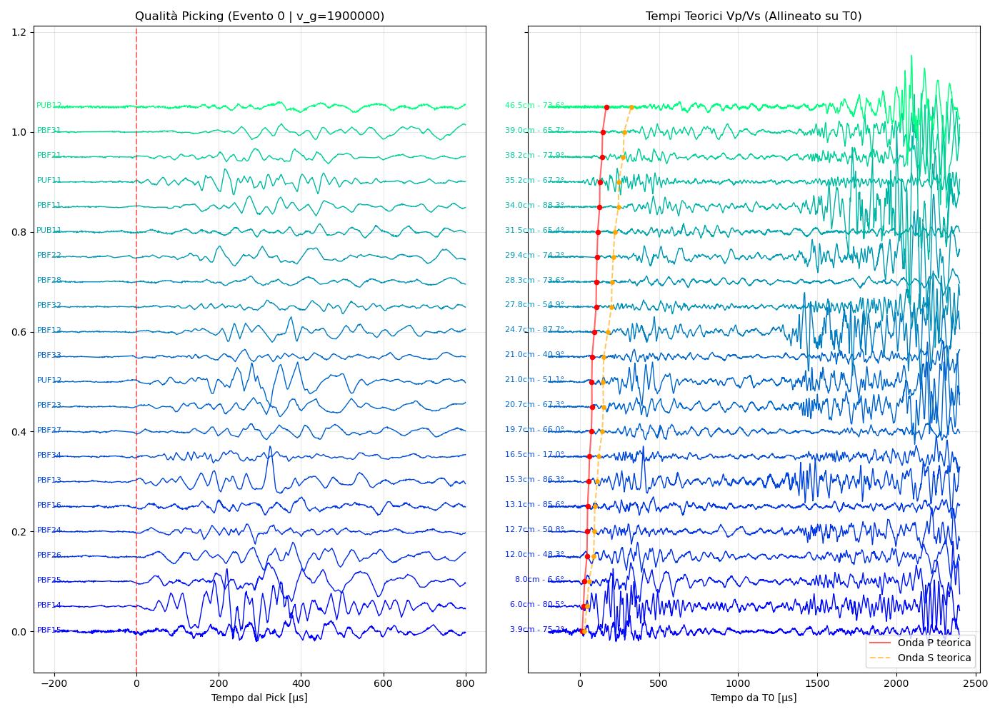


          CONFRONTO DIAGNOSI ED ERRORE TRA I METODI (v_g = 1900000)

--- RESIDUI TEMPORALI PER SINGOLO CANALE [µs] ---
Canale       | Grid Search [µs]     | Inversione [µs]     
----------------------------------------------------------
Ch 4  (PBF15) |             -80.47 |             -78.58
Ch 3  (PBF14) |             -32.16 |             -32.37
Ch 11 (PBF25) |             -28.83 |             -28.09
Ch 12 (PBF26) |             -62.68 |             -61.03
Ch 10 (PBF24) |              -9.34 |              -9.32
Ch 5  (PBF16) |             +11.84 |             +13.75
Ch 2  (PBF13) |             +19.07 |             +18.85
Ch 28 (PBF34) |             +88.56 |             +89.10
Ch 13 (PBF27) |             +23.92 |             +25.74
Ch 9  (PBF23) |              -2.66 |              -2.81
Ch 22 (PUF12) |              -8.45 |              -8.42
Ch 27 (PBF33) |              +2.66 |              +2.81
Ch 1  (PBF12) |              +3.17 |              +2.94
Ch 26 (PBF32) |             -19.78

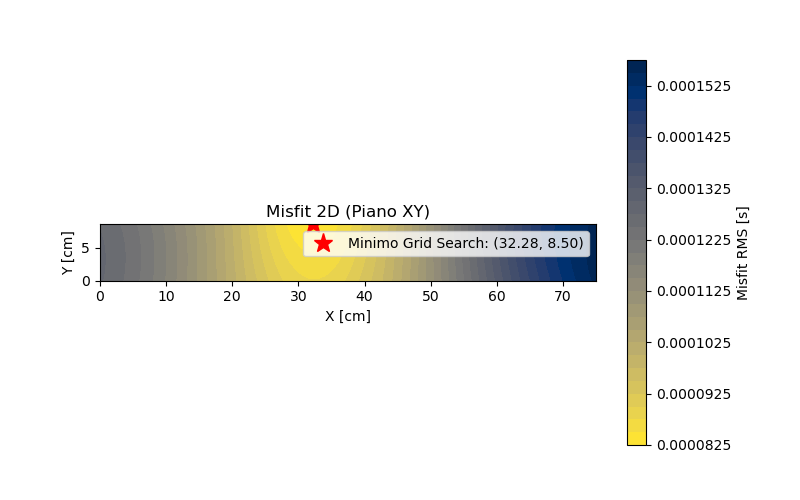

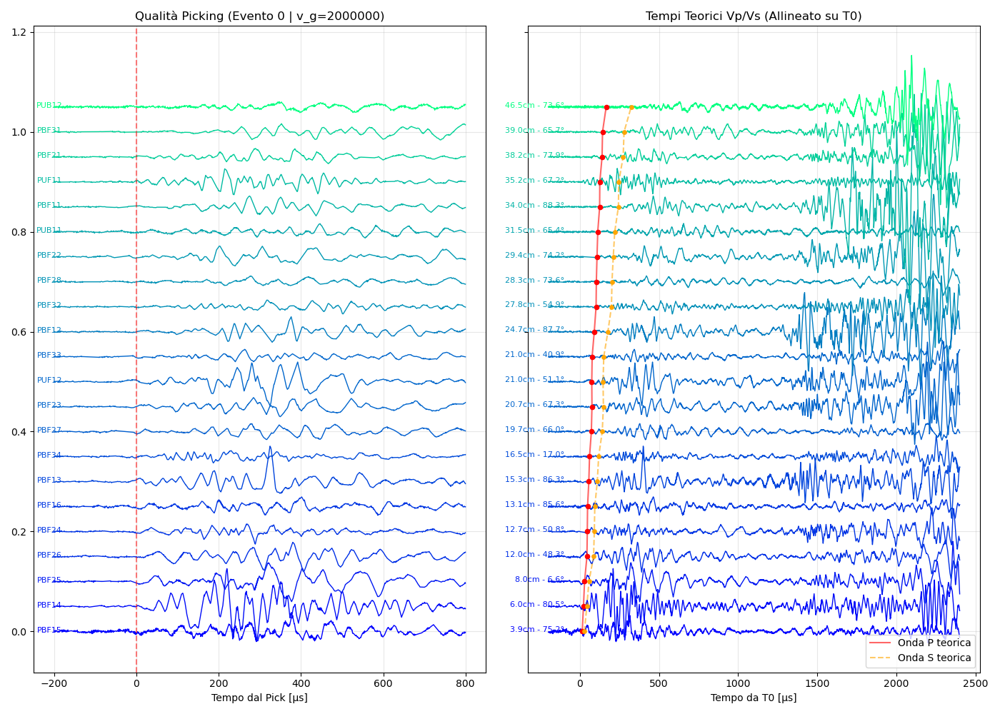


          CONFRONTO DIAGNOSI ED ERRORE TRA I METODI (v_g = 2000000)

--- RESIDUI TEMPORALI PER SINGOLO CANALE [µs] ---
Canale       | Grid Search [µs]     | Inversione [µs]     
----------------------------------------------------------
Ch 4  (PBF15) |             -80.47 |             -78.58
Ch 3  (PBF14) |             -32.16 |             -32.37
Ch 11 (PBF25) |             -28.83 |             -28.09
Ch 12 (PBF26) |             -62.68 |             -61.02
Ch 10 (PBF24) |              -9.34 |              -9.32
Ch 5  (PBF16) |             +11.84 |             +13.75
Ch 2  (PBF13) |             +19.07 |             +18.84
Ch 28 (PBF34) |             +88.56 |             +89.11
Ch 13 (PBF27) |             +23.92 |             +25.75
Ch 9  (PBF23) |              -2.66 |              -2.81
Ch 22 (PUF12) |              -8.43 |              -8.40
Ch 27 (PBF33) |              +2.66 |              +2.81
Ch 1  (PBF12) |              +3.17 |              +2.94
Ch 26 (PBF32) |             -19.78

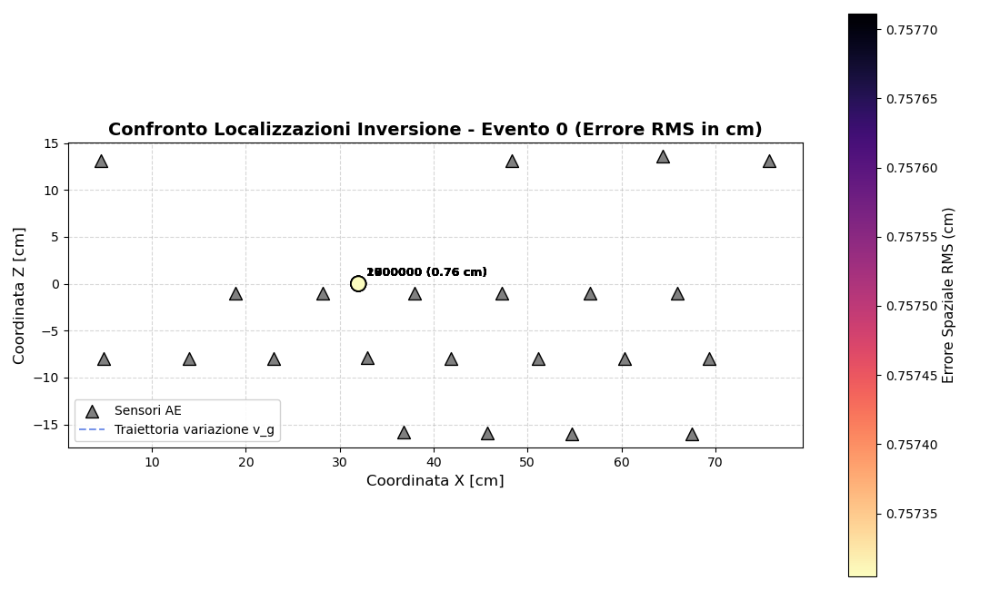

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

# =============================================================================
# ESECUZIONE ANALISI LOCALIZZAZIONE PER DIVERSE VELOCITÀ DEL GOUGE
# =============================================================================
v_g_list = [1500000, 1600000, 1700000, 1800000, 1900000, 2000000]

# Estrazione velocità onda P per conversione del residuo medio
vp_val = (
    vp if 'vp' in globals() else 500000.0
)  # Velocità P di default (cm/s) se non dichiarata globale

# Structure to store hypocenters across different v_g iterations
summary_results = []

if len(final_groups) > EVENT_TO_ANALYZE:
  # 1. Preparazione DTOA (comune a tutte le iterazioni)
  dtoa_res, coords_res, pairs_res, active_times_res = prepare_event_data(
      evento_picks, AE_sensors_list, channel_to_sensor_idx
  )

  if dtoa_res is None:
    print(
        f"[X] Evento {EVENT_TO_ANALYZE} con sensori attivi insufficienti per la"
        " localizzazione."
    )
  else:
    # ITERAZIONE SULLE VELOCITÀ DEL GOUGE
    for v_g in v_g_list:
      print("\n" + "#" * 70)
      print(f"    ANALISI CON VELOCITÀ GOUGE v_g = {v_g}")
      print("#" * 70)

      # 2. Inizializzazione modello DS con la velocità v_g corrente
      event_sim_res = DS(
          dimensions=ds_dimensions,
          grid_res=(80, 20, 5),  # 8000 punti sulla griglia globale
          AE_sensors=AE_sensors_list,
          v_upper=v_u,
          v_lower=v_l,
          v_gouge=v_g,
          x_shift=0.0,
          use_snell=True,
      )

      # 3. PASSO 1: GRID SEARCH PURA
      grid_pts, misfit = event_sim_res.compute_misfit_event(
          dtoa_res, coords_res, pairs_res
      )
      best_idx = np.argmin(misfit)
      hypocenter_grid = grid_pts[best_idx]

      # 4. PASSO 2: RAFFINAMENTO CONTINUO
      hypocenter_inv = event_sim_res.invert_location_event(
          dtoa_res, coords_res, pairs_res, initial_guess=hypocenter_grid
      )

      print(
          f"\n=== RISULTATI LOCALIZZAZIONE (EVENTO {EVENT_TO_ANALYZE} | v_g ="
          f" {v_g}) ==="
      )
      print(
          "Grid Search (nodo discreto) :"
          f" X={hypocenter_grid[0]:.2f} cm, Y={hypocenter_grid[1]:.2f} cm,"
          f" Z={hypocenter_grid[2]:.2f} cm | Misfit={misfit[best_idx]:.3e} s"
      )
      print(
          "Inversione (spazio continuo):"
          f" X={hypocenter_inv[0]:.2f} cm, Y={hypocenter_inv[1]:.2f} cm,"
          f" Z={hypocenter_inv[2]:.2f} cm"
      )

      # Mappa 2D del Misfit individuale
      event_sim_res.plot_misfit(dtoa_res, coords_res, pairs_res)

      # =============================================================================
      # 5. TRACCIAMENTO WAVEFORMS E CONFRONTO DIAGNOSI
      # =============================================================================
      hypocenter = hypocenter_inv

      recorded_data = []
      recorded_names = []
      used_channels = set()

      for p in evento_picks:
        ch = p["ch"]
        if ch in used_channels or ch not in channel_to_sensor_idx:
          continue
        used_channels.add(ch)

        ch_name = channels_names[ch]
        sensor_coord = AE_sensors_list[channel_to_sensor_idx[ch]]

        vec = sensor_coord - hypocenter
        dist = np.linalg.norm(vec)
        vec_norm = vec / dist if dist > 0 else vec

        normal = np.array([0, 0, 1])
        angle_inc = np.degrees(
            np.arccos(np.clip(np.abs(np.dot(vec_norm, normal)), -1.0, 1.0))
        )

        recorded_data.append({
            "pick": p,
            "dist": dist,
            "name": ch_name,
            "angle_inc": angle_inc,
        })
        recorded_names.append(ch_name)

      recorded_data = sorted(recorded_data, key=lambda x: x["dist"])

      picks_ordered = [x["pick"] for x in recorded_data]
      dist_ordered = [x["dist"] for x in recorded_data]
      names_ordered = [x["name"] for x in recorded_data]
      angle_inc_ordered = [x["angle_inc"] for x in recorded_data]

      def calc_location_errors(hypo_pt):
        tt_p_vec = [
            event_sim_res._get_single_tt(
                hypo_pt, AE_sensors_list[channel_to_sensor_idx[p["ch"]]]
            )
            for p in picks_ordered
        ]

        t0 = np.median(
            [p["time"] - tt for p, tt in zip(picks_ordered, tt_p_vec)]
        )
        res_us = np.array([
            (p["time"] - (t0 + tt)) * 1e6
            for p, tt in zip(picks_ordered, tt_p_vec)
        ])
        res_mean_abs = np.mean(np.abs(res_us))
        
        # MISFIT IN SECONDI CONVERTITO IN CM (Usando Vp)
        err_scalare = (vp_val * res_mean_abs) / 1e6

        res_s = res_us / 1e6
        var_t = np.var(res_s) if len(res_s) > 1 else 1e-12

        J = np.zeros((len(pairs_res), 3))
        eps = 1e-2

        T_base = np.array(
            [event_sim_res._get_single_tt(hypo_pt, s) for s in coords_res]
        )
        dtoa_base = np.array([T_base[j] - T_base[i] for i, j in pairs_res])

        for d in range(3):
          m_p = hypo_pt.copy()
          m_p[d] += eps
          T_p = np.array(
              [event_sim_res._get_single_tt(m_p, s) for s in coords_res]
          )
          dtoa_p = np.array([T_p[j] - T_p[i] for i, j in pairs_res])
          J[:, d] = (dtoa_p - dtoa_base) / eps

        try:
          cov_m = var_t * np.linalg.inv(J.T @ J + 1e-8 * np.eye(3))
          err_x, err_y, err_z = np.sqrt(np.maximum(0, np.diag(cov_m)))
          err_3d = np.sqrt(err_x**2 + err_y**2 + err_z**2)
        except np.linalg.LinAlgError:
          err_x = err_y = err_z = err_3d = np.nan

        return {
            "t0": t0,
            "tt_p": tt_p_vec,
            "res_us": res_us,
            "res_mean_abs": res_mean_abs,
            "err_scalare": err_scalare,
            "err_x": err_x,
            "err_y": err_y,
            "err_z": err_z,
            "err_3d": err_3d,
        }

      diag_grid = calc_location_errors(hypocenter_grid)
      diag_inv = calc_location_errors(hypocenter_inv)

      # RMS in cm direttamente basato sul misfit temporale medio convertito con Vp
      rms_cm_val = diag_inv["err_scalare"]

      # Salva il risultato completo per il grafico finale
      summary_results.append({
          "v_g": v_g,
          "hypo_grid": hypocenter_grid,
          "hypo_inv": hypocenter_inv,
          "misfit_s": misfit[best_idx],
          "rms_cm": rms_cm_val,
      })

      # Plot Waveforms
      time_window_us = 800
      samples_window = int((time_window_us / 1e6) * fsAE)
      v_offset_step = 0.05

      norm = plt.Normalize(
          vmin=min(dist_ordered) if dist_ordered else 0,
          vmax=max(dist_ordered) if dist_ordered else 1,
      )
      cmap = cm.winter

      fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 10), sharey=True)

      for i, (pick, d, name, tt_p_val) in enumerate(
          zip(picks_ordered, dist_ordered, names_ordered, diag_inv["tt_p"])
      ):
        data_idx = pick["ch"]
        if data_idx < 0 or data_idx >= len(data_chunkF):
          continue

        trace = data_chunkF[data_idx]
        v_offset = i * v_offset_step
        color = cmap(norm(d))

        cp = int(pick["time"] * fsAE)
        s1, e1 = cp - samples_window // 4, cp + samples_window
        seg1 = trace[max(0, s1) : min(len(trace), e1)]
        t_ax1 = (np.arange(len(seg1)) / fsAE) - ((cp - max(0, s1)) / fsAE)

        ax1.plot(t_ax1 * 1e6, seg1 + v_offset, color=color, lw=1)
        ax1.text(
            t_ax1[0] * 1e6 + 20,
            v_offset + 0.002,
            name,
            fontsize=8,
            ha="right",
            va="center",
            color=color,
        )

        co = int(diag_inv["t0"] * fsAE)
        s2, e2 = co - samples_window // 4, co + int(samples_window * 3)
        seg2 = trace[max(0, s2) : min(len(trace), e2)]
        t_ax2 = (np.arange(len(seg2)) / fsAE) - ((co - max(0, s2)) / fsAE)

        ax2.plot(t_ax2 * 1e6, seg2 + v_offset, color=color, lw=1)
        ax2.text(
            t_ax2[0] * 1e6 + 100,
            v_offset + 0.003,
            f"{d:.1f}cm - {angle_inc_ordered[i]:.1f}°",
            fontsize=8,
            ha="right",
            va="center",
            color=color,
        )

        tt_s_val = tt_p_val * (vp / vs) if vs > 0 else tt_p_val * 1.73
        ax2.scatter(tt_p_val * 1e6, v_offset, color="red", s=20, zorder=5)
        ax2.scatter(tt_s_val * 1e6, v_offset, color="orange", s=15, zorder=5)

      ax2.plot(
          [tt * 1e6 for tt in diag_inv["tt_p"]],
          [i * v_offset_step for i in range(len(dist_ordered))],
          color="red",
          alpha=0.6,
          label="Onda P teorica",
      )
      ax2.plot(
          [tt * (vp / vs) * 1e6 for tt in diag_inv["tt_p"]],
          [i * v_offset_step for i in range(len(dist_ordered))],
          color="orange",
          alpha=0.6,
          ls="--",
          label="Onda S teorica",
      )

      ax1.set_title(
          f"Qualità Picking (Evento {EVENT_TO_ANALYZE} | v_g={v_g})",
          fontsize=12,
      )
      ax2.set_title("Tempi Teorici Vp/Vs (Allineato su T0)", fontsize=12)
      ax1.set_xlabel("Tempo dal Pick [µs]")
      ax2.set_xlabel("Tempo da T0 [µs]")

      ax1.axvline(0, color="red", ls="--", alpha=0.5)
      ax1.grid(True, alpha=0.3)
      ax2.grid(True, alpha=0.3)
      ax2.legend(loc="lower right")

      plt.tight_layout()
      plt.show()

      # =============================================================================
      # 6. REPORT CONFRONTO PER LA VELOCITÀ CORRENTE
      # =============================================================================
      print("\n" + "=" * 70)
      print(
          "        CONFRONTO DIAGNOSI ED ERRORE TRA I METODI (v_g ="
          f" {v_g})"
      )
      print("=" * 70)

      print("\n--- RESIDUI TEMPORALI PER SINGOLO CANALE [µs] ---")
      print(f"{'Canale':<12} | {'Grid Search [µs]':<20} | {'Inversione [µs]':<20}")
      print("-" * 58)
      for p, r_grid, r_inv in zip(
          picks_ordered, diag_grid["res_us"], diag_inv["res_us"]
      ):
        ch_name = channels_names[p["ch"]]
        print(
            f"Ch {p['ch']:<2d} ({ch_name:<4s}) | {r_grid:+18.2f} |"
            f" {r_inv:+18.2f}"
        )

      print("-" * 70)
      print("\n--- ERRORE TEMPORALE CONVERTITO IN CM (MISFIT RESIDUO) ---")
      print(
          f"Grid Search : Residuo Medio = {diag_grid['res_mean_abs']:.2f} µs |"
      )
      print(
          f"Inversione  : Residuo Medio = {diag_inv['res_mean_abs']:.2f} µs |"
          f" Misfit in cm = {diag_inv['err_scalare']:.2f} cm"
      )
      print("=" * 70)

    # =============================================================================
    # 7. GRAFICO UNIFICATO: CONFRONTO DI TUTTI GLI IPOCENTRI CON MISFIT IN CM
    # =============================================================================
    fig, ax = plt.subplots(figsize=(11, 6.5))

    # Sensor positions
    if coords_res is not None and len(coords_res) > 0:
      ax.scatter(
          coords_res[:, 0],
          coords_res[:, 2],
          marker="^",
          c="gray",
          s=100,
          edgecolors="k",
          label="Sensori AE",
          zorder=2,
      )

    # Extract coordinates, velocities and RMS errors (in cm)
    x_coords = [r["hypo_inv"][0] for r in summary_results]
    z_coords = [r["hypo_inv"][2] for r in summary_results]
    rms_cm_list = [r["rms_cm"] for r in summary_results]
    v_g_vals = [r["v_g"] for r in summary_results]

    # Scatter plot with color map corresponding to Misfit in cm
    sc = ax.scatter(
        x_coords,
        z_coords,
        c=rms_cm_list,
        cmap="magma_r",
        s=140,
        edgecolors="black",
        linewidth=1.2,
        zorder=4,
    )

    # Colorbar for Misfit in cm
    cbar = plt.colorbar(sc, ax=ax)
    cbar.set_label("Misfit Temporale convertito in cm", fontsize=11)

    # Trajectory line connecting consecutive gouge velocities
    ax.plot(
        x_coords,
        z_coords,
        linestyle="--",
        color="royalblue",
        alpha=0.7,
        linewidth=1.5,
        label="Traiettoria variazione v_g",
        zorder=3,
    )

    # Annotate points with velocity and Misfit in cm
    for x, z, v, err_cm in zip(x_coords, z_coords, v_g_vals, rms_cm_list):
      ax.annotate(
          f"{v:.0f} ({err_cm:.2f} cm)",
          (x, z),
          xytext=(6, 6),
          textcoords="offset points",
          fontsize=9,
          fontweight="bold",
      )

    ax.set_title(
        f"Confronto Localizzazioni Inversione - Evento {EVENT_TO_ANALYZE} (Misfit in cm)",
        fontsize=14,
        fontweight="bold",
    )
    ax.set_xlabel("Coordinata X [cm]", fontsize=12)
    ax.set_ylabel("Coordinata Z [cm]", fontsize=12)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="best", framealpha=0.9)
    ax.set_aspect("equal", adjustable="box")

    plt.tight_layout()
    plt.show()

else:
  print(f"Nessun evento disponibile con indice {EVENT_TO_ANALYZE}.")

In [43]:
def save_localization_summary(summary_results, experiment_name, current_event_num):
    """
    Saves the summary results of an experiment/event into a structured dictionary.
    """
    return {
        "experiment_name": experiment_name,
        "event_num": current_event_num,
        "v_g": [r["v_g"] for r in summary_results],
        "rms_cm": [r["rms_cm"] for r in summary_results],
        "hypo_inv_x": [r["hypo_inv"][0] for r in summary_results],
        "hypo_inv_z": [r["hypo_inv"][2] for r in summary_results],
    }

In [49]:
manual_data = save_localization_summary(summary_results, experiment_name, current_event_num)

In [24]:
sta_5khz_data = save_localization_summary(summary_results, experiment_name, current_event_num)

In [31]:
sta_7khz_data = save_localization_summary(summary_results, experiment_name, current_event_num)

In [ ]:
def plot_multi_experiment_scatter(exp_dict_collection):
    """
    Plots temporal misfit RMS error (converted to cm) vs Gouge Velocity for multiple experiments, 
    calculates differences, color-codes points, and labels lines at the beginning (underneath).
    
    Parameters:
    ----------
    exp_dict_collection : dict
        A dictionary where the keys are the variable names 
        and the values are the experiment dictionaries containing "v_g" 
        and "rms_cm".
    """
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Track all color differences to set a shared or individual color scale
    all_diffs_from_first = []
    for exp in exp_dict_collection.values():
        spatial_err_key = next((k for k in ["rms_cm", "spatial_error", "spatial_err", "err_3d"] if k in exp), None)
        if spatial_err_key is None:
            continue
            
        spatial_vals = np.array(exp[spatial_err_key])
        if len(spatial_vals) > 0:
            diff_from_first = spatial_vals - spatial_vals[0]
            all_diffs_from_first.extend(diff_from_first)
            
    # Iterate through the dictionary names (keys) and their data (values)
    for dict_name, exp in exp_dict_collection.items():
        v_g_scaled = [v / 1e5 for v in exp["v_g"]]
        
        spatial_err_key = next((k for k in ["rms_cm", "spatial_error", "spatial_err", "err_3d"] if k in exp), None)
        if spatial_err_key is None:
            print(f"[Warning] Nessuna chiave di errore trovata per '{dict_name}'. Salto.")
            continue
            
        spatial_vals = np.array(exp[spatial_err_key])
        
        if len(spatial_vals) == 0:
            continue
            
        # 1. Calculate difference between each value and the previous one
        diff_from_previous = np.diff(spatial_vals, prepend=spatial_vals[0])
        
        # 2. Calculate difference between each value and the first error point
        diff_from_first = spatial_vals - spatial_vals[0]
        
        # Plot connecting line
        ax.plot(
            v_g_scaled, 
            spatial_vals, 
            linestyle='-', 
            linewidth=1.5, 
            color='gray', 
            alpha=0.6,
            zorder=2
        )
        
        # Plot scatter points colored by the difference from the first point
        sc = ax.scatter(
            v_g_scaled, 
            spatial_vals, 
            c=diff_from_first, 
            cmap='plasma', 
            s=50, 
            edgecolors='black',
            linewidths=0.8,
            zorder=3
        )
        
        # --- Direct Line Labeling at the Beginning (Underneath) ---
        if len(v_g_scaled) > 1:
            first_x = v_g_scaled[1]
            first_y = spatial_vals[1]
        else:
            first_x = v_g_scaled[0]
            first_y = spatial_vals[0]
        
        y_range = ax.get_ylim()[1] - ax.get_ylim()[0] if ax.get_ylim()[1] != ax.get_ylim()[0] else 1.0
        offset_y = y_range * 0.03
        
        ax.text(
            first_x, first_y - offset_y,
            f"{dict_name}", 
            fontsize=10, 
            fontweight='semibold', 
            va='top', 
            ha='center',
            color='black'
        )
    
    # Add a colorbar for the colormap scale
    if 'sc' in locals():
        cbar = plt.colorbar(sc, ax=ax)
        cbar.set_label("Misfit Difference from First Point [cm]", fontsize=11)
    
    # Axis formatting and labels
    ax.set_xlabel("Gouge Velocity $v_g$ [$\\times 10^5$ cm/s]", fontsize=12)
    ax.set_ylabel("Misfit RMS [cm]", fontsize=12)
    ax.set_title(
        "Misfit RMS Comparison Across Gouge Velocities",
        fontsize=14,
        fontweight="bold",
    )
    
    ax.grid(True, linestyle="--", alpha=0.4, axis="both", zorder=0)
    
    plt.tight_layout()
    plt.show()

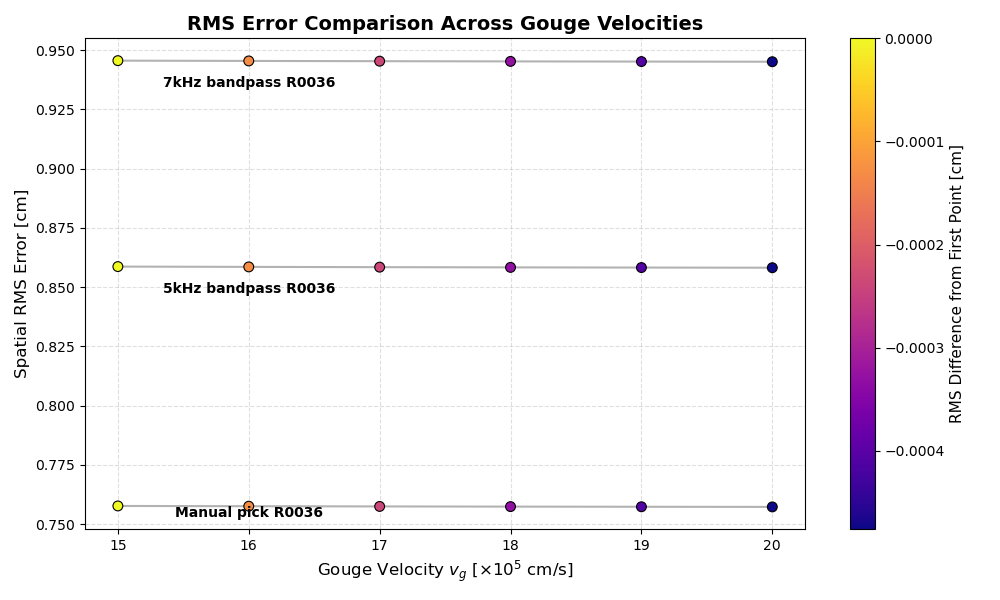

In [ ]:
# Group them into a dictionary with their names as keys
all_experiments = {
    "Manual pick R0036": manual_data,
    "7kHz bandpass R0036": sta_7khz_data,
    "5kHz bandpass R0036": sta_5khz_data,
}

# Run the plot function
plot_multi_experiment_scatter(all_experiments)

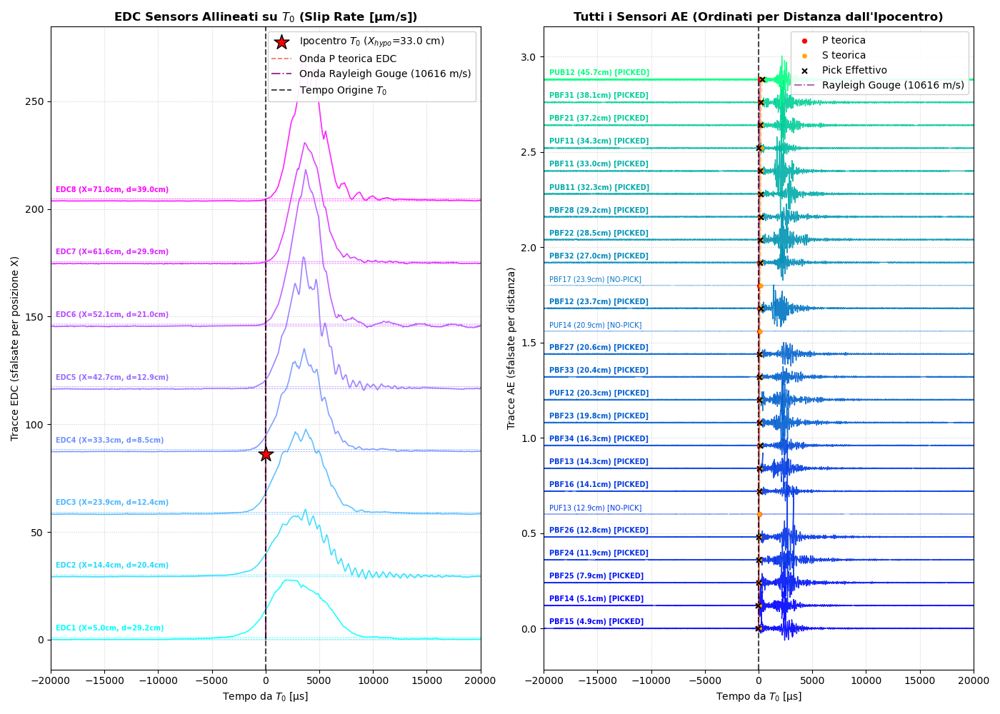

In [30]:
# -----------------------------------------------------------------------------
# 0. SELEZIONE IPOCENTRO, CALCOLO VELOCITÀ RAYLEIGH IN GOUGE E T0
# -----------------------------------------------------------------------------
# Usa l'ipocentro invertito continuo (o fallback sulla Grid Search)
hypocenter = hypocenter_inv if "hypocenter_inv" in locals() else hypocenter_grid

# --- CALCOLO VELOCITÀ DI RAYLEIGH IN GOUGE ---
vp_gouge = v_g / 100 
vs_gouge = vp_gouge / np.sqrt(3)  # [m/s] (assumendo nu = 0.25)
vr_gouge = vs_gouge * 0.9194  # [m/s] Velocità onda di Rayleigh in gouge
#vr_gouge=200
# Calcolo del tempo di origine T0 basato sui pick attivi e l'ipocentro corrente
tt_picks_p = [
    event_sim_res._get_single_tt(
        hypocenter, AE_sensors_list[channel_to_sensor_idx[p["ch"]]]
    )
    for p in evento_picks
    if p["ch"] in channel_to_sensor_idx
]
picks_times = [
    p["time"] for p in evento_picks if p["ch"] in channel_to_sensor_idx
]

# T0 stimato come mediana dei (tempo_pick - tempo_di_volo)
t0_event = np.median([pt - tt for pt, tt in zip(picks_times, tt_picks_p)])

# -----------------------------------------------------------------------------
# 1. IMPOSTAZIONI FINESTRA VISIVA & VETTORI TEMPO RELATIVI A T0
# -----------------------------------------------------------------------------
if "timeAE" not in locals() or timeAE is None:
    timeAE = timeS[0] + np.arange(data_chunkF.shape[1]) / fsAE

# Vettore tempo relativo rispetto a T0 in microsecondi [µs]
t_ae_rel_us = (timeAE - timeAE[0] - t0_event) * 1e6
t_edc_rel_us = (timeS - timeS[0] - t0_event) * 1e6

# Limiti finestra temporale zoomata attorno a T0 [µs]
x_min, x_max = -20000, 20000

# -----------------------------------------------------------------------------
# 2. POSIZIONAMENTO E ORDINAMENTO SENSORI EDDY CURRENT (EDC)
# -----------------------------------------------------------------------------
n_edc = (
    slip_ratesR.shape[0] if "slip_ratesR" in locals() else to_takeZ.shape[0]
)

# Posizionamento EDC: da X = 5 cm a X = 71 cm (equispaziati)
x_edc = np.linspace(5, 71, n_edc)

# Coordinate EDC: X da 5 a 71 cm, Y=0 (front), Z=0
edc_coords = np.column_stack([x_edc, np.zeros(n_edc), np.zeros(n_edc)])
edc_distances = np.array(
    [np.linalg.norm(c - hypocenter) for c in edc_coords]
)  # [cm]

# Selezione dati EDC (Slip Rate o Slip)
use_slip_rate = True
if use_slip_rate and "slip_ratesR" in locals():
    edc_data = slip_ratesR
    edc_label = "Slip Rate [µm/s]"
else:
    edc_data = to_takeZ
    edc_label = "Slip [µm]"

# -----------------------------------------------------------------------------
# 3. ANALISI COMPLETA DI TUTTI I SENSORI ACOUSTIC EMISSION (AE)
# -----------------------------------------------------------------------------
picks_map = {p["ch"]: p for p in evento_picks}
all_ae_info = []

for ch_idx in range(len(channels_names)):
    ch_name = channels_names[ch_idx]

    if ch_idx in channel_to_sensor_idx:
        s_idx = channel_to_sensor_idx[ch_idx]
        coord = AE_sensors_list[s_idx]
        dist = np.linalg.norm(coord - hypocenter)  # [cm]

        # Tempi di volo teorici P ed S
        tt_p = event_sim_res._get_single_tt(hypocenter, coord)
        tt_s = tt_p * (vp / vs) if (vs is not None and vs > 0) else tt_p * 1.73

        is_picked = ch_idx in picks_map
        pick_info = picks_map.get(ch_idx, None)

        all_ae_info.append(
            {
                "ch_idx": ch_idx,
                "name": ch_name,
                "coord": coord,
                "dist": dist,
                "tt_p": tt_p,
                "tt_s": tt_s,
                "is_picked": is_picked,
                "pick": pick_info,
            }
        )

# Ordina TUTTI i sensori AE per distanza dall'ipocentro
all_ae_info = sorted(all_ae_info, key=lambda x: x["dist"])

# -----------------------------------------------------------------------------
# 4. PLOTTING UNIFICATO E ALLINEATO SU T0
# -----------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 10), sharex=True)

# --- PANNELLO 1: EDDY CURRENT (EDC) ---
if edc_data is not None and len(edc_data) > 0:
    max_amp = (
        np.nanmax(np.abs(edc_data)) if np.nanmax(np.abs(edc_data)) != 0 else 1.0
    )
    edc_offset_step = max_amp * 0.4
    edc_offsets = [i * edc_offset_step for i in range(n_edc)]
    cmap_edc = cm.cool

    for i in range(n_edc):
        color = cmap_edc(i / max(1, n_edc - 1))
        offset = edc_offsets[i]
        ax1.plot(
            t_edc_rel_us,
            edc_data[i, :] + offset,
            color=color,
            linewidth=1.2,
            alpha=0.85,
        )
        ax1.plot(
            t_edc_rel_us,
            (np.ones(len(edc_data[i, :])) * 1.0) + offset,
            color=color,
            linestyle="--",
            linewidth=0.5,
            alpha=0.85,
        )

        ax1.plot(
            t_edc_rel_us,
            (np.ones(len(edc_data[i, :])) * 0.1) + offset,
            color=color,
            linestyle="--",
            linewidth=0.5,
            alpha=0.85,
        )

        label_txt = (
            f"EDC{i+1} (X={x_edc[i]:.1f}cm, d={edc_distances[i]:.1f}cm)"
        )
        ax1.text(
            x_min + 500,
            offset + (max_amp * 0.05),
            label_txt,
            fontsize=7,
            ha="left",
            va="bottom",
            color=color,
            fontweight="bold",
        )

    # --- STELLA IPOCENTRO SUL GRAFICO EDC ---
    x_hypo = hypocenter[0]
    y_hypo_offset = np.interp(x_hypo, x_edc, edc_offsets)

    ax1.scatter(
        0,
        y_hypo_offset,
        color="red",
        marker="*",
        s=250,
        zorder=10,
        edgecolors="black",
        label=f"Ipocentro $T_0$ ($X_{{hypo}}$={x_hypo:.1f} cm)",
    )

    # Arrivi teorici P ed Onda di Rayleigh nel Gouge su EDC
    tt_p_edc = [
        event_sim_res._get_single_tt(hypocenter, c) * 1e6 for c in edc_coords
    ]
    tt_rayleigh_edc = (edc_distances / 100.0) / vr_gouge * 1e6  # [µs]

    ax1.plot(
        tt_p_edc,
        edc_offsets,
        color="red",
        linestyle="--",
        alpha=0.6,
        lw=1.2,
        label="Onda P teorica EDC",
    )
    ax1.plot(
        tt_rayleigh_edc,
        edc_offsets,
        color="purple",
        linestyle="-.",
        alpha=0.8,
        lw=1.4,
        label=f"Onda Rayleigh Gouge ({vr_gouge:.0f} m/s)",
    )

    ax1.set_title(
        f"EDC Sensors Allineati su $T_0$ ({edc_label})",
        fontsize=12,
        fontweight="bold",
    )
    ax1.set_ylabel("Tracce EDC (sfalsate per posizione X)")
    ax1.set_xlabel("Tempo da $T_0$ [µs]")
    ax1.axvline(
        0, color="k", linestyle="--", alpha=0.7, label="Tempo Origine $T_0$"
    )
    ax1.grid(True, linestyle=":", alpha=0.6)
    ax1.legend(loc="upper right", framealpha=0.9)

# --- PANNELLO 2: TUTTI I SENSORI AE (PICKED & UNPICKED) ---
ae_offset_step = 0.12
cmap_ae = cm.winter
max_dist_ae = max((x["dist"] for x in all_ae_info), default=1.0)
min_dist_ae = min((x["dist"] for x in all_ae_info), default=0.0)

norm_ae = plt.Normalize(vmin=min_dist_ae, vmax=max_dist_ae)

p_labeled, s_labeled, rayleigh_labeled, pick_labeled = (
    False,
    False,
    False,
    False,
)

for idx, info in enumerate(all_ae_info):
    ch_idx = info["ch_idx"]
    trace = data_chunkF[ch_idx]
    offset = idx * ae_offset_step
    dist = info["dist"]
    color = cmap_ae(norm_ae(dist))

    if info["is_picked"]:
        alpha = 0.9
        lw = 1.0
        status_str = "PICKED"
    else:
        alpha = 0.4
        lw = 0.6
        status_str = "NO-PICK"

    ax2.plot(
        t_ae_rel_us,
        trace + offset,
        color=color,
        alpha=alpha,
        linewidth=lw,
    )

    label_txt = f"{info['name']} ({dist:.1f}cm) [{status_str}]"
    ax2.text(
        x_min + 500,
        offset + 0.015,
        label_txt,
        fontsize=7,
        ha="left",
        va="bottom",
        color=color,
        fontweight="bold" if info["is_picked"] else "normal",
    )

    tp_us = info["tt_p"] * 1e6
    ts_us = info["tt_s"] * 1e6

    ax2.scatter(
        tp_us,
        offset,
        color="red",
        s=18,
        zorder=5,
        label="P teorica" if not p_labeled else "",
    )
    p_labeled = True

    ax2.scatter(
        ts_us,
        offset,
        color="orange",
        s=14,
        zorder=5,
        label="S teorica" if not s_labeled else "",
    )
    s_labeled = True

    if info["is_picked"]:
        pick_time_rel_us = (info["pick"]["time"] - t0_event) * 1e6
        ax2.scatter(
            pick_time_rel_us,
            offset,
            color="black",
            marker="x",
            s=25,
            zorder=6,
            label="Pick Effettivo" if not pick_labeled else "",
        )
        pick_labeled = True

tt_p_vec = [x["tt_p"] * 1e6 for x in all_ae_info]
tt_s_vec = [x["tt_s"] * 1e6 for x in all_ae_info]
tt_rayleigh_ae_vec = [
    (x["dist"] / 100.0) / vr_gouge * 1e6 for x in all_ae_info
]
offsets_vec = [i * ae_offset_step for i in range(len(all_ae_info))]

ax2.plot(tt_p_vec, offsets_vec, color="red", alpha=0.5, ls="-", lw=1.2)
ax2.plot(tt_s_vec, offsets_vec, color="orange", alpha=0.5, ls="--", lw=1.2)
ax2.plot(
    tt_rayleigh_ae_vec,
    offsets_vec,
    color="purple",
    alpha=0.7,
    ls="-.",
    lw=1.2,
    label=f"Rayleigh Gouge ({vr_gouge:.0f} m/s)",
)

ax2.set_title(
    "Tutti i Sensori AE (Ordinati per Distanza dall'Ipocentro)",
    fontsize=12,
    fontweight="bold",
)
ax2.set_xlabel("Tempo da $T_0$ [µs]")
ax2.set_ylabel("Tracce AE (sfalsate per distanza)")
ax2.axvline(0, color="k", linestyle="--", alpha=0.7)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="upper right", framealpha=0.9)

# -----------------------------------------------------------------------------
# 5. IMPOSTAZIONE LIMITI ASSE X [-20000, 20000] µs
# -----------------------------------------------------------------------------
ax1.set_xlim(x_min, x_max)

plt.tight_layout()
plt.show()


######################################################################
   ANALISI EDC / AE PER VELOCITÀ GOUGE v_g = 1500000 cm/s
######################################################################


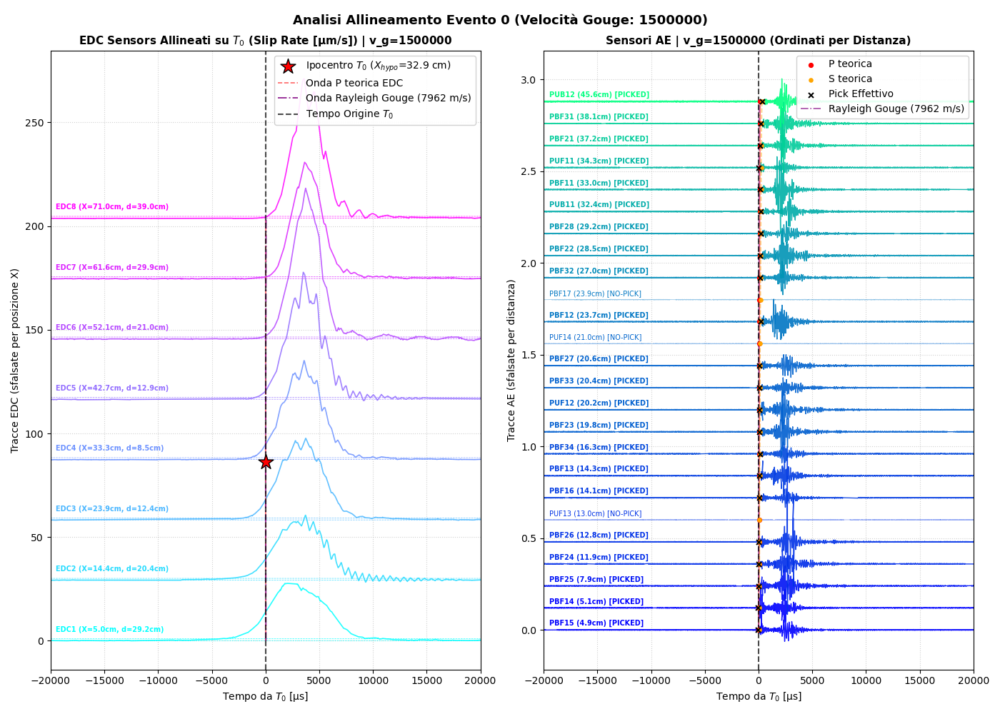


######################################################################
   ANALISI EDC / AE PER VELOCITÀ GOUGE v_g = 1600000 cm/s
######################################################################


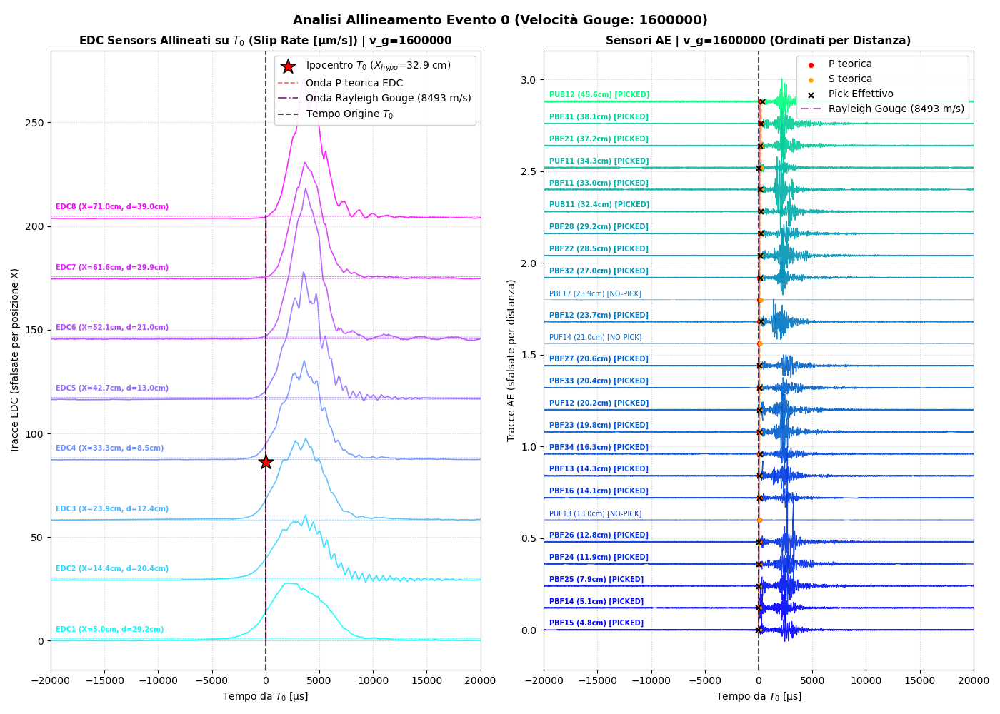


######################################################################
   ANALISI EDC / AE PER VELOCITÀ GOUGE v_g = 1700000 cm/s
######################################################################


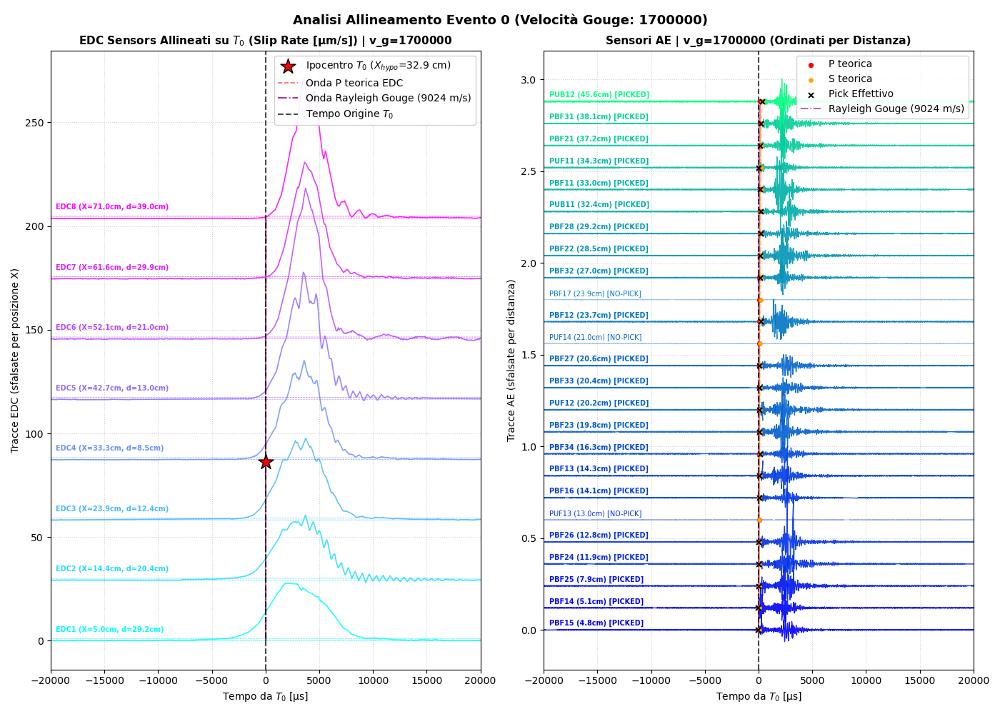


######################################################################
   ANALISI EDC / AE PER VELOCITÀ GOUGE v_g = 1800000 cm/s
######################################################################


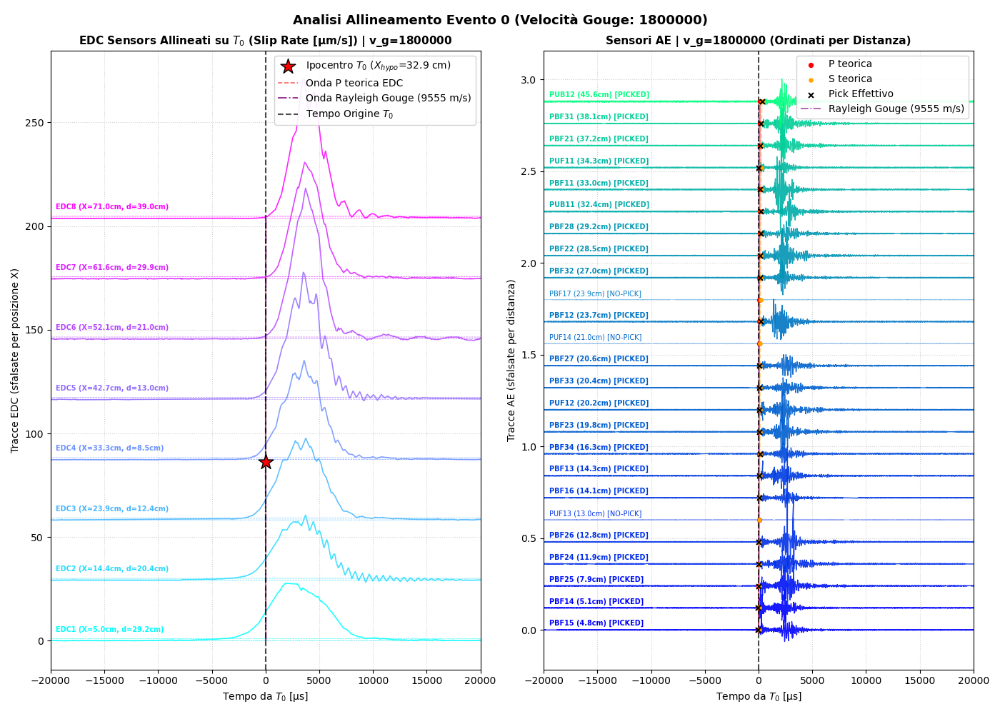


######################################################################
   ANALISI EDC / AE PER VELOCITÀ GOUGE v_g = 1900000 cm/s
######################################################################


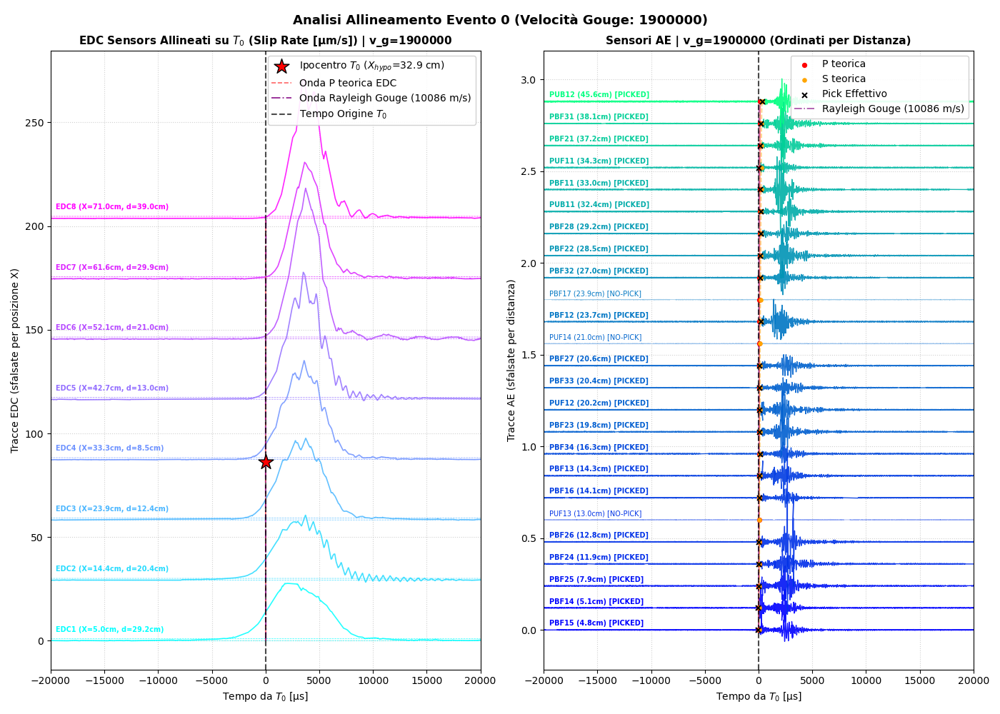


######################################################################
   ANALISI EDC / AE PER VELOCITÀ GOUGE v_g = 2000000 cm/s
######################################################################


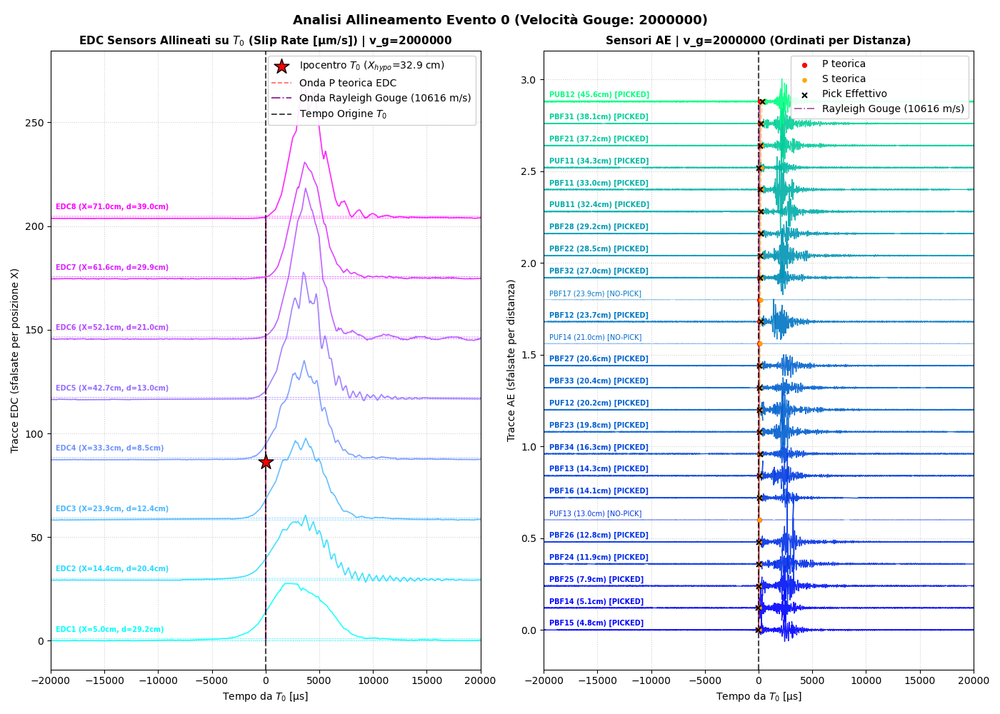

In [40]:
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np

# =============================================================================
# ESECUZIONE ANALISI UNIFICATA EDC/AE PER DIVERSE VELOCITÀ DEL GOUGE
# =============================================================================
v_g_list = [1500000, 1600000, 1700000, 1800000, 1900000, 2000000]

if len(final_groups) > EVENT_TO_ANALYZE:
  evento_picks = final_groups[EVENT_TO_ANALYZE]

  # Preparazione DTOA (comune a tutte le iterazioni)
  dtoa_res, coords_res, pairs_res, active_times_res = prepare_event_data(
      evento_picks, AE_sensors_list, channel_to_sensor_idx
  )

  if dtoa_res is None:
    print(
        f"[X] Evento {EVENT_TO_ANALYZE} con sensori attivi insufficienti per la"
        " localizzazione."
    )
  else:
    # ITERAZIONE SULLE VELOCITÀ DEL GOUGE
    for v_g in v_g_list:
      print("\n" + "#" * 70)
      print(f"   ANALISI EDC / AE PER VELOCITÀ GOUGE v_g = {v_g} cm/s")
      print("#" * 70)

      # -----------------------------------------------------------------------------
      # 0. LOCALIZZAZIONE ED ESTRAZIONE IPOCENTRO CORRENTE
      # -----------------------------------------------------------------------------
      event_sim_res = DS(
          dimensions=ds_dimensions,
          grid_res=(80, 20, 5),
          AE_sensors=AE_sensors_list,
          v_upper=v_u,
          v_lower=v_l,
          v_gouge=v_g,
          x_shift=0.0,
          use_snell=True,
      )

      grid_pts, misfit = event_sim_res.compute_misfit_event(
          dtoa_res, coords_res, pairs_res
      )
      best_idx = np.argmin(misfit)
      hypocenter_grid = grid_pts[best_idx]

      hypocenter_inv = event_sim_res.invert_location_event(
          dtoa_res, coords_res, pairs_res, initial_guess=hypocenter_grid
      )

      hypocenter = hypocenter_inv

      # --- CALCOLO VELOCITÀ DI RAYLEIGH IN GOUGE ---
      # Converti v_g in m/s se espressa in cm/s (es. 1500000 cm/s = 15000 m/s o 1500 m/s)
      vp_gouge_ms = v_g / 100.0 if v_g > 100000 else v_g
      vs_gouge_ms = vp_gouge_ms / np.sqrt(3)  # [m/s] (assumendo nu = 0.25)
      vr_gouge = vs_gouge_ms * 0.9194  # [m/s] Velocità onda di Rayleigh

      # Calcolo del tempo di origine T0
      tt_picks_p = [
          event_sim_res._get_single_tt(
              hypocenter, AE_sensors_list[channel_to_sensor_idx[p["ch"]]]
          )
          for p in evento_picks
          if p["ch"] in channel_to_sensor_idx
      ]
      picks_times = [
          p["time"] for p in evento_picks if p["ch"] in channel_to_sensor_idx
      ]

      t0_event = np.median([pt - tt for pt, tt in zip(picks_times, tt_picks_p)])

      # -----------------------------------------------------------------------------
      # 1. IMPOSTAZIONI FINESTRA VISIVA & VETTORI TEMPO RELATIVI A T0
      # -----------------------------------------------------------------------------
      if "timeAE" not in locals() or timeAE is None:
        timeAE = timeS[0] + np.arange(data_chunkF.shape[1]) / fsAE

      t_ae_rel_us = (timeAE - timeAE[0] - t0_event) * 1e6
      t_edc_rel_us = (timeS - timeS[0] - t0_event) * 1e6

      x_min, x_max = -20000, 20000

      # -----------------------------------------------------------------------------
      # 2. POSIZIONAMENTO E ORDINAMENTO SENSORI EDDY CURRENT (EDC)
      # -----------------------------------------------------------------------------
      n_edc = (
          slip_ratesR.shape[0]
          if "slip_ratesR" in locals()
          else to_takeZ.shape[0]
      )
      x_edc = np.linspace(5, 71, n_edc)

      edc_coords = np.column_stack([x_edc, np.zeros(n_edc), np.zeros(n_edc)])
      edc_distances = np.array(
          [np.linalg.norm(c - hypocenter) for c in edc_coords]
      )  # [cm]

      use_slip_rate = True
      if use_slip_rate and "slip_ratesR" in locals():
        edc_data = slip_ratesR
        edc_label = "Slip Rate [µm/s]"
      else:
        edc_data = to_takeZ
        edc_label = "Slip [µm]"

      # -----------------------------------------------------------------------------
      # 3. ANALISI COMPLETA DI TUTTI I SENSORI ACOUSTIC EMISSION (AE)
      # -----------------------------------------------------------------------------
      picks_map = {p["ch"]: p for p in evento_picks}
      all_ae_info = []

      for ch_idx in range(len(channels_names)):
        ch_name = channels_names[ch_idx]

        if ch_idx in channel_to_sensor_idx:
          s_idx = channel_to_sensor_idx[ch_idx]
          coord = AE_sensors_list[s_idx]
          dist = np.linalg.norm(coord - hypocenter)  # [cm]

          tt_p = event_sim_res._get_single_tt(hypocenter, coord)
          tt_s = (
              tt_p * (vp / vs) if (vs is not None and vs > 0) else tt_p * 1.73
          )

          is_picked = ch_idx in picks_map
          pick_info = picks_map.get(ch_idx, None)

          all_ae_info.append({
              "ch_idx": ch_idx,
              "name": ch_name,
              "coord": coord,
              "dist": dist,
              "tt_p": tt_p,
              "tt_s": tt_s,
              "is_picked": is_picked,
              "pick": pick_info,
          })

      all_ae_info = sorted(all_ae_info, key=lambda x: x["dist"])

      # -----------------------------------------------------------------------------
      # 4. PLOTTING UNIFICATO E ALLINEATO SU T0 PER V_G CORRENTE
      # -----------------------------------------------------------------------------
      fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 10), sharex=True)

      # --- PANNELLO 1: EDDY CURRENT (EDC) ---
      if edc_data is not None and len(edc_data) > 0:
        max_amp = (
            np.nanmax(np.abs(edc_data))
            if np.nanmax(np.abs(edc_data)) != 0
            else 1.0
        )
        edc_offset_step = max_amp * 0.4
        edc_offsets = [i * edc_offset_step for i in range(n_edc)]
        cmap_edc = cm.cool

        for i in range(n_edc):
          color = cmap_edc(i / max(1, n_edc - 1))
          offset = edc_offsets[i]
          ax1.plot(
              t_edc_rel_us,
              edc_data[i, :] + offset,
              color=color,
              linewidth=1.2,
              alpha=0.85,
          )
          ax1.plot(
              t_edc_rel_us,
              (np.ones(len(edc_data[i, :])) * 1.0) + offset,
              color=color,
              linestyle="--",
              linewidth=0.5,
              alpha=0.85,
          )
          ax1.plot(
              t_edc_rel_us,
              (np.ones(len(edc_data[i, :])) * 0.1) + offset,
              color=color,
              linestyle="--",
              linewidth=0.5,
              alpha=0.85,
          )

          label_txt = (
              f"EDC{i+1} (X={x_edc[i]:.1f}cm, d={edc_distances[i]:.1f}cm)"
          )
          ax1.text(
              x_min + 500,
              offset + (max_amp * 0.05),
              label_txt,
              fontsize=7,
              ha="left",
              va="bottom",
              color=color,
              fontweight="bold",
          )

        # Stella Ipocentro
        x_hypo = hypocenter[0]
        y_hypo_offset = np.interp(x_hypo, x_edc, edc_offsets)

        ax1.scatter(
            0,
            y_hypo_offset,
            color="red",
            marker="*",
            s=250,
            zorder=10,
            edgecolors="black",
            label=f"Ipocentro $T_0$ ($X_{{hypo}}$={x_hypo:.1f} cm)",
        )

        # Arrivi teorici P ed Onda di Rayleigh nel Gouge su EDC
        tt_p_edc = [
            event_sim_res._get_single_tt(hypocenter, c) * 1e6 for c in edc_coords
        ]
        tt_rayleigh_edc = (edc_distances / 100.0) / vr_gouge * 1e6  # [µs]

        ax1.plot(
            tt_p_edc,
            edc_offsets,
            color="red",
            linestyle="--",
            alpha=0.6,
            lw=1.2,
            label="Onda P teorica EDC",
        )
        ax1.plot(
            tt_rayleigh_edc,
            edc_offsets,
            color="purple",
            linestyle="-.",
            alpha=0.8,
            lw=1.4,
            label=f"Onda Rayleigh Gouge ({vr_gouge:.0f} m/s)",
        )

        ax1.set_title(
            f"EDC Sensors Allineati su $T_0$ ({edc_label}) | v_g={v_g}",
            fontsize=11,
            fontweight="bold",
        )
        ax1.set_ylabel("Tracce EDC (sfalsate per posizione X)")
        ax1.set_xlabel("Tempo da $T_0$ [µs]")
        ax1.axvline(
            0,
            color="k",
            linestyle="--",
            alpha=0.7,
            label="Tempo Origine $T_0$",
        )
        ax1.grid(True, linestyle=":", alpha=0.6)
        ax1.legend(loc="upper right", framealpha=0.9)

      # --- PANNELLO 2: TUTTI I SENSORI AE ---
      ae_offset_step = 0.12
      cmap_ae = cm.winter
      max_dist_ae = max((x["dist"] for x in all_ae_info), default=1.0)
      min_dist_ae = min((x["dist"] for x in all_ae_info), default=0.0)

      norm_ae = plt.Normalize(vmin=min_dist_ae, vmax=max_dist_ae)

      p_labeled, s_labeled, pick_labeled = False, False, False

      for idx, info in enumerate(all_ae_info):
        ch_idx = info["ch_idx"]
        trace = data_chunkF[ch_idx]
        offset = idx * ae_offset_step
        dist = info["dist"]
        color = cmap_ae(norm_ae(dist))

        alpha = 0.9 if info["is_picked"] else 0.4
        lw = 1.0 if info["is_picked"] else 0.6
        status_str = "PICKED" if info["is_picked"] else "NO-PICK"

        ax2.plot(
            t_ae_rel_us,
            trace + offset,
            color=color,
            alpha=alpha,
            linewidth=lw,
        )

        label_txt = f"{info['name']} ({dist:.1f}cm) [{status_str}]"
        ax2.text(
            x_min + 500,
            offset + 0.015,
            label_txt,
            fontsize=7,
            ha="left",
            va="bottom",
            color=color,
            fontweight="bold" if info["is_picked"] else "normal",
        )

        tp_us = info["tt_p"] * 1e6
        ts_us = info["tt_s"] * 1e6

        ax2.scatter(
            tp_us,
            offset,
            color="red",
            s=18,
            zorder=5,
            label="P teorica" if not p_labeled else "",
        )
        p_labeled = True

        ax2.scatter(
            ts_us,
            offset,
            color="orange",
            s=14,
            zorder=5,
            label="S teorica" if not s_labeled else "",
        )
        s_labeled = True

        if info["is_picked"]:
          pick_time_rel_us = (info["pick"]["time"] - t0_event) * 1e6
          ax2.scatter(
              pick_time_rel_us,
              offset,
              color="black",
              marker="x",
              s=25,
              zorder=6,
              label="Pick Effettivo" if not pick_labeled else "",
          )
          pick_labeled = True

      tt_p_vec = [x["tt_p"] * 1e6 for x in all_ae_info]
      tt_s_vec = [x["tt_s"] * 1e6 for x in all_ae_info]
      tt_rayleigh_ae_vec = [
          (x["dist"] / 100.0) / vr_gouge * 1e6 for x in all_ae_info
      ]
      offsets_vec = [i * ae_offset_step for i in range(len(all_ae_info))]

      ax2.plot(tt_p_vec, offsets_vec, color="red", alpha=0.5, ls="-", lw=1.2)
      ax2.plot(tt_s_vec, offsets_vec, color="orange", alpha=0.5, ls="--", lw=1.2)
      ax2.plot(
          tt_rayleigh_ae_vec,
          offsets_vec,
          color="purple",
          alpha=0.7,
          ls="-.",
          lw=1.2,
          label=f"Rayleigh Gouge ({vr_gouge:.0f} m/s)",
      )

      ax2.set_title(
          f"Sensori AE | v_g={v_g} (Ordinati per Distanza)",
          fontsize=11,
          fontweight="bold",
      )
      ax2.set_xlabel("Tempo da $T_0$ [µs]")
      ax2.set_ylabel("Tracce AE (sfalsate per distanza)")
      ax2.axvline(0, color="k", linestyle="--", alpha=0.7)
      ax2.grid(True, linestyle=":", alpha=0.6)
      ax2.legend(loc="upper right", framealpha=0.9)

      # Impostazione limiti asse X [-20000, 20000] µs
      ax1.set_xlim(x_min, x_max)

      plt.suptitle(
          f"Analisi Allineamento Evento {EVENT_TO_ANALYZE} (Velocità Gouge:"
          f" {v_g})",
          fontsize=13,
          fontweight="bold",
      )
      plt.tight_layout()
      plt.show()

else:
  print(f"Nessun evento disponibile con indice {EVENT_TO_ANALYZE}.")

# Manual interactive picker

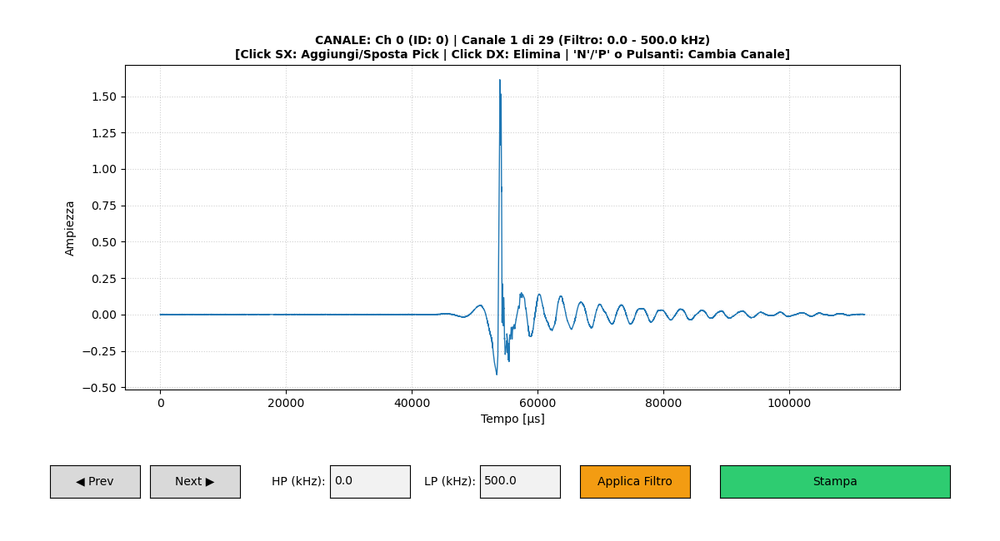


--- Final Picks List ---
[]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Button, TextBox, Cursor
from scipy.signal import butter, filtfilt

class InteractiveAEPickerSingle:
    """
    Interactive tool for the MANUAL picking of acoustic emission (AE) arrival times, one
    channel at a time, in a matplotlib window.

    The waveform of the current channel is shown (optionally band-pass filtered for display)
    and the user can set, move or delete the arrival-time pick of that channel with the mouse,
    browse the channels with buttons or keys, and finally retrieve all the picks as a list of
    dictionaries in the same format as the automatic picker ({'time': ..., 'ch': ...}, time in
    seconds), so that manual and automatic picks can be used interchangeably downstream.

    Controls:
        Left click   : set the pick of the current channel at the clicked time (or move it).
        Right click  : delete the pick of the current channel.
        'n' / right arrow, 'p' / left arrow, or the Prev / Next buttons : change channel.
        's' key or the "Stampa" button : print the current list of picks to the console.
        HP / LP boxes + "Applica Filtro" button : set the high-pass and low-pass corner
            frequencies (kHz) of the display filter and redraw the channel.
        Clicks are ignored while a zoom/pan tool of the matplotlib toolbar is active.

    Notes:
        - Pick times are stored internally in MICROSECONDS (the unit of the time axis shown
          on screen) and converted to SECONDS by `get_picks`.
        - The filter only affects the displayed waveform; the stored picks are just the
          times clicked by the user.
        - An interactive matplotlib backend is required (not an inline/static one).
        - The zoom (X and Y limits) is kept when changing channel or filter, so the
          proportions of the view stay constant from one channel to the next.

    Requires numpy (as np), matplotlib.pyplot (as plt), matplotlib.widgets
    (Button, TextBox, Cursor) and scipy.signal (butter, filtfilt).
    """
    def __init__(
        self,
        data,
        fs,
        channel_ids=None,
        channels_names=None,
        initial_picks=None,
    ):
        """
        INPUT PARAMETERS:
        ----------------
        data : array_like
            Waveforms, shape (n_channels, n_samples) (a 1D array is treated as one channel).
        fs : float
            Sampling frequency in Hz.
        channel_ids : list, optional
            Identifier of each channel (one per row of `data`); these are the values stored
            as 'ch' in the picks. Defaults to 0, 1, 2, ...
        channels_names : list of str, optional
            Name of each channel, shown in the title. Defaults to "Ch <id>".
        initial_picks : list, optional
            Picks to preload, either dictionaries with the keys 'ch' (or 'channel') and
            'time', or (channel, time) sequences. Picks whose channel is not in
            `channel_ids` are ignored. NOTE: the time values are stored as they are and
            are interpreted as MICROSECONDS (see `_load_initial_picks`).
        """
        # Waveforms as a 2D array (channels x samples), sampling frequency and time axis in seconds
        self.data = np.atleast_2d(data)
        self.fs = fs
        self.n_channels, self.n_samples = self.data.shape
        self.time = np.arange(self.n_samples) / self.fs

        # Channel identifiers and names (defaults if not provided)
        self.channel_ids = (
            channel_ids
            if channel_ids is not None
            else list(range(self.n_channels))
        )
        self.channels_names = (
            channels_names
            if channels_names is not None
            else [f"Ch {cid}" for cid in self.channel_ids]
        )

        # Index of the channel currently displayed
        self.current_ch_idx = 0
        self.picks = {}  # Map: channel ID -> pick time in microseconds (None = no pick)

        # Variables that store the current zoom, so that the view proportions stay constant
        self.current_xlim = None
        self.current_ylim = None
        self.cursor = None

        # Load the initial picks, if any
        if initial_picks:
            self._load_initial_picks(initial_picks)

        # Build the window and the widgets, connect the mouse/keyboard events and draw the first channel
        self._setup_plot()
        self._connect_events()
        self._update_plot()

    def _load_initial_picks(self, initial_picks):
        """
        Fills `self.picks` with the preloaded picks. Each element can be a dictionary
        ('ch' or 'channel', and 'time') or a (channel, time) sequence. Elements with an
        unknown channel or an unrecognised format are skipped silently. The time is stored
        without any unit conversion, so it must already be in microseconds.
        """
        for p in initial_picks:
            try:
                ch, t_val = None, None
                if isinstance(p, dict):
                    ch = p.get("ch", p.get("channel"))
                    t_val = p.get("time")
                elif isinstance(p, (list, tuple, np.ndarray)) and len(p) >= 2:
                    ch = p[0]
                    t_val = p[1]
                
                # Keep the pick only if the channel is one of those loaded
                if ch is not None and ch in self.channel_ids:
                    self.picks[ch] = t_val
            except Exception:
                continue

    def apply_bandpass_filter(self, raw_time, amp_vals, low_cutoff_hz=0.0, high_cutoff_hz=1e6):
        """
        Applies a zero-phase Butterworth filter to a waveform, for display purposes.

        Depending on the cutoffs the filter is a band-pass (high-pass and low-pass), a
        high-pass only (low cutoff > 0, no valid high cutoff), a low-pass only
        (low cutoff = 0), or no filter at all. A 4th-order Butterworth filter is applied
        forward and backward with `filtfilt`, which gives zero phase distortion, so the
        timing of the onsets is not shifted by the filter.

        The sampling frequency is re-estimated from the time axis `raw_time`, which can be
        in seconds (step below 1 ms) or in microseconds. The high cutoff is limited to 95%
        of the Nyquist frequency.

        INPUT PARAMETERS:
        ----------------
        raw_time : array_like
            Time axis of the waveform (seconds, or microseconds).
        amp_vals : array_like
            Waveform amplitudes.
        low_cutoff_hz : float
            High-pass corner frequency in Hz (0 = no high-pass).
        high_cutoff_hz : float
            Low-pass corner frequency in Hz.

        OUTPUT PARAMETERS:
        -----------------
        numpy.ndarray
            The filtered waveform. The unfiltered waveform is returned unchanged if the
            input is too short (fewer than 4 samples), the time step is not positive, the
            cutoffs are invalid, or the filter fails.
        """
        # Too few samples to filter
        if len(raw_time) < 4:
            return amp_vals

        # Mean time step; it must be positive
        dt = np.mean(np.diff(raw_time))
        if dt <= 0:
            return amp_vals

        # Convert the step to seconds (a step below 1e-3 is assumed to be already in seconds,
        # otherwise it is assumed to be in microseconds), then compute the sampling and Nyquist frequencies
        dt_sec = dt if dt < 1e-3 else dt * 1e-6
        fs = 1.0 / dt_sec
        nyquist = 0.5 * fs

        # The low-pass corner must stay below the Nyquist frequency
        if high_cutoff_hz >= nyquist:
            high_cutoff_hz = 0.95 * nyquist

        # Which filters are active: high-pass if the low cutoff is positive,
        # low-pass if the high cutoff is above the low cutoff
        use_hp = low_cutoff_hz > 0
        use_lp = high_cutoff_hz > low_cutoff_hz

        try:
            if use_hp and use_lp:
                # Band-pass: corner frequencies normalised by the Nyquist frequency
                low_norm = low_cutoff_hz / nyquist
                high_norm = high_cutoff_hz / nyquist
                if low_norm <= 0 or high_norm >= 1 or low_norm >= high_norm:
                    return amp_vals
                b, a = butter(4, [low_norm, high_norm], btype="bandpass", analog=False)
            elif use_hp:
                # High-pass only
                low_norm = low_cutoff_hz / nyquist
                if low_norm <= 0 or low_norm >= 1:
                    return amp_vals
                b, a = butter(4, low_norm, btype="highpass", analog=False)
            elif use_lp:
                # Low-pass only
                high_norm = high_cutoff_hz / nyquist
                if high_norm <= 0 or high_norm >= 1:
                    return amp_vals
                b, a = butter(4, high_norm, btype="lowpass", analog=False)
            else:
                # No filter requested
                return amp_vals

            # Zero-phase filtering (forward and backward)
            return filtfilt(b, a, amp_vals)
        except Exception:
            # If the filter cannot be applied, show the unfiltered waveform
            return amp_vals

    def _setup_plot(self):
        """
        Creates the figure, the main axes and the control widgets (Prev/Next buttons, HP and
        LP text boxes in kHz, "Applica Filtro" button and "Stampa" button), and links each
        widget to its callback. The widgets are stored as attributes so that they stay
        referenced (and therefore responsive) while the window is open.
        """
        self.fig, self.ax = plt.subplots(figsize=(12, 6.5))
        self.fig.subplots_adjust(bottom=0.28)  # Extra space at the bottom for the controls

        # UI controls (Buttons and Text Boxes): each axes is [left, bottom, width, height] in figure fractions
        ax_prev = plt.axes([0.05, 0.08, 0.09, 0.06])
        ax_next = plt.axes([0.15, 0.08, 0.09, 0.06])
        
        # Band-pass filter section (text boxes and button)
        ax_box_hp = plt.axes([0.33, 0.08, 0.08, 0.06])
        ax_box_lp = plt.axes([0.48, 0.08, 0.08, 0.06])
        ax_filter = plt.axes([0.58, 0.08, 0.11, 0.06])

        ax_print = plt.axes([0.72, 0.08, 0.23, 0.06])

        self.btn_prev = Button(ax_prev, '◀ Prev')
        self.btn_next = Button(ax_next, 'Next ▶')
        
        # Initial filter corners: high-pass 0 kHz (off) and low-pass 500 kHz
        self.txt_hp = TextBox(ax_box_hp, 'HP (kHz): ', initial='0.0')
        self.txt_lp = TextBox(ax_box_lp, 'LP (kHz): ', initial='500.0')
        self.btn_filter = Button(ax_filter, 'Applica Filtro', color='#f39c12')

        self.btn_print = Button(ax_print, 'Stampa', color='#2ecc71')

        # Link the buttons to their callbacks
        self.btn_prev.on_clicked(self.prev_channel)
        self.btn_next.on_clicked(self.next_channel)
        self.btn_filter.on_clicked(self.apply_filter_event)
        self.btn_print.on_clicked(self.print_picks_button)

    def _connect_events(self):
        """Connects the mouse-click and key-press events of the figure to their handlers."""
        self.cid_press = self.fig.canvas.mpl_connect("button_press_event", self.on_press)
        self.cid_key = self.fig.canvas.mpl_connect("key_press_event", self.on_key)

    def _update_plot(self):
        """
        Redraws the main axes for the current channel: reads the filter corners from the text
        boxes, filters and plots the waveform (time axis in microseconds), draws the pick of
        the channel (red dashed line and red cross) if it exists, restores the previous zoom,
        and updates the crosshair cursor and the title.
        """
        # Save the current limits before clearing the axes (avoids a zoom out)
        if hasattr(self, 'ax') and len(self.ax.lines) > 0:
            try:
                self.current_xlim = self.ax.get_xlim()
                self.current_ylim = self.ax.get_ylim()
            except Exception:
                pass

        self.ax.clear()

        # Identifier, name and raw waveform of the current channel
        cid = self.channel_ids[self.current_ch_idx]
        cname = self.channels_names[self.current_ch_idx]
        raw_waveform = self.data[self.current_ch_idx]

        # Apply the band-pass filter using the values in the text boxes (kHz converted to Hz).
        # If a value is not a valid number, the filter falls back to 0 Hz - 1 MHz (practically no filter).
        try:
            hp_khz = float(self.txt_hp.text)
            lp_khz = float(self.txt_lp.text)
            hp_hz = hp_khz * 1e3
            lp_hz = lp_khz * 1e3
        except ValueError:
            hp_hz, lp_hz = 0.0, 1e6

        waveform = self.apply_bandpass_filter(self.time, raw_waveform, low_cutoff_hz=hp_hz, high_cutoff_hz=lp_hz)

        # Plot the filtered waveform of the current channel (time converted from s to µs)
        self.ax.plot(
            self.time * 1e6,
            waveform,
            lw=1.0,
            color="#1f77b4",
            label="Segnale Filtrato"
        )

        # Draw the pick if there is one for this channel: dashed red vertical line plus a red cross at zero amplitude
        if cid in self.picks and self.picks[cid] is not None:
            t_pick_us = self.picks[cid]
            self.ax.axvline(x=t_pick_us, color="red", linestyle="--", linewidth=1.8)
            self.ax.plot(t_pick_us, 0, "rx", markersize=8, markeredgewidth=2)

        # Restore the saved limits to keep the proportions and the zoom unchanged
        if self.current_xlim is not None and self.current_ylim is not None:
            self.ax.set_xlim(self.current_xlim)
            self.ax.set_ylim(self.current_ylim)

        # Initialise the crosshair cursor that follows the mouse (blitting for fast redraw)
        self.cursor = Cursor(self.ax, useblit=True, color='gray', linewidth=0.8, linestyle='--')

        self.ax.set_xlabel("Tempo [µs]")
        self.ax.set_ylabel("Ampiezza")
        # Title: channel name and ID, position in the list, filter band, and a reminder of the controls
        self.ax.set_title(
            f"CANALE: {cname} (ID: {cid}) | Canale {self.current_ch_idx + 1} di {self.n_channels} "
            f"(Filtro: {hp_khz} - {lp_khz} kHz)\n"
            f"[Click SX: Aggiungi/Sposta Pick | Click DX: Elimina | 'N'/'P' o Pulsanti: Cambia Canale]",
            fontsize=10,
            fontweight="bold",
        )
        self.ax.grid(True, linestyle=":", alpha=0.6)
        self.fig.canvas.draw_idle()

    def next_channel(self, event=None):
        """Shows the next channel (does nothing at the last one)."""
        if self.current_ch_idx < self.n_channels - 1:
            self.current_ch_idx += 1
            self._update_plot()

    def prev_channel(self, event=None):
        """Shows the previous channel (does nothing at the first one)."""
        if self.current_ch_idx > 0:
            self.current_ch_idx -= 1
            self._update_plot()

    def apply_filter_event(self, event):
        """Callback of the filter button: redraws the channel with the filter values currently in the text boxes."""
        self._update_plot()

    def on_press(self, event):
        """
        Mouse-click handler. Clicks outside the waveform axes are ignored, as are clicks
        made while a zoom/pan tool of the toolbar is active. The click position (in µs) is
        used as it is, with no snapping to the samples.
        """
        if event.inaxes != self.ax or event.xdata is None:
            return
        if self.fig.canvas.toolbar and self.fig.canvas.toolbar.mode != "":
            return

        cid = self.channel_ids[self.current_ch_idx]
        x_click_us = event.xdata

        # Left click: set or update the pick
        if event.button == 1:
            self.picks[cid] = x_click_us
            self._update_plot()

        # Right click: delete the pick of this channel
        elif event.button == 3:
            if cid in self.picks:
                self.picks[cid] = None
                self._update_plot()

    def on_key(self, event):
        """Keyboard handler: 'n'/right arrow = next channel, 'p'/left arrow = previous channel, 's' = print the picks."""
        if event.key == "n" or event.key == "right":
            self.next_channel()
        elif event.key == "p" or event.key == "left":
            self.prev_channel()
        elif event.key == "s":
            self.print_picks_to_console()

    def get_picks(self):
        """
        Returns the list of dictionaries with the picks in the format [{'time': ..., 'ch': ...}, ...].

        Only channels that currently have a pick are included, in the order of `channel_ids`.
        'time' is the pick time in SECONDS (the stored value in microseconds, rounded to 8
        decimals and divided by 1e6) and 'ch' is the integer channel identifier.
        """
        picks_list = []
        for cid in self.channel_ids:
            pick_val = self.picks.get(cid)
            if pick_val is not None:
                picks_list.append({
                    'time': round(float(pick_val), 8)/1e6,
                    'ch': int(cid)
                })
        return picks_list

    def print_picks_to_console(self):
        """Prints the formatted list of dictionaries directly on the console and returns it."""
        picks_list = self.get_picks()
        print("\n--- Final Picks List ---")
        print(picks_list)
        return picks_list

    def print_picks_button(self, event):
        """Callback of the "Stampa" button: prints the picks on the console."""
        self.print_picks_to_console()


def plot_single_channel_picking(data, fs, channel_ids=None, initial_picks=None):
    """
    Opens the interactive manual picker (`InteractiveAEPickerSingle`) on the given
    waveforms and shows the window.

    INPUT PARAMETERS:
    ----------------
    data : array_like
        Waveforms, shape (n_channels, n_samples).
    fs : float
        Sampling frequency in Hz.
    channel_ids : list, optional
        Identifier of each channel (stored as 'ch' in the picks). Defaults to 0, 1, 2, ...
    initial_picks : list, optional
        Picks to preload (see `InteractiveAEPickerSingle`); times are interpreted as microseconds.

    OUTPUT PARAMETERS:
    -----------------
    picker : InteractiveAEPickerSingle
        The picker object; after the window is used, call `picker.get_picks()` or
        `picker.print_picks_to_console()` to retrieve the manual picks.
    """
    picker = InteractiveAEPickerSingle(
        data=data,
        fs=fs,
        channel_ids=channel_ids,
        initial_picks=initial_picks,
    )
    plt.show()
    return picker


# --- Usage example ---
# Channel identifiers 0-28, used to select the corresponding rows of the data matrix
# (data_chunk, fsAE and raw_picks must already exist: the waveform matrix, its sampling
# frequency and the automatic picks)
my_channels = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28]
picker = plot_single_channel_picking(
    data=data_chunk[my_channels, :],
    fs=fsAE,
    channel_ids=my_channels,
    initial_picks=raw_picks,
)
# Retrieve the final (manual) picks as a list of {'time': seconds, 'ch': id} dictionaries
evento_dict = picker.print_picks_to_console()

In [211]:
evento_dict = picker.print_picks_to_console()
evento_dict


--- Final Picks List ---
[{'time': 0.05244762992563, 'ch': 0}, {'time': 0.052353099411460005, 'ch': 1}, {'time': 0.05233464345394, 'ch': 2}, {'time': 0.05224956599119, 'ch': 3}, {'time': 0.05219554855452, 'ch': 4}, {'time': 0.05232158924008, 'ch': 5}, {'time': 0.05234184577883, 'ch': 7}, {'time': 0.05246563573785, 'ch': 8}, {'time': 0.052332842872710006, 'ch': 9}, {'time': 0.05229683124827, 'ch': 10}, {'time': 0.05226081962383, 'ch': 11}, {'time': 0.05224281381161, 'ch': 12}, {'time': 0.05235760086452, 'ch': 13}, {'time': 0.052402615395070004, 'ch': 14}, {'time': 0.05236885449716, 'ch': 15}, {'time': 0.05213027748522, 'ch': 17}, {'time': 0.05226757180341, 'ch': 18}, {'time': 0.05246788646438, 'ch': 19}, {'time': 0.05253990971326, 'ch': 20}, {'time': 0.05227882543605, 'ch': 21}, {'time': 0.05232609069313, 'ch': 22}, {'time': 0.052395863215489995, 'ch': 25}, {'time': 0.05234184577883, 'ch': 26}, {'time': 0.0523395950523, 'ch': 27}, {'time': 0.05240936757466, 'ch': 28}]


[{'time': 0.05244762992563, 'ch': 0},
 {'time': 0.052353099411460005, 'ch': 1},
 {'time': 0.05233464345394, 'ch': 2},
 {'time': 0.05224956599119, 'ch': 3},
 {'time': 0.05219554855452, 'ch': 4},
 {'time': 0.05232158924008, 'ch': 5},
 {'time': 0.05234184577883, 'ch': 7},
 {'time': 0.05246563573785, 'ch': 8},
 {'time': 0.052332842872710006, 'ch': 9},
 {'time': 0.05229683124827, 'ch': 10},
 {'time': 0.05226081962383, 'ch': 11},
 {'time': 0.05224281381161, 'ch': 12},
 {'time': 0.05235760086452, 'ch': 13},
 {'time': 0.052402615395070004, 'ch': 14},
 {'time': 0.05236885449716, 'ch': 15},
 {'time': 0.05213027748522, 'ch': 17},
 {'time': 0.05226757180341, 'ch': 18},
 {'time': 0.05246788646438, 'ch': 19},
 {'time': 0.05253990971326, 'ch': 20},
 {'time': 0.05227882543605, 'ch': 21},
 {'time': 0.05232609069313, 'ch': 22},
 {'time': 0.052395863215489995, 'ch': 25},
 {'time': 0.05234184577883, 'ch': 26},
 {'time': 0.0523395950523, 'ch': 27},
 {'time': 0.05240936757466, 'ch': 28}]

In [26]:
evento_dict = [{'time': 0.05244762992563, 'ch': 0},
 {'time': 0.052353099411460005, 'ch': 1},
 {'time': 0.05233464345394, 'ch': 2},
 {'time': 0.05224956599119, 'ch': 3},
 {'time': 0.05219554855452, 'ch': 4},
 {'time': 0.05232158924008, 'ch': 5},
 {'time': 0.05234184577883, 'ch': 7},
 {'time': 0.05246563573785, 'ch': 8},
 {'time': 0.052332842872710006, 'ch': 9},
 {'time': 0.05229683124827, 'ch': 10},
 {'time': 0.05226081962383, 'ch': 11},
 {'time': 0.05224281381161, 'ch': 12},
 {'time': 0.05235760086452, 'ch': 13},
 {'time': 0.052402615395070004, 'ch': 14},
 {'time': 0.05236885449716, 'ch': 15},
 {'time': 0.05213027748522, 'ch': 17},
 {'time': 0.05226757180341, 'ch': 18},
 {'time': 0.05246788646438, 'ch': 19},
 {'time': 0.05253990971326, 'ch': 20},
 {'time': 0.05227882543605, 'ch': 21},
 {'time': 0.05232609069313, 'ch': 22},
 {'time': 0.052395863215489995, 'ch': 25},
 {'time': 0.05234184577883, 'ch': 26},
 {'time': 0.0523395950523, 'ch': 27},
 {'time': 0.05240936757466, 'ch': 28}]

# Output save section

In [36]:
import os
import pickle

def saveoutput(drops, metadata, localization, base_folder, material, filter, experiment, event):
    """
    Salva i dati di 'drops' in formato binario (pickle), i metadati e la localizzazione in file .txt.

    PARAMETRI DI INPUT:
    ------------------
    drops : dict
        Il dizionario strutturato contenente le feature e i ritagli dei segnali.
    metadata : dict
        Dizionario dei metadati globali dell'esperimento.
    localization : dict o altro
        I dati di localizzazione/inversione da salvare in formato testuale.
    base_folder : str
        Percorso della cartella principale di destinazione sul disco.
    """
    # Genera la cartella di destinazione accorpando la posizione spaziale e il numero del drop corrente
    folder_pos_size = f'data_experiment_second_arrival_{material}_{experiment}'
    target_folder = os.path.join(base_folder, folder_pos_size)
    
    # Crea fisicamente la cartella sul disco fisso se non è già presente
    os.makedirs(target_folder, exist_ok=True)
    print(f'Struttura cartelle verificata/creata in: {target_folder}')

    # Definisce i nomi dei file di output (.bin per l'oggetto Python, .txt per i metadati e la localizzazione)
    namebin = os.path.join(target_folder, f'{filter}_{experiment}_{event}.bin')
    nametxt = os.path.join(target_folder, f'{filter}_{experiment}_{event}.txt')
    nameloc = os.path.join(target_folder, f'{filter}_{experiment}_{event}_localization.txt')

    # Serializza la struttura a dizionari 'drops' in formato binario compresso
    with open(namebin, 'wb') as file_bin:
        pickle.dump(drops, file_bin)
    print(f'Clip salvate in binario su {namebin}')
    
    # Scrive il file di testo ASCII contenente i metadati
    if metadata is not 'manual':
        with open(nametxt, "w", encoding="utf-8") as file_txt:
            file_txt.write('metadati\n')
            for chiave, valore in metadata.items():
                file_txt.write(f'{chiave}:{valore}\n')
        print(f'Metadati salvati su {nametxt}')
    else:
        with open(nametxt, "w", encoding="utf-8") as file_txt:
            file_txt.write('metadati\n')
            file_txt.write('manual picking')
        print(f'Metadati salvati su {nametxt}')

    # Scrive il file di testo ASCII contenente i dati di localizzazione
    with open(nameloc, "w", encoding="utf-8") as file_loc:
        file_loc.write('localizzazione\n')
        if isinstance(localization, dict):
            for chiave, valore in localization.items():
                file_loc.write(f'{chiave}:{valore}\n')
        else:
            file_loc.write(str(localization))
    print(f'Localizzazione salvata su {nameloc}')

In [33]:
parameters = {}

parameters['sta_window'] = sta
parameters['lta_window'] = lta
parameters['threshold_on'] = thron
parameters['threshold_off'] = throff
parameters['aic_window'] = aicwin
parameters['BP_filter'] = lowpas_cut,highpass_cut

#parameters = 'manual'

master_inversion_result = {
    "hypocenter": hypocenter_inv,
    "misfit": misfit[best_idx],
    "t0": diag_inv["t0"],
    
    "metrics": {
        "res_mean_abs": diag_inv["res_mean_abs"],
        "err_scalar": diag_inv["err_scalare"],
        "err_x": diag_inv["err_x"],
        "err_y": diag_inv["err_y"],
        "err_z": diag_inv["err_z"],
        "err_3d": diag_inv["err_3d"],
    },
    
    "channels": [
        {
            "ch": pick["ch"],
            "pick_time": pick["time"],
            "tt_p": tt,
            "res_us": res
        }
        for pick, tt, res in zip(picks_ordered, diag_inv["tt_p"], diag_inv["res_us"])
    ]
}

localization = master_inversion_result

angle_lookup = {item['name']: item['angle_inc'] for item in recorded_data}

for item in all_ae_info:
    name = item['name']
    if name in angle_lookup:
        item['angle_inc'] = angle_lookup[name]
    else:
        item['angle_inc'] = None

picks = all_ae_info

print('parameters:', parameters)
print('localization:', localization)
print('picks:', picks)


parameters: {'sta_window': {'PUB11': 0.0001, 'PBF11': 0.0001, 'PBF22': 0.0001, 'PBF27': 0.0001, 'PBF28': 0.0001, 'PBF32': 0.0001, 'PBF33': 0.0001, 'DEFAULT': 0.001}, 'lta_window': {'DEFAULT': 0.01}, 'threshold_on': {'PUB11': 2, 'PUB12': 3, 'PBF11': 2, 'PBF22': 2, 'PBF32': 2, 'DEFAULT': 5}, 'threshold_off': {'PUB11': 1.2, 'PBF16': 1.2, 'PBF34': 1.2, 'DEFAULT': 2}, 'aic_window': {'PUB11': 0.001, 'PUB12': 0.001, 'PBF11': 0.0001, 'PBF22': 0.0001, 'PBF27': 0.0001, 'PBF32': 0.0001, 'DEFAULT': 0.0005}, 'BP_filter': (5000.0, 1000000.0)}
localization: {'hypocenter': array([32.95323932,  8.5       ,  0.        ]), 'misfit': 9.426082055710747e-05, 't0': 0.052267818982269905, 'metrics': {'res_mean_abs': 51.90662881389103, 'err_scalar': 14.179336427944868, 'err_x': 0.5498672778475673, 'err_y': 0.6502850171210875, 'err_z': 0.10810454103582909, 'err_3d': 0.8584353315959415}, 'channels': [{'ch': 4, 'pick_time': 0.052224, 'tt_p': 1.7784969825080566e-05, 'res_us': -61.60395209498654}, {'ch': 3, 'pick_ti

In [ ]:
def plot_event_diagnostics(
    parameters,
    localization,
    picks,
    event_sim_res=None,
    dtoa_res=None,
    coords_res=None,
    pairs_res=None,
):
  """Generates diagnostic and spatial localization plots for ONE located event

  (X-Y plane contour map of the localization error in cm, waveforms with picks and theoretical
  arrivals, and EDC / AE traces aligned on the event origin time T0), using the data
  extracted from `parameters`, `localization` and `picks`. Three figures are shown in sequence;
  nothing is saved or returned.

  FIGURE 1 - Spatial error map (X-Y plane): filled contour map of the RMS localization error
  (cm) on the X-Y plane, at the constant depth Z of the inverted hypocenter, with the
  hypocenter marked by a star. The map is a REAL misfit map only if `event_sim_res`,
  `dtoa_res`, `coords_res` and `pairs_res` are all provided; otherwise a SYNTHETIC
  placeholder field is drawn (the error at the hypocenter plus 0.15 cm per cm of horizontal
  distance from it), which carries no information about the data.

  FIGURE 2 - Picking quality: the waveforms of the picked AE sensors, ordered by distance
  from the hypocenter and vertically offset. Left: each trace aligned on its own pick time.
  Right: all traces aligned on T0, with the theoretical P-wave (red) and S-wave (orange)
  arrival times.

  FIGURE 3 - Unified view aligned on T0: left, the EDC traces (slip rate or slip) offset
  according to their position along X, with the theoretical P and Rayleigh arrivals; right,
  all the AE sensors (picked and not picked) ordered by distance from the hypocenter,
  with the theoretical P and S arrivals, the Rayleigh arrival and the actual picks.

  Requires numpy (as np), matplotlib.pyplot (as plt) and matplotlib.cm (as cm).

  Some inputs are NOT arguments but are read from the global namespace, with fallbacks:
  'vp' [cm/s, default 500000], 'vs' [cm/s, default vp / 1.73], 'fsAE' [Hz, default 1e7],
  'data_chunkF' (matrix of the waveforms used for plotting, one row per channel),
  'timeAE' and 'timeS' (time axes of the AE and EDC data), and 'slip_ratesR' or 'to_takeZ'
  (EDC data). If 'data_chunkF' is missing, no waveform is drawn.

  INPUT PARAMETERS:
  ----------------
  parameters : dict
      Processing parameters. Only the optional key 'v_gouge' (wave velocity along the
      fault gouge, cm/s; default 1500000) is used, to compute the Rayleigh-wave speed.
  localization : dict
      Result of the localization, with the keys 'hypocenter' ([X, Y, Z] in cm), 't0' (event
      origin time, taken as seconds from the start of the record), and optionally 'misfit'
      (RMS time misfit in seconds) and 'metrics' (dict with 'err_scalar' and 'err_3d', in cm).
  picks : list of dict
      One entry per AE sensor. From the way they are used, each entry must contain: 'name'
      (sensor name), 'ch_idx' (row of the waveform matrix), 'dist' (sensor-hypocenter
      distance, cm), 'angle_inc' (incidence angle, degrees), 'tt_p' and 'tt_s' (theoretical
      P and S travel times, s), 'is_picked' (bool) and 'pick' (dict with 'time' in seconds,
      or None if not picked).
  event_sim_res : object, optional
      Simulation object (with the method `compute_misfit_event`) used to compute the real
      misfit map of Figure 1.
  dtoa_res : array_like, optional
      Observed arrival-time differences passed to `compute_misfit_event`.
  coords_res : array_like, optional
      Sensor coordinates passed to `compute_misfit_event`.
  pairs_res : array_like, optional
      Sensor pairs passed to `compute_misfit_event`.

  OUTPUT PARAMETERS:
  -----------------
  None : void
      The function only shows the three figures.
  """
  # -----------------------------------------------------------------------------
  # 0. EXTRACT DICTIONARY METADATA & PARAMETERS
  # -----------------------------------------------------------------------------
  hypocenter = localization["hypocenter"]  # Array [X, Y, Z] in cm
  misfit_s = localization.get("misfit", 0.0)  # RMS time misfit [s]
  t0_event = localization["t0"]  # Event origin time T0 [s]
  metrics = localization.get("metrics", {})

  # P- and S-wave velocities of the block [cm/s]: taken from the global namespace if defined
  # there, otherwise default values (Vs defaults to Vp / 1.73)
  vp = globals().get("vp", 500000.0)  # [cm/s] P-wave velocity
  vs = globals().get("vs", vp / 1.73)

  # Convert misfit from seconds to spatial RMS error in cm
  # (use the value stored in the metrics if present, otherwise misfit * Vp; 0 if there is no misfit)
  err_scalar_cm = metrics.get(
      "err_scalar", (misfit_s * vp) if misfit_s > 0 else 0.0
  )
  # 3D error of the hypocenter [cm]; defaults to the scalar error
  err_3d_cm = metrics.get("err_3d", err_scalar_cm)

  # Wave speeds along the fault gouge. v_gouge is in cm/s: values above 100000 are converted
  # to m/s (divided by 100), smaller values are assumed to be in m/s already.
  v_g = parameters.get("v_gouge", 1500000)  # [cm/s]
  vp_gouge_ms = v_g / 100.0 if v_g > 100000 else v_g
  # S-wave speed assuming Vp/Vs = sqrt(3) (Poisson solid), and Rayleigh-wave speed
  # approximated as 0.9194 * Vs (the Poisson-solid value)
  vs_gouge_ms = vp_gouge_ms / np.sqrt(3)
  vr_gouge = vs_gouge_ms * 0.9194  # Rayleigh wave speed [m/s]

  # AE sensors sorted by increasing distance from the hypocenter, and the subset with a valid pick
  all_ae_info = sorted(picks, key=lambda x: x["dist"])
  picked_ae_info = [x for x in all_ae_info if x["is_picked"]]

  # AE sampling frequency [Hz] and time axis relative to T0 [µs]
  fsAE = globals().get("fsAE", 1e7)
  if "data_chunkF" in globals():
    n_samples = globals()["data_chunkF"].shape[1]
    # Time axis of the AE data: global 'timeAE' if it exists, otherwise built from the sampling frequency
    timeAE = (
        globals()["timeAE"]
        if "timeAE" in globals()
        else np.arange(n_samples) / fsAE
    )
    # Time relative to the event origin time T0, in microseconds
    t_ae_rel_us = (timeAE - timeAE[0] - t0_event) * 1e6
  else:
    # No waveform matrix available: placeholder axis from -20000 to +20000 µs
    t_ae_rel_us = np.linspace(-20000, 20000, 4000)

  # Time axis of the EDC data relative to T0 [µs]; if 'timeS' is not available, the AE axis is used
  if "timeS" in globals():
    t_edc_rel_us = (globals()["timeS"] - globals()["timeS"][0] - t0_event) * 1e6
  else:
    t_edc_rel_us = t_ae_rel_us

  # =============================================================================
  # FIGURE 1: 2D SPATIAL CONTOUR MAP (X vs Y PLANE | ERROR IN CM)
  # =============================================================================
  fig1, ax_loc = plt.subplots(figsize=(10, 6))

  # Define spatial limits along X (Distance along fault) and Y (Width/Transverse), in cm
  x_limits = (0, 75)
  y_limits = (0, 8.5)

  # Construct dense grid across X-Y plane at constant Z = hypocenter[2] (250 x 150 points)
  grid_x, grid_y = np.mgrid[
      x_limits[0] : x_limits[1] : 250j, y_limits[0] : y_limits[1] : 150j
  ]

  # Evaluate or generate spatial error grid in cm
  if (
      event_sim_res is not None
      and dtoa_res is not None
      and coords_res is not None
      and pairs_res is not None
  ):
    # Real misfit map: evaluate the misfit of the observed arrival-time differences at every
    # grid point (flattened list of [X, Y, Z] points, all at the depth of the hypocenter)
    grid_points = np.column_stack(
        [grid_x.ravel(), grid_y.ravel(), np.full(grid_x.size, hypocenter[2])]
    )
    _, misfit_flat = event_sim_res.compute_misfit_event(
        dtoa_res, coords_res, pairs_res, points=grid_points
    )
    # Convert time misfit (s) to spatial RMS error (cm)
    misfit_grid_cm = misfit_flat.reshape(grid_x.shape) * vp
  else:
    # Spatial distance-based error field fallback (cm): a synthetic cone that grows by 0.15 cm
    # per cm of horizontal distance from the hypocenter. It is NOT computed from the data.
    dist_field = np.sqrt(
        (grid_x - hypocenter[0]) ** 2 + (grid_y - hypocenter[1]) ** 2
    )
    misfit_grid_cm = err_3d_cm + (dist_field * 0.15)

  # Render Filled Contour Map (Contour levels in cm): 15 equally spaced levels between the grid minimum and maximum
  contour_levels = np.linspace(
      misfit_grid_cm.min(), misfit_grid_cm.max(), 15
  )
  cf = ax_loc.contourf(
      grid_x, grid_y, misfit_grid_cm, levels=contour_levels, cmap="magma_r"
  )


  cbar = plt.colorbar(cf, ax=ax_loc)
  cbar.set_label("Spatial RMS Error (cm)", fontsize=11)

  # Plot inverted hypocenter location (X, Y); the legend reports its coordinates and 3D error
  ax_loc.scatter(
      hypocenter[0],
      hypocenter[1],
      marker="*",
      c="white",
      s=280,
      edgecolors="black",
      linewidth=1.2,
      label=(
          f"Hypocenter (X={hypocenter[0]:.2f}, Y={hypocenter[1]:.2f} cm) |"
          f" Error: {err_3d_cm:.2f} cm"
      ),
      zorder=5,
  )

  ax_loc.set_xlim(x_limits)
  ax_loc.set_ylim(y_limits)
  # Equal aspect ratio so that distances are not distorted
  ax_loc.set_aspect("equal", adjustable="box")
  # The title reports the minimum of the plotted grid (not the error at the hypocenter)
  ax_loc.set_title(
      f"Spatial Error Contour Map (X-Y Plane) | Min RMS Error:"
      f" {misfit_grid_cm.min():.2f} cm",
      fontsize=13,
      fontweight="bold",
      pad=12,
  )
  ax_loc.set_xlabel("Distance along fault X (cm)", fontsize=11)
  ax_loc.set_ylabel("Transverse Distance Y (cm)", fontsize=11)
  ax_loc.grid(True, linestyle="--", alpha=0.3, color="white")
  # Legend placed below the plot, centred, in a single row of up to 5 columns
  ax_loc.legend(loc='upper center', bbox_to_anchor=(0.5, -0.6),
          fancybox=True, shadow=True, ncol=5)

  fig1.tight_layout()
  plt.show()

  # =============================================================================
  # FIGURE 2: WAVEFORM TRACING AND PICKING DIAGNOSTICS
  # =============================================================================
  # Time window shown after each reference time (800 µs), converted to a number of samples,
  # and the vertical offset between consecutive traces (in amplitude units)
  time_window_us = 800
  samples_window = int((time_window_us / 1e6) * fsAE)
  v_offset_step = 0.05

  # Distance, incidence angle and theoretical P travel time of the picked sensors (ordered by distance)
  dist_ordered = [x["dist"] for x in picked_ae_info]
  angle_inc_ordered = [x["angle_inc"] for x in picked_ae_info]
  tt_p_ordered = [x["tt_p"] for x in picked_ae_info]

  # Colour of each trace according to the distance from the hypocenter (colormap 'winter')
  norm = plt.Normalize(
      vmin=min(dist_ordered) if dist_ordered else 0,
      vmax=max(dist_ordered) if dist_ordered else 1,
  )
  cmap = cm.winter

  # Two panels sharing the Y axis: left aligned on each pick, right aligned on T0
  fig2, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 10), sharey=True)

  for i, info in enumerate(picked_ae_info):
    ch_idx = info["ch_idx"]
    d = info["dist"]
    name = info["name"]
    tt_p_val = info["tt_p"]
    pick_time = info["pick"]["time"]

    # Vertical offset of this trace (the closest sensor is at the bottom) and its colour
    v_offset = i * v_offset_step
    color = cmap(norm(d))

    # Draw the waveform only if the waveform matrix exists and contains this channel
    if "data_chunkF" in globals() and ch_idx < len(globals()["data_chunkF"]):
      trace = globals()["data_chunkF"][ch_idx]

      # Left panel: segment around the pick of this channel, from 1/4 of the window before the
      # pick to one window after it; time axis in µs relative to the pick (0 = pick)
      cp = int(pick_time * fsAE)
      s1, e1 = cp - samples_window // 4, cp + samples_window
      seg1 = trace[max(0, s1) : min(len(trace), e1)]
      t_ax1 = (np.arange(len(seg1)) / fsAE) - ((cp - max(0, s1)) / fsAE)

      ax1.plot(t_ax1 * 1e6, seg1 + v_offset, color=color, lw=1)
      # Sensor name written next to the start of the trace
      ax1.text(
          t_ax1[0] * 1e6 + 20,
          v_offset + 0.002,
          name,
          fontsize=8,
          ha="right",
          va="center",
          color=color,
      )

      # Right panel: segment around the event origin time T0, from 1/4 of the window before T0
      # to 3 windows after it; time axis in µs relative to T0 (0 = T0)
      co = int(t0_event * fsAE)
      s2, e2 = co - samples_window // 4, co + int(samples_window * 3)
      seg2 = trace[max(0, s2) : min(len(trace), e2)]
      t_ax2 = (np.arange(len(seg2)) / fsAE) - ((co - max(0, s2)) / fsAE)

      ax2.plot(t_ax2 * 1e6, seg2 + v_offset, color=color, lw=1)
      # Label with the sensor-hypocenter distance and the incidence angle
      ax2.text(
          t_ax2[0] * 1e6 + 100,
          v_offset + 0.003,
          f"{d:.1f}cm - {angle_inc_ordered[i]:.1f}°",
          fontsize=8,
          ha="right",
          va="center",
          color=color,
      )

    # Theoretical arrivals on the T0-aligned panel: the S time is the P time scaled by Vp/Vs
    # (a factor 1.73 is used if Vs is not positive); red dot = P, orange dot = S
    tt_s_val = tt_p_val * (vp / vs) if vs > 0 else tt_p_val * 1.73
    ax2.scatter(tt_p_val * 1e6, v_offset, color="red", s=20, zorder=5)
    ax2.scatter(tt_s_val * 1e6, v_offset, color="orange", s=15, zorder=5)

  # Lines connecting the theoretical P (solid red) and S (dashed orange) arrivals across the traces
  ax2.plot(
      [tt * 1e6 for tt in tt_p_ordered],
      [i * v_offset_step for i in range(len(picked_ae_info))],
      color="red",
      alpha=0.6,
      label="Onda P teorica",
  )
  ax2.plot(
      [tt * (vp / vs) * 1e6 for tt in tt_p_ordered],
      [i * v_offset_step for i in range(len(picked_ae_info))],
      color="orange",
      alpha=0.6,
      ls="--",
      label="Onda S teorica",
  )

  ax1.set_title("Qualità Picking per Canale", fontsize=12, fontweight="bold")
  ax2.set_title(
      "Tempi Teorici Vp/Vs (Allineato su $T_0$)", fontsize=12, fontweight="bold"
  )
  ax1.set_xlabel("Tempo dal Pick [µs]")
  ax2.set_xlabel("Tempo da $T_0$ [µs]")

  # Vertical dashed red line at the pick time (time zero) of the left panel
  ax1.axvline(0, color="red", ls="--", alpha=0.5)
  ax1.grid(True, alpha=0.3)
  ax2.grid(True, alpha=0.3)
  ax2.legend(loc="lower right")

  fig2.tight_layout()
  plt.show()

  # =============================================================================
  # FIGURE 3: UNIFIED EDC AND ALL AE SENSORS ALIGNED ON T0
  # =============================================================================
  # Two panels sharing the time axis: left = EDC traces, right = AE traces (all aligned on T0)
  fig3, (ax_edc, ax_ae) = plt.subplots(1, 2, figsize=(14, 10), sharex=True)

  # EDC data to plot: slip rate if available, otherwise slip, otherwise none
  if "slip_ratesR" in globals():
    edc_data = globals()["slip_ratesR"]
    edc_label = "Slip Rate [µm/s]"
  elif "to_takeZ" in globals():
    edc_data = globals()["to_takeZ"]
    edc_label = "Slip [µm]"
  else:
    edc_data = None
    edc_label = "EDC Signal"

  # Number of EDC channels (rows of the data; 8 if there is no data). The EDC sensors are assumed to be
  # evenly spaced along the fault between X = 5 cm and X = 71 cm, at Y = 0 and Z = 0 (hard-coded geometry).
  n_edc = edc_data.shape[0] if edc_data is not None else 8
  x_edc = np.linspace(5, 71, n_edc)
  edc_coords = np.column_stack([x_edc, np.zeros(n_edc), np.zeros(n_edc)])
  # Distance of each EDC sensor from the hypocenter (3D, cm)
  edc_distances = np.array(
      [np.linalg.norm(c - hypocenter) for c in edc_coords]
  )

  # Time range shown on the shared X axis (µs relative to T0): -20 ms to +20 ms
  x_min, x_max = -20000, 20000

  if edc_data is not None and len(edc_data) > 0:
    # Vertical spacing of the EDC traces: 40% of the largest absolute amplitude (1.0 if it is zero)
    max_amp = (
        np.nanmax(np.abs(edc_data)) if np.nanmax(np.abs(edc_data)) != 0 else 1.0
    )
    edc_offset_step = max_amp * 0.4
    edc_offsets = [i * edc_offset_step for i in range(n_edc)]
    cmap_edc = cm.cool

    # One trace per EDC channel, offset vertically according to its position along X
    for i in range(n_edc):
      color = cmap_edc(i / max(1, n_edc - 1))
      offset = edc_offsets[i]
      ax_edc.plot(
          t_edc_rel_us,
          edc_data[i, :] + offset,
          color=color,
          linewidth=1.2,
          alpha=0.85,
      )
      # Label with the channel number, its X position and its distance from the hypocenter
      label_txt = f"EDC{i+1} (X={x_edc[i]:.1f}cm, d={edc_distances[i]:.1f}cm)"
      ax_edc.text(
          x_min + 500,
          offset + (max_amp * 0.05),
          label_txt,
          fontsize=7,
          ha="left",
          va="bottom",
          color=color,
          fontweight="bold",
      )

    # Red star at T0 on the height corresponding to the X coordinate of the hypocenter
    # (interpolating between the offsets of the EDC traces)
    x_hypo = hypocenter[0]
    y_hypo_offset = np.interp(x_hypo, x_edc, edc_offsets)
    ax_edc.scatter(
        0,
        y_hypo_offset,
        color="red",
        marker="*",
        s=250,
        zorder=10,
        edgecolors="black",
        label=f"Ipocentro $T_0$ ($X_{{hypo}}$={x_hypo:.1f} cm)",
    )

    # Theoretical arrival times at the EDC sensors, in µs from T0:
    # P wave: distance [cm] / Vp [cm/s]; Rayleigh wave: distance [m] / Rayleigh speed along the gouge [m/s]
    tt_p_edc = [(d / (vp / 1e6)) for d in edc_distances]
    tt_rayleigh_edc = (edc_distances / 100.0) / vr_gouge * 1e6

    ax_edc.plot(
        tt_p_edc,
        edc_offsets,
        color="red",
        linestyle="--",
        alpha=0.6,
        lw=1.2,
        label="Onda P teorica EDC",
    )
    ax_edc.plot(
        tt_rayleigh_edc,
        edc_offsets,
        color="purple",
        linestyle="-.",
        alpha=0.8,
        lw=1.4,
        label=f"Onda Rayleigh Gouge ({vr_gouge:.0f} m/s)",
    )

    ax_edc.set_title(
        f"EDC Sensors Allineati su $T_0$ ({edc_label})",
        fontsize=12,
        fontweight="bold",
    )
    ax_edc.set_ylabel("Tracce EDC (sfalsate per posizione X)")
    ax_edc.set_xlabel("Tempo da $T_0$ [µs]")
    # Vertical dashed line at the origin time T0
    ax_edc.axvline(
        0, color="k", linestyle="--", alpha=0.7, label="Tempo Origine $T_0$"
    )
    ax_edc.grid(True, linestyle=":", alpha=0.6)
    ax_edc.legend(loc="upper right", framealpha=0.9)

  # AE panel: vertical spacing between traces, colour scale by distance and distance range
  ae_offset_step = 0.12
  cmap_ae = cm.winter
  max_dist_ae = max((x["dist"] for x in all_ae_info), default=1.0)
  min_dist_ae = min((x["dist"] for x in all_ae_info), default=0.0)

  norm_ae = plt.Normalize(vmin=min_dist_ae, vmax=max_dist_ae)
  # Flags used so that each legend entry (P, S, pick) appears only once
  p_labeled, s_labeled, pick_labeled = False, False, False

  # One trace per AE sensor (picked and not picked), the closest sensor at the bottom
  for idx, info in enumerate(all_ae_info):
    ch_idx = info["ch_idx"]
    offset = idx * ae_offset_step
    dist = info["dist"]
    color = cmap_ae(norm_ae(dist))

    # Waveform of the channel (a flat zero trace if the waveform matrix is not available)
    if "data_chunkF" in globals() and ch_idx < len(globals()["data_chunkF"]):
      trace = globals()["data_chunkF"][ch_idx]
    else:
      trace = np.zeros_like(t_ae_rel_us)

    # Picked sensors are drawn more strongly than the non-picked ones
    alpha = 0.9 if info["is_picked"] else 0.4
    lw = 1.0 if info["is_picked"] else 0.6
    status_str = "PICKED" if info["is_picked"] else "NO-PICK"

    ax_ae.plot(
        t_ae_rel_us, trace + offset, color=color, alpha=alpha, linewidth=lw
    )

    # Label with the sensor name, its distance from the hypocenter and the pick status
    label_txt = f"{info['name']} ({dist:.1f}cm) [{status_str}]"
    ax_ae.text(
        x_min + 500,
        offset + 0.015,
        label_txt,
        fontsize=7,
        ha="left",
        va="bottom",
        color=color,
        fontweight="bold" if info["is_picked"] else "normal",
    )

    # Theoretical P (red) and S (orange) arrival times at this sensor, in µs from T0
    ax_ae.scatter(
        info["tt_p"] * 1e6,
        offset,
        color="red",
        s=18,
        zorder=5,
        label="P teorica" if not p_labeled else "",
    )
    p_labeled = True

    ax_ae.scatter(
        info["tt_s"] * 1e6,
        offset,
        color="orange",
        s=14,
        zorder=5,
        label="S teorica" if not s_labeled else "",
    )
    s_labeled = True

    # Actual pick (black cross), converted to µs relative to T0
    if info["is_picked"] and info["pick"] is not None:
      pick_time_rel_us = (info["pick"]["time"] - t0_event) * 1e6
      ax_ae.scatter(
          pick_time_rel_us,
          offset,
          color="black",
          marker="x",
          s=25,
          zorder=6,
          label="Pick Effettivo" if not pick_labeled else "",
      )
      pick_labeled = True

  # Curves joining the theoretical P and S arrivals and the Rayleigh-wave arrival (µs from T0)
  # across the AE traces; the Rayleigh time is distance [m] / Rayleigh speed along the gouge [m/s]
  tt_p_vec = [x["tt_p"] * 1e6 for x in all_ae_info]
  tt_s_vec = [x["tt_s"] * 1e6 for x in all_ae_info]
  tt_rayleigh_ae_vec = [(x["dist"] / 100.0) / vr_gouge * 1e6 for x in all_ae_info]
  offsets_vec = [i * ae_offset_step for i in range(len(all_ae_info))]

  ax_ae.plot(tt_p_vec, offsets_vec, color="red", alpha=0.5, ls="-", lw=1.2)
  ax_ae.plot(tt_s_vec, offsets_vec, color="orange", alpha=0.5, ls="--", lw=1.2)
  ax_ae.plot(
      tt_rayleigh_ae_vec,
      offsets_vec,
      color="purple",
      alpha=0.7,
      ls="-.",
      lw=1.2,
      label=f"Rayleigh Gouge ({vr_gouge:.0f} m/s)",
  )

  ax_ae.set_title(
      "Tutti i Sensori AE (Ordinati per Distanza dall'Ipocentro)",
      fontsize=12,
      fontweight="bold",
  )
  ax_ae.set_xlabel("Tempo da $T_0$ [µs]")
  ax_ae.set_ylabel("Tracce AE (sfalsate per distanza)")
  # Vertical dashed line at the origin time T0
  ax_ae.axvline(0, color="k", linestyle="--", alpha=0.7)
  ax_ae.grid(True, linestyle=":", alpha=0.6)
  ax_ae.legend(loc="upper right", framealpha=0.9)

  # Common time range for both panels (the X axes are shared)
  ax_edc.set_xlim(x_min, x_max)
  fig3.tight_layout()
  plt.show()
# --- Execute Diagnostic Sequence ---
# Run the three diagnostic figures for the current event. Only the first three arguments are given,
# so the error map of Figure 1 is the synthetic placeholder field, not a real misfit map.
plot_event_diagnostics(parameters, localization, picks)

NameError: name 'parameters' is not defined

In [6]:
directory = '/home/oreios/Calibrations/pzt_calibration_alessia'
experiment_name
target_event_num
filter = 'manual'

saveoutput(picks, parameters, localization, directory, material, filter, experiment_name, target_event_num)

NameError: name 'saveoutput' is not defined

In [7]:
import os
import re
import pickle
import numpy as np

def parse_txt_to_dict(filepath):
    """
    Parses text files with support for space-separated arrays like '[32.89 8.5 0.]'.
    """
    data = {}
    with open(filepath, 'r', encoding='utf-8') as f:
        content = f.read().strip()

    # Try evaluating entire dictionary directly if saved as a Python dict
    eval_globals = {"array": np.array, "np": np, "True": True, "False": False, "None": None}
    if content.startswith('{') and content.endswith('}'):
        try:
            return eval(content, eval_globals)
        except Exception:
            pass

    # Line-by-line parsing
    for line in content.splitlines():
        line = line.strip()
        if not line or ":" not in line:
            continue
            
        key, val_str = line.split(":", 1)
        key = key.strip().strip("'\"")
        val_str = val_str.strip()

        # Handle array strings without commas: '[32.89 8.5 0.]'
        if val_str.startswith('[') and val_str.endswith(']'):
            clean_str = val_str[1:-1].strip()
            # Split by whitespace or comma
            elements = re.split(r'[\s,]+', clean_str)
            parsed_list = []
            for el in elements:
                if not el:
                    continue
                try:
                    parsed_list.append(float(el))
                except ValueError:
                    parsed_list.append(el.strip("'\""))
            data[key] = np.array(parsed_list) if all(isinstance(x, (int, float)) for x in parsed_list) else parsed_list
        else:
            try:
                data[key] = eval(val_str, eval_globals)
            except Exception:
                try:
                    data[key] = float(val_str)
                except ValueError:
                    data[key] = val_str
                    
    return data


def loadoutput(directory, experiment_name, target_event_num, filter_type='manual'):
    folder_path = os.path.join(directory, f"data_experiment_second_arrival_PMMA_{experiment_name}")
    
    filename_prefix = f"{filter_type}_{experiment_name}_{target_event_num}"
    namebin = os.path.join(folder_path, f"{filename_prefix}.bin")
    nametxt = os.path.join(folder_path, f"{filename_prefix}.txt")
    loctxt = os.path.join(folder_path, f"{filename_prefix}_localization.txt")
    
    missing_files = [f for f in [namebin, nametxt, loctxt] if not os.path.exists(f)]
    if missing_files:
        raise FileNotFoundError(
            f"Missing required file(s) in {folder_path}:\n" + 
            "\n".join(f" - {f}" for f in missing_files)
        )
        
    with open(namebin, 'rb') as file_bin:
        payload = pickle.load(file_bin)
    
    picks = payload[0] if isinstance(payload, tuple) and len(payload) == 2 else payload
    
    parameters = parse_txt_to_dict(nametxt)
    localization = parse_txt_to_dict(loctxt)
    
    # Ensure hypocenter is a valid float array
    if "hypocenter" in localization:
        hyp = localization["hypocenter"]
        if isinstance(hyp, str):
            clean_hyp = hyp.strip("[]")
            localization["hypocenter"] = np.fromstring(clean_hyp, sep=' ')
        elif isinstance(hyp, (list, np.ndarray)):
            localization["hypocenter"] = np.array(hyp, dtype=float)
            
    return picks, parameters, localization

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
import os
from scipy.interpolate import griddata

def plot_multi_event_xy_localization_cm(
    event_datasets, 
    titles_list, 
    ds_dimensions, 
    AE_sensors_list, 
    channel_to_sensor_idx, 
    v_u, 
    v_l, 
    v_g, 
    vp_ms, 
    x_limits=(0, 75), 
    y_limits=(0, 8.5), 
    colormap_name='cividis', 
    output_dir='.'
):
    """
    Localizes several events with the `DS` simulation model (upper block, lower block and
    fault gouge velocities, with refraction through Snell's law) and plots, as vertically
    stacked subplots, the misfit map of each event on the X-Y plane, converted to cm using
    Vp. All the panels share one colour scale and a single colorbar; the grid point with the
    minimum misfit of each event is marked with a red star, and each panel has a clean title
    and a legend. The figure is saved as a 300 dpi .tif file and displayed.

    For every event the picks are turned into arrival-time differences (DTOA) with
    `prepare_event_data`, the misfit is evaluated on the 3D grid of the model
    (`grid_res=(80, 20, 5)`, i.e. 80 x 20 x 5 points), and the grid point with the lowest
    misfit is taken as the solution. The misfit (seconds) is converted to an equivalent
    distance in cm by multiplying it by Vp.

    Important: the 3D grid has several Z levels, but the map uses only the X and Y
    coordinates of the grid points. At each (X, Y) location several points with different Z
    coincide, and the code does not select a single Z level (neither the one of the best
    point nor the minimum over Z); the interpolation simply receives all of them. The star
    marks the X and Y of the best point of the full 3D grid.

    Requires matplotlib.pyplot (as plt), numpy (as np), os, scipy.interpolate.griddata, and
    the functions/classes `prepare_event_data` and `DS`, defined elsewhere.

    INPUT PARAMETERS:
    ----------------
    event_datasets : list
        One element per event, each containing the picks of that event (passed to
        `prepare_event_data`).
    titles_list : list of str
        Title of each panel, in the same order as `event_datasets`. If the list is shorter,
        the default title "Misfit 2D (Piano XY) - Test <n>" is used for the missing ones.
    ds_dimensions : tuple
        Dimensions of the model, passed to `DS`.
    AE_sensors_list : array_like
        Coordinates of the AE sensors, passed to `prepare_event_data` and to `DS`.
    channel_to_sensor_idx : dict
        Mapping from channel identifiers to sensor indices, used by `prepare_event_data` to
        associate the picks with the sensors.
    v_u : float
        Velocity of the upper block, passed to `DS` as `v_upper`.
    v_l : float
        Velocity of the lower block, passed to `DS` as `v_lower`.
    v_g : float
        Velocity of the gouge, passed to `DS` as `v_gouge`.
        (v_u, v_l and v_g must be in the units expected by `DS`.)
    vp_ms : float
        P-wave velocity in m/s, used ONLY to convert the time misfit (s) into cm
        (a single velocity, even though the model has three).
    x_limits : tuple of float
        (min, max) of the X axis and of the interpolation grid, in cm (fault length).
    y_limits : tuple of float
        (min, max) of the Y axis and of the interpolation grid, in cm (fault width).
    colormap_name : str
        Name of the matplotlib colormap used for the filled contours.
    output_dir : str
        Folder in which the image is saved (created if it does not exist).

    OUTPUT PARAMETERS:
    -----------------
    None : void
        The function saves '<output_dir>/36_multi_event.tif' (a FIXED file name, so a new
        call overwrites the previous image) and shows the figure. Events with too few active
        sensors are skipped (a message is printed); if no event can be processed, a message
        is printed and the function returns without plotting.
    """
    # Nothing to plot if no dataset is given
    num_plots = len(event_datasets)
    if num_plots == 0:
        print("Nessun dataset fornito per il plot.")
        return

    # P-wave velocity converted from m/s to cm/s, to express the misfit in cm
    vp_cms = vp_ms * 100.0
    # Data of every processed event, and the global range of the misfit (used for the shared colour scale)
    processed_data = []
    global_min = float('inf')
    global_max = float('-inf')

    # 1. Processing of the events and extraction of the data in cm
    for idx, evento_picks in enumerate(event_datasets):
        # Title of this panel (default title if the list of titles is too short)
        title_custom = titles_list[idx] if idx < len(titles_list) else f"Misfit 2D (Piano XY) - Test {idx+1}"
        
        # Build the observed arrival-time differences (dtoa), the coordinates of the active sensors,
        # the sensor pairs and the arrival times from the picks of this event
        dtoa_res, coords_res, pairs_res, active_times_res = prepare_event_data(
            evento_picks, AE_sensors_list, channel_to_sensor_idx
        )

        # Skip the event if there are not enough active sensors to localize it
        if dtoa_res is None:
            print(f"[X] {title_custom}: sensori attivi insufficienti per la localizzazione.")
            continue

        # Simulation model: 80 x 20 x 5 search grid, velocities of the upper block, lower block and
        # gouge, no shift along X, and ray refraction at the interfaces through Snell's law
        nx, ny, nz = 80, 20, 5
        event_sim_res = DS(
            dimensions=ds_dimensions,
            grid_res=(nx, ny, nz),
            AE_sensors=AE_sensors_list,
            v_upper=v_u,
            v_lower=v_l,
            v_gouge=v_g,
            x_shift=0.0,
            use_snell=True,
        )

        # Misfit (in seconds) at every grid point, and the grid point with the minimum misfit
        grid_pts, misfit_sec = event_sim_res.compute_misfit_event(
            dtoa_res, coords_res, pairs_res
        )
        best_idx = np.argmin(misfit_sec)
        best_point = grid_pts[best_idx]

        try:
            # Convert the misfit from seconds to cm (multiplying by Vp in cm/s)
            misfit_cm = misfit_sec * vp_cms
            best_misfit_cm = misfit_cm[best_idx]

            # Resolved to avoid duplicate point errors in griddata across Z levels
            misfit_3d = misfit_cm.reshape(nx, ny, nz)
            misfit_2d_min = np.min(misfit_3d, axis=2)
            X_3d = grid_pts[:, 0].reshape(nx, ny, nz)
            Y_3d = grid_pts[:, 1].reshape(nx, ny, nz)
            X_unique = X_3d[:, :, 0].flatten()
            Y_unique = Y_3d[:, :, 0].flatten()
            misfit_unique = misfit_2d_min.flatten()

            # Regular 150 x 150 plotting grid covering the requested X and Y ranges
            x_vals = np.linspace(x_limits[0], x_limits[1], 150)
            y_vals = np.linspace(y_limits[0], y_limits[1], 150)
            X_grid, Y_grid = np.meshgrid(x_vals, y_vals)

            # Linear interpolation of the misfit onto the regular grid
            # (NaN outside the convex hull of the grid points)
            Misfit_grid_cm = griddata(
                (X_unique, Y_unique), 
                misfit_unique, 
                (X_grid, Y_grid), 
                method='linear'
            )

            # Update the global minimum and maximum, ignoring NaN values
            valid_vals = Misfit_grid_cm[~np.isnan(Misfit_grid_cm)]
            if valid_vals.size > 0:
                global_min = min(global_min, valid_vals.min())
                global_max = max(global_max, valid_vals.max())

            processed_data.append({
                'title': title_custom,
                'best_point': best_point,
                'best_misfit_cm': best_misfit_cm,
                'X_grid': X_grid,
                'Y_grid': Y_grid,
                'Misfit_grid_cm': Misfit_grid_cm
            })
        except Exception as e:
            # A failure on one event does not stop the others
            print(f"Errore nel calcolo della griglia XY per {title_custom}: {e}")

    if not processed_data:
        print("Nessun dato valido elaborato per la visualizzazione.")
        return

    # 25 contour levels shared by all the panels and by the colorbar (global minimum to global maximum)
    levels = np.linspace(global_min, global_max, 25)

    # 2. Creation of the figure with optimised vertical spacing
    # (one row per processed event; dynamic height scaling to leave room for the bottom legend)
    rows = len(processed_data)
    cols = 1
    
    fig_height = max(7, rows * 4.2)
    fig, axes = plt.subplots(rows, cols, figsize=(10, fig_height), squeeze=False)
    axes = axes.flatten()

    # Keeps a reference to the last contour set, used to build the shared colorbar
    contour_plot = None

    for i, data in enumerate(processed_data):
        ax = axes[i]
        title_custom = data['title']
        best_point = data['best_point']
        best_misfit_cm = data['best_misfit_cm']
        X_grid = data['X_grid']
        Y_grid = data['Y_grid']
        Misfit_grid_cm = data['Misfit_grid_cm']

        # Misfit map with the shared levels (extend='both' colours values outside the levels),
        # plus thin black contour lines (12 levels) to help read the values
        contour_plot = ax.contourf(X_grid, Y_grid, Misfit_grid_cm, levels=levels, cmap=colormap_name, extend='both')
        ax.contour(X_grid, Y_grid, Misfit_grid_cm, levels=12, colors='k', alpha=0.25, linewidths=0.5)

        # Red star at the X-Y position of the minimum-misfit grid point; the legend gives its coordinates
        ax.scatter(
            [best_point[0]], [best_point[1]], 
            marker='*', color='red', s=300, edgecolors='black', linewidth=0.8, 
            label=f'Minimum RMS: ({best_point[0]:.2f}, {best_point[1]:.2f})', 
            zorder=5
        )

        ax.set_xlim(x_limits)
        ax.set_ylim(y_limits)
        # Equal aspect ratio so that distances are not distorted
        ax.set_aspect('equal', adjustable='box')
        ax.set_xlabel("Fault length [cm]", fontsize=11)
        ax.set_ylabel("Fault width [cm]", fontsize=11)
        # Title: custom title plus the minimum RMS misfit in cm
        ax.set_title(f"{title_custom} | Misfit RMS: {best_misfit_cm:.2f} cm", fontsize=12, fontweight='bold')
        
        # Legend placed below the panel (exact placement preserved)
        ax.legend(loc='lower center', bbox_to_anchor=(0.5,-1), framealpha=0.9, fontsize=9)
        ax.grid(True, linestyle='--', alpha=0.3)

    # Correct placement of the shared colorbar, with an adequate side margin to avoid cuts
    if contour_plot is not None:
        cbar_ax = fig.add_axes([0.88, 0.12, 0.025, 0.78])  # Placed on the right with proper spacing
        cbar = fig.colorbar(contour_plot, cax=cbar_ax)
        cbar.set_label('Misfit RMS [cm]', fontsize=11, labelpad=10)

    # Expanded bottom/right margin rect so the bottom legend is not cut off by layout engine
    plt.tight_layout(rect=[0, 0.05, 0.85, 0.98])

    # Create the destination folder if it does not exist
    if output_dir and not os.path.exists(output_dir):
        os.makedirs(output_dir, exist_ok=True)
        
    # Save as a 300 dpi TIF file with a fixed file name
    filepath = os.path.join(output_dir, "36_multi_event.tif")
    plt.savefig(filepath, format='tif', dpi=300, bbox_inches='tight')
    print(f"Grafico salvato con successo in: {filepath}")

    plt.show()

In [32]:
# Scegli il blocco di riferimento (es. 'lower_block' o 'upper_block')
block = "lower_block"  # Modifica in base al blocco che stai analizzando
block_key = block.lower()

# Estrazione automatica dei parametri e della velocità Vp da 'assembly'
vp_ms = assembly[block_key]['Vp [m/s]']
altezza_cm = assembly[block_key]['height [m]'] * 100

print(f"Blocco attivo: {block_key}")
print(f"Velocità P (Vp): {vp_ms} m/s")
print(f"Altezza blocco: {altezza_cm} cm")

Blocco attivo: lower_block
Velocità P (Vp): 2731.700507614213 m/s
Altezza blocco: 20.0 cm


Grafico perfetto salvato con successo in: /mnt/scratch/oreios/Calibrations/AE/pzt_calibration_Alessia/36_multi_event.tif


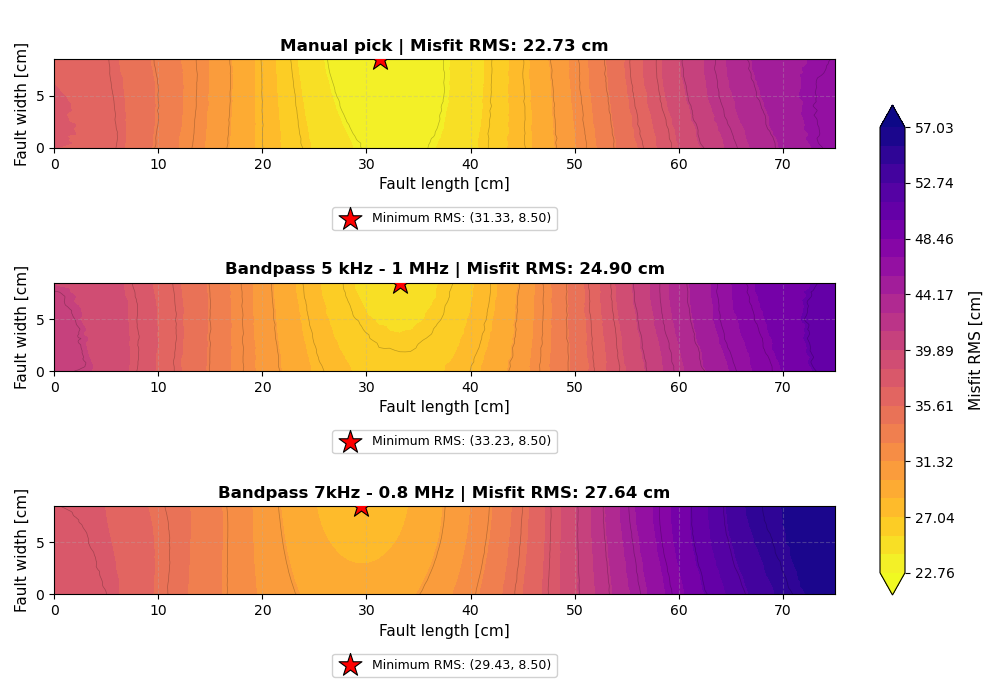

In [36]:
dataset_1 = evento_dict
dataset_2 = evento5
dataset_3 = evento7

plot_multi_event_xy_localization_cm(
    event_datasets=[dataset_1, dataset_2, dataset_3],
    titles_list=["Manual pick", "Bandpass 5 kHz - 1 MHz", "Bandpass 7kHz - 0.8 MHz"],
    ds_dimensions=ds_dimensions,
    AE_sensors_list=AE_sensors_list,
    channel_to_sensor_idx=channel_to_sensor_idx,
    v_u=v_u,
    v_l=v_l,
    v_g=v_g,
    vp_ms=assembly[block_key]['Vp [m/s]'],  # Velocità P in m/s
    x_limits=(0, 75),
    y_limits=(0, 8.5),
    colormap_name='plasma_r',
    output_dir='/mnt/scratch/oreios/Calibrations/AE/pzt_calibration_Alessia/'
)